# Гибридная система рекомендаций книг с нейросетевым ранжировщиком

### Выполнил: А.Любошенко

**Цель:** объединить классические модели из домашнего задания (Popularity, Content-based, Item-based CF, SVD) в гибридную систему рекомендаций книг, добавить расширенные признаки и нейросетевой ранжировщик и проверить, насколько это улучшает качество рекомендаций.

**Связь с домашним заданием.** Итоговый проект выполнен поверх ДЗ [Prototype_of_a_book_recommendation_service](https://github.com/Liuboshenko/Prototype_of_a_book_recommendation_service/tree/master). Нужный код из ДЗ перенесён сюда, чтобы ноутбук работал самостоятельно, а подробный EDA и разбор базовых моделей остались в ДЗ. Лучшая модель ДЗ - Item-CF с сортировкой по сумме "схожесть x оценка" (nDCG@10 = 0.2154 на test). Это ориентир, который гибрид должен превзойти.

**Этапы работы:**
1. Данные и короткая сводка EDA
2. Разбиение на train / validation / test и базовые модели из ДЗ
3. Расширенные признаки пользователей, книг и взаимодействий
4. Гибридная система: общий пул кандидатов, взвешенное усреднение, сегменты пользователей, баланс разнообразия и релевантности
5. Оценка и оптимизация: подбор весов, сравнение с отдельными моделями, анализ по сегментам
6. Нейросетевой ранжировщик и его интеграция в гибрид
7. Сквозной пайплайн от данных до рекомендаций
8. Выводы

**Главный результат:** итоговая система (общий пул кандидатов от пяти моделей -> нейросетевой ранжировщик -> MMR) даёт nDCG@10 = 0.2455 на том же test, что в ДЗ. Это на 14.0% лучше Item-CF, и выигрыш есть во всех сегментах пользователей с историей. Подробности - в разделе 8.

**Время работы:** полный прогон ноутбука занимает около 38 минут на 4 потоках CPU, GPU не нужен.

### Описание данных

| Файл | Ключевые колонки | Описание |
|---|---|---|
| `ratings.csv` | `book_id`, `user_id`, `rating` | Явные оценки пользователей по шкале 1-5 |
| `books.csv` | `id`, `book_id`, `original_title`, `title`, `authors`, `ratings_count` | Метаданные книг. `id` - внутренний id книги (на него ссылается `ratings.csv`), `book_id` - id книги на Goodreads |
| `book_tags.csv` | `goodreads_book_id`, `tag_id`, `count` | Сколько раз пользователи Goodreads положили книгу на полку-тег. Ссылается на `books.book_id` |
| `tags.csv` | `tag_id`, `tag_name` | Справочник названий тегов |

In [1]:
# Все импорты в одну ячейку

import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import svds

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

import surprise
from surprise import Dataset, Reader, SVD, accuracy

import torch
from torch import nn

from threadpoolctl import threadpool_info, threadpool_limits

np.random.seed(42)
torch.manual_seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

# Общие константы проекта
RANDOM_STATE = 42
DATA_DIR = 'data'
FIG_DIR = 'figures'
ARCHIVE_PATH = 'archive.zip'
DATASET_URL = 'https://www.kaggle.com/api/v1/datasets/download/zygmunt/goodbooks-10k'

print("Импорты выполнены успешно.")
print()
print(f"numpy:        {np.__version__}")
print(f"pandas:       {pd.__version__}")
print(f"scipy:        {scipy.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"surprise:     {surprise.__version__}")
print(f"torch:        {torch.__version__}")

Импорты выполнены успешно.

numpy:        2.5.4
pandas:       3.1.1
scipy:        1.18.1
scikit-learn: 1.9.1
surprise:     1.1.5
torch:        2.15.0+cpu


Ограничиваю число потоков для матричных операций (OpenBLAS в numpy и scipy) и для PyTorch. По умолчанию OpenBLAS занимает все ядра компьютера, а PyTorch - половину, и во время тяжёлых расчётов система перестаёт отвечать. Четырёх потоков достаточно: основная часть расчётов (разреженные матрицы, циклы по пользователям) и так выполняется в одном потоке, а результаты от числа потоков не зависят.

In [2]:
# Ограничиваем число потоков OpenBLAS и PyTorch, чтобы расчёты не занимали все ядра компьютера
MAX_THREADS = 4
threadpool_limits(limits=MAX_THREADS)
torch.set_num_threads(MAX_THREADS)

for pool in threadpool_info():
    print(f"{pool['internal_api']}: потоков {pool['num_threads']}")
print(f"torch: потоков {torch.get_num_threads()}")

openblas: потоков 4
openmp: потоков 4
openmp: потоков 4
openblas: потоков 4
torch: потоков 4


Проверяю, что данные на месте. Датасет не хранится в репозитории, поэтому ячейка умеет получить его сама: если нет папки `data/`, распаковывает `archive.zip`, а если нет и архива, скачивает его с Kaggle (вход в аккаунт не нужен). Заодно создаю папку `figures/` для графиков.

In [3]:
# Подготовка: скачивание и распаковка датасета при необходимости, папка для графиков
ratings_path = os.path.join(DATA_DIR, 'ratings.csv')

if os.path.exists(ratings_path):
    print(f"Данные уже распакованы в папку '{DATA_DIR}'")
else:
    if not os.path.exists(ARCHIVE_PATH):
        print(f"Архива нет, скачиваю датасет с Kaggle: {DATASET_URL}")
        urllib.request.urlretrieve(DATASET_URL, ARCHIVE_PATH)
        print(f"Скачано: {os.path.getsize(ARCHIVE_PATH) / 1024 / 1024:.1f} МБ")
    print(f"Распаковываю {ARCHIVE_PATH} в папку '{DATA_DIR}' ...")
    with zipfile.ZipFile(ARCHIVE_PATH) as archive:
        archive.extractall(DATA_DIR)
    print("Распаковка завершена")

os.makedirs(FIG_DIR, exist_ok=True)

print()
print("Файлы в папке с данными:")
for file_name in sorted(os.listdir(DATA_DIR)):
    size_mb = os.path.getsize(os.path.join(DATA_DIR, file_name)) / 1024 / 1024
    print(f"  {file_name:<20} {size_mb:>6.1f} МБ")

Данные уже распакованы в папку 'data'

Файлы в папке с данными:
  book_tags.csv          15.9 МБ
  books.csv               3.1 МБ
  ratings.csv            11.9 МБ
  sample_book.xml         0.0 МБ
  tags.csv                0.7 МБ
  to_read.csv             9.0 МБ


## 1. Данные и короткая сводка EDA

Подготовка данных полностью повторяет домашнее задание: те же файлы, та же чистка и та же связка идентификаторов. Разница в том, что шаги оформлены функциями, потому что в разделе 7 они войдут в сквозной пайплайн.

Подробный EDA сделан в ДЗ (раздел 1 ноутбука [Prototype_of_a_book_recommendation_service](https://github.com/Liuboshenko/Prototype_of_a_book_recommendation_service/tree/master)). Здесь - короткая сводка пяти главных наблюдений, на которые опирается итоговый проект.

### 1.1 Загрузка и чистка данных

Шаги из ДЗ (п. 1.2):
- в `ratings` у 2 278 пар (пользователь, книга) есть повторные оценки, оставляю первую запись. Времени в данных нет, поэтому понять, какая оценка актуальная, нельзя.
- в `book_tags` убираю 6 строк с `count = -1` и 8 повторов пары (книга, тег).
- `ratings.book_id` ссылается на `books.id`, а `book_tags.goodreads_book_id` - на `books.book_id`.

Все модели дальше работают с позициями в матрицах: строка = `user_id - 1`, столбец = `book_id - 1`.

In [4]:
# Загрузка и чистка данных: те же шаги, что в ДЗ (п. 1.1 - 1.2), оформлены функцией для пайплайна
def load_and_clean_data(data_dir, verbose=True):
    ratings_raw = pd.read_csv(os.path.join(data_dir, 'ratings.csv'))
    books = pd.read_csv(os.path.join(data_dir, 'books.csv'))
    tags = pd.read_csv(os.path.join(data_dir, 'tags.csv'))
    book_tags_raw = pd.read_csv(os.path.join(data_dir, 'book_tags.csv'))

    # Одна оценка на пару (пользователь, книга): из повторов оставляем первую запись
    ratings = ratings_raw.drop_duplicates(subset=['user_id', 'book_id'], keep='first').reset_index(drop=True)

    # В тегах убираем строки с count <= 0 и повторы пары (книга, тег), добавляем названия тегов
    book_tags = book_tags_raw[book_tags_raw['count'] > 0]
    book_tags = book_tags.drop_duplicates(subset=['goodreads_book_id', 'tag_id'], keep='first')
    book_tags_named = book_tags.merge(tags, on='tag_id', how='left').reset_index(drop=True)

    if verbose:
        print(f"ratings:   {len(ratings_raw):>7} -> {len(ratings):>7} строк "
              f"(удалено повторов {len(ratings_raw) - len(ratings)})")
        print(f"book_tags: {len(book_tags_raw):>7} -> {len(book_tags_named):>7} строк "
              f"(удалено {len(book_tags_raw) - len(book_tags_named)})")
        print(f"Пользователей: {ratings['user_id'].nunique()}, книг в оценках: {ratings['book_id'].nunique()}, "
              f"книг в каталоге: {len(books)}")
    return ratings, books, book_tags_named


ratings, books, book_tags_named = load_and_clean_data(DATA_DIR)

# Модели работают с позициями: строка матрицы = user_id - 1, столбец = book_id - 1
n_users = ratings['user_id'].max()
n_books = books['id'].max()
print(f"Размер матрицы пользователь x книга: {n_users} x {n_books}")
print()

# Связки id, проверенные в ДЗ
print(f"ratings.book_id найден в books.id:                  "
      f"{ratings['book_id'].isin(books['id']).mean() * 100:.1f}%")
print(f"book_tags.goodreads_book_id найден в books.book_id: "
      f"{book_tags_named['goodreads_book_id'].isin(books['book_id']).mean() * 100:.1f}%")

# Названия и авторы книг для вывода рекомендаций
book_info = books.set_index('id')[['title', 'authors']]

# Служебные теги (полки Goodreads), которые не описывают содержание книги. Список из ДЗ (п. 1.6)
SERVICE_TAGS = [
    # статус чтения
    'to-read', 'currently-reading', 're-read', 'dnf', 'did-not-finish', 'abandoned', 'maybe',
    'read-in-2011', 'read-in-2012', 'read-in-2013', 'read-in-2014', 'read-in-2015',
    'read-in-2016', 'read-in-2017', 'read-2014', 'read-2015', 'read-2016',
    # владение книгой и личная библиотека
    'owned', 'books-i-own', 'owned-books', 'i-own', 'own-it', 'have', 'my-books',
    'my-library', 'library', 'borrowed', 'to-buy', 'wish-list', 'default', 'books',
    # формат издания
    'kindle', 'ebook', 'ebooks', 'e-book', 'e-books',
    'audiobook', 'audiobooks', 'audio', 'audible', 'audio-book', 'audio-books',
    # личные списки и книжные клубы
    'favorites', 'favourites', 'favorite', 'favorite-books', 'all-time-favorites',
    '5-stars', 'book-club', 'bookclub',
]
print(f"Служебных тегов в списке: {len(SERVICE_TAGS)}")

ratings:    981756 ->  979478 строк (удалено повторов 2278)
book_tags:  999912 ->  999898 строк (удалено 14)
Пользователей: 53424, книг в оценках: 10000, книг в каталоге: 10000
Размер матрицы пользователь x книга: 53424 x 10000

ratings.book_id найден в books.id:                  100.0%
book_tags.goodreads_book_id найден в books.book_id: 100.0%
Служебных тегов в списке: 50


Чистка дала те же цифры, что в ДЗ: 979 478 оценок, 53 424 пользователя, 10 000 книг, связки id подтверждаются на 100%.

### 1.2 Короткая сводка EDA

Собираю пять обязательных наблюдений: распределение оценок, активность пользователей, популярность книг, самые частые теги и проблемы данных. Сначала ключевые цифры, потом все графики на одном рисунке.

In [5]:
# Ключевые цифры для сводки EDA (подробный разбор - в ДЗ, раздел 1)
RELEVANCE_THRESHOLD = 4     # книга считается понравившейся при оценке 4 и 5, как в ДЗ

rating_shares = ratings['rating'].value_counts(normalize=True).sort_index() * 100
user_activity = ratings.groupby('user_id').size()
book_activity = ratings.groupby('book_id').size()

tag_popularity = book_tags_named.groupby('tag_name')['count'].sum().sort_values(ascending=False)
is_service_tag = tag_popularity.index.isin(SERVICE_TAGS)

goodreads_popularity = books['ratings_count'].sort_values(ascending=False).values
top1_share = goodreads_popularity[:n_books // 100].sum() / goodreads_popularity.sum() * 100
top20_share = goodreads_popularity[:n_books // 5].sum() / goodreads_popularity.sum() * 100

print("1. Оценки")
for rating_value in rating_shares.index:
    print(f"   {rating_value}: {rating_shares[rating_value]:5.1f}%")
print(f"   средняя {ratings['rating'].mean():.2f}, доля 4 и 5: "
      f"{(ratings['rating'] >= RELEVANCE_THRESHOLD).mean() * 100:.1f}%")
print()
print("2. Пользователи")
cold_users = user_activity[user_activity < 5]
active_users = user_activity[user_activity >= 50]
print(f"   медиана оценок на пользователя: {user_activity.median():.0f}")
print(f"   меньше 5 оценок: {len(cold_users) / len(user_activity) * 100:.1f}% пользователей, "
      f"{cold_users.sum() / len(ratings) * 100:.1f}% оценок")
print(f"   50 оценок и больше: {len(active_users) / len(user_activity) * 100:.1f}% пользователей, "
      f"{active_users.sum() / len(ratings) * 100:.1f}% оценок")
print()
print("3. Книги")
print(f"   ровно 100 оценок в выборке: {(book_activity == 100).mean() * 100:.1f}% книг, больше 100: {(book_activity > 100).sum()}")
print(f"   на Goodreads топ-1% книг собирает {top1_share:.1f}% оценок, топ-20% - {top20_share:.1f}%")
print()
print("4. Теги")
print(f"   доля служебных тегов в сумме count: {tag_popularity[is_service_tag].sum() / tag_popularity.sum() * 100:.1f}%")
print(f"   самые частые содержательные: {', '.join(tag_popularity[~is_service_tag].head(5).index)}")
print()
print("5. Разреженность")
print(f"   заполнено {len(ratings) / (n_users * n_books) * 100:.3f}% матрицы пользователь x книга")

1. Оценки
   1:   2.0%
   2:   6.4%
   3:  25.3%
   4:  36.4%
   5:  29.8%
   средняя 3.86, доля 4 и 5: 66.2%

2. Пользователи
   медиана оценок на пользователя: 8
   меньше 5 оценок: 33.3% пользователей, 5.0% оценок
   50 оценок и больше: 9.2% пользователей, 42.8% оценок

3. Книги
   ровно 100 оценок в выборке: 62.5% книг, больше 100: 0
   на Goodreads топ-1% книг собирает 23.4% оценок, топ-20% - 69.6%

4. Теги
   доля служебных тегов в сумме count: 78.2%
   самые частые содержательные: fiction, fantasy, young-adult, classics, romance

5. Разреженность
   заполнено 0.183% матрицы пользователь x книга


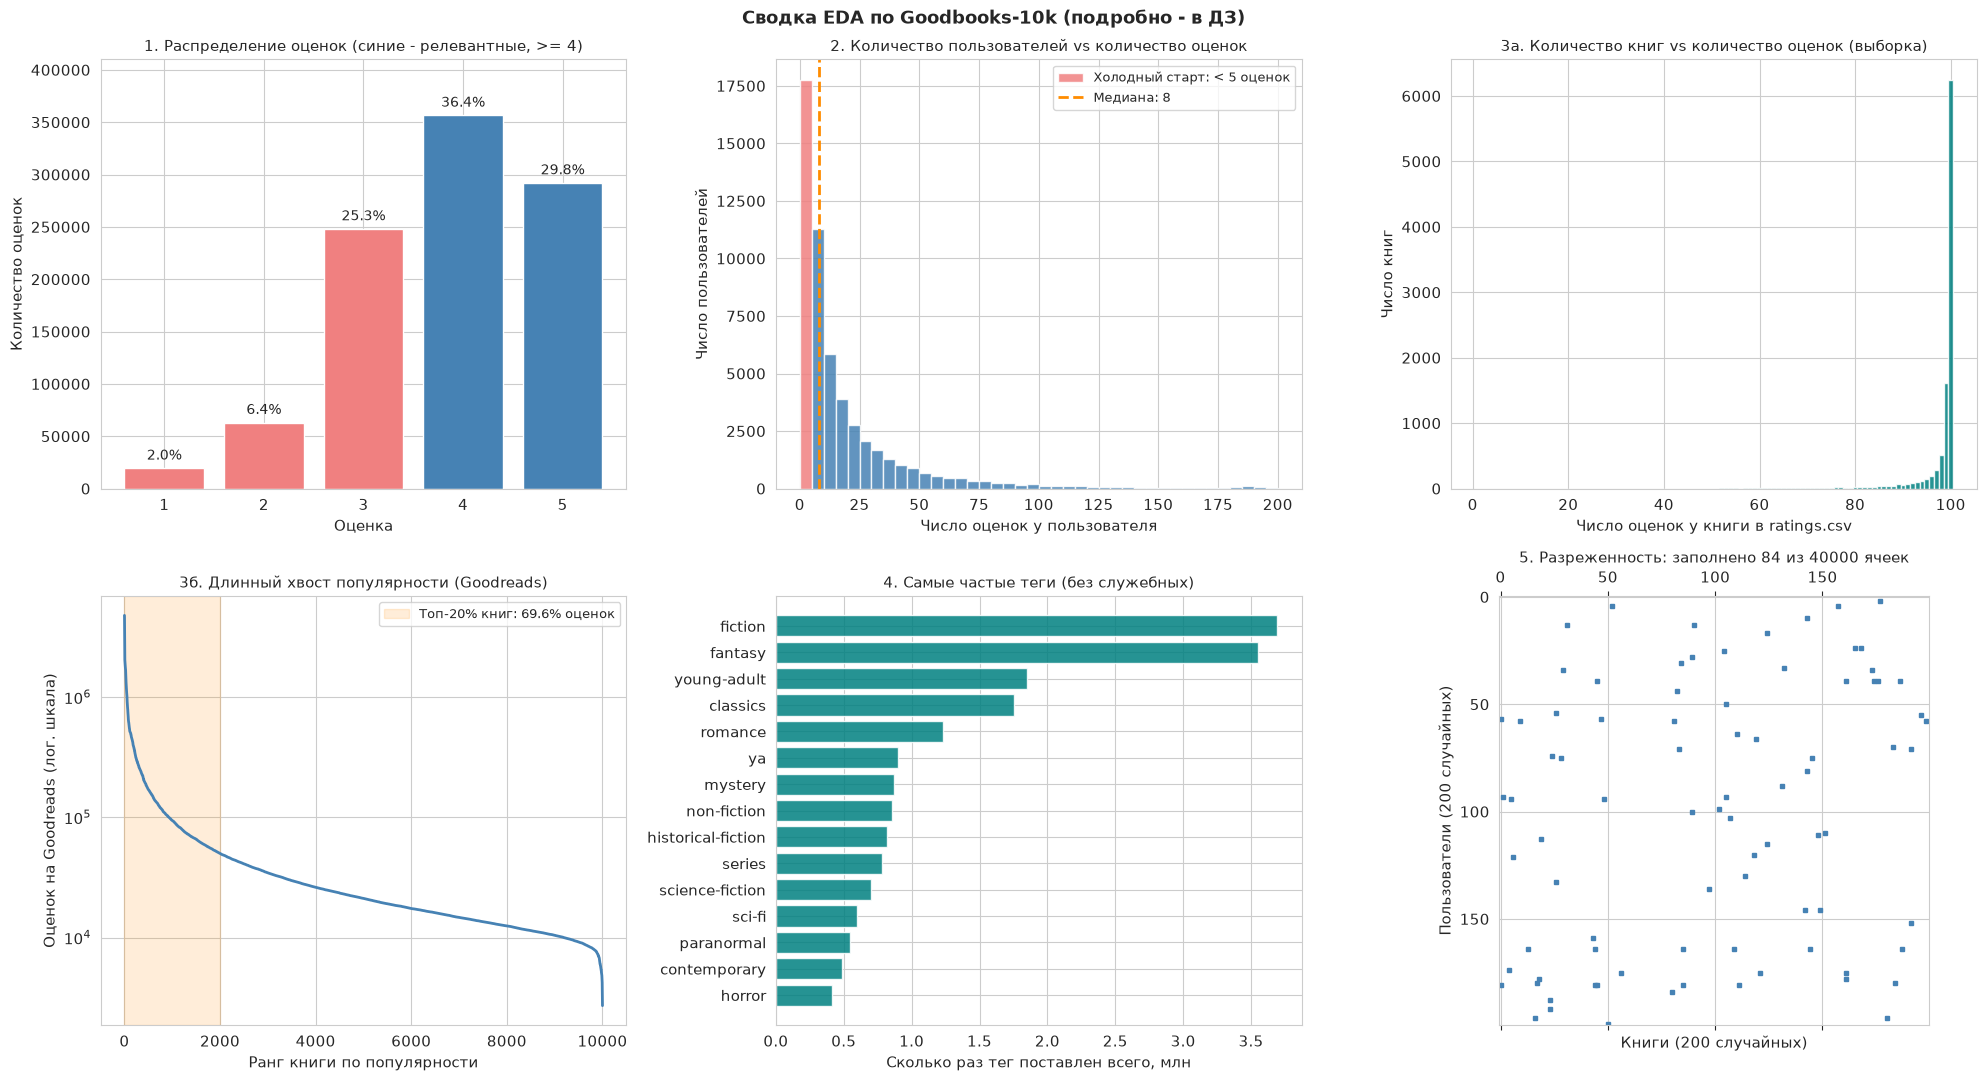

In [6]:
# Сводка EDA на одном рисунке: оценки, пользователи, книги, теги, разреженность
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Распределение оценок, цвет показывает порог релевантности
rating_counts = ratings['rating'].value_counts().sort_index()
bar_colors = []
for rating_value in rating_counts.index:
    if rating_value >= RELEVANCE_THRESHOLD:
        bar_colors.append('steelblue')
    else:
        bar_colors.append('lightcoral')
axes[0, 0].bar(rating_counts.index, rating_counts.values, color=bar_colors, edgecolor='white')
for rating_value in rating_counts.index:
    axes[0, 0].text(rating_value, rating_counts[rating_value] + 5000, f'{rating_shares[rating_value]:.1f}%',
                    ha='center', va='bottom', fontsize=10)
axes[0, 0].set_ylim(0, rating_counts.max() * 1.15)
axes[0, 0].set_xlabel('Оценка')
axes[0, 0].set_ylabel('Количество оценок')
axes[0, 0].set_title('1. Распределение оценок (синие - релевантные, >= 4)', fontsize=11)

# 2. Количество пользователей vs количество оценок, первый столбец - холодный старт
counts, bin_edges, patches = axes[0, 1].hist(user_activity, bins=range(0, 205, 5), color='steelblue',
                                             edgecolor='white', alpha=0.85)
patches[0].set_facecolor('lightcoral')
patches[0].set_label('Холодный старт: < 5 оценок')
axes[0, 1].axvline(user_activity.median(), color='darkorange', linestyle='--', linewidth=2,
                   label=f'Медиана: {user_activity.median():.0f}')
axes[0, 1].set_xlabel('Число оценок у пользователя')
axes[0, 1].set_ylabel('Число пользователей')
axes[0, 1].set_title('2. Количество пользователей vs количество оценок', fontsize=11)
axes[0, 1].legend(fontsize=9)

# 3. Количество книг vs количество оценок в нашей выборке: потолок в 100 оценок
axes[0, 2].hist(book_activity, bins=np.arange(0.5, 101.5, 1), color='teal', edgecolor='white', alpha=0.85)
axes[0, 2].set_xlabel('Число оценок у книги в ratings.csv')
axes[0, 2].set_ylabel('Число книг')
axes[0, 2].set_title('3а. Количество книг vs количество оценок (выборка)', fontsize=11)

# 4. Длинный хвост популярности по полным данным Goodreads
ranks = np.arange(1, n_books + 1)
axes[1, 0].plot(ranks, goodreads_popularity, color='steelblue', linewidth=2)
axes[1, 0].axvspan(1, n_books // 5, color='darkorange', alpha=0.15,
                   label=f'Топ-20% книг: {top20_share:.1f}% оценок')
axes[1, 0].set_yscale('log')
axes[1, 0].set_xlabel('Ранг книги по популярности')
axes[1, 0].set_ylabel('Оценок на Goodreads (лог. шкала)')
axes[1, 0].set_title('3б. Длинный хвост популярности (Goodreads)', fontsize=11)
axes[1, 0].legend(fontsize=9)

# 5. Самые частые содержательные теги
top_content_tags = tag_popularity[~is_service_tag].head(15)
tag_positions = np.arange(len(top_content_tags))[::-1]
axes[1, 1].barh(tag_positions, top_content_tags.values / 1e6, color='teal', edgecolor='white', alpha=0.85)
axes[1, 1].set_yticks(tag_positions)
axes[1, 1].set_yticklabels(top_content_tags.index)
axes[1, 1].set_xlabel('Сколько раз тег поставлен всего, млн')
axes[1, 1].set_title('4. Самые частые теги (без служебных)', fontsize=11)

# 6. Разреженность: случайный фрагмент 200 x 200 матрицы пользователь x книга
all_matrix = csr_matrix((np.ones(len(ratings)), (ratings['user_id'].values - 1, ratings['book_id'].values - 1)),
                        shape=(n_users, n_books))
fragment_rng = np.random.default_rng(RANDOM_STATE)
fragment = all_matrix[fragment_rng.choice(n_users, 200, replace=False)][:, fragment_rng.choice(n_books, 200, replace=False)]
axes[1, 2].spy(fragment, markersize=3, color='steelblue')
axes[1, 2].set_xlabel('Книги (200 случайных)')
axes[1, 2].set_ylabel('Пользователи (200 случайных)')
axes[1, 2].set_title(f'5. Разреженность: заполнено {fragment.nnz} из 40000 ячеек', fontsize=11)

plt.suptitle('Сводка EDA по Goodbooks-10k (подробно - в ДЗ)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_summary.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Пять наблюдений из EDA и что они значат для итогового проекта

1. **Оценки смещены вверх:** 66.2% оценок - это 4 и 5, средняя 3.86. Поэтому релевантной считается книга с оценкой >= 4, как в ДЗ.
2. **Активность пользователей очень неравномерная:** у 33.3% пользователей меньше 5 оценок (холодный старт), а 9.2% активных пользователей дают 42.8% всех оценок. **Для проекта:** разделять пользователей по типам (новые, с короткой историей, активные) и давать им разные стратегии.
3. **Популярность книг:** в нашей выборке у книги не больше 100 оценок (62.5% книг - ровно 100), поэтому сигнал популярности стёрт. На Goodreads при этом настоящий длинный хвост: топ-1% книг собирает 23.4% оценок, топ-20% - 69.6%. **Для проекта:** популярность по нашим оценкам почти ничего не даёт (в ДЗ nDCG@10 = 0.0012), но как признак книги можно взять число оценок на Goodreads.
4. **Теги:** 78.2% суммарного `count` - служебные полки (`to-read`, `owned` и т.д.), а содержательные теги - это жанры: fiction, fantasy, young-adult, classics, romance. **Для проекта:** по содержательным тегам можно построить тематические категории книг.
5. **Проблемы данных:** главная - разреженность (заполнено 0.18% матрицы), дальше холодный старт, смещение оценок и стёртая популярность. **Для проекта:** одна модель покрывает не всех пользователей и не все книги, поэтому кандидатов нужно собирать из нескольких моделей.

## 2. Разбиение и базовые модели из ДЗ

В этом разделе переношу из ДЗ всё, на чём строится гибрид: разбиение, метрики и пять базовых моделей. В конце проверяю, что на том же test метрики совпадают с ДЗ. Если совпадут, значит перенос сделан правильно и с результатами ДЗ можно честно сравнивать.

### 2.1 Разбиение на train, validation и test

- **test** - тот же, что в ДЗ: случайные 20% оценок, `random_state=42`. Поэтому все метрики итогового проекта можно напрямую сравнивать с ДЗ.
- **validation** - новое. Это 20% от оставшегося train (`train_full`). Гибрид нужно настраивать: подбирать веса моделей и обучать нейросетевой ранжировщик. Если делать это на test, оценка качества станет нечестной. Поэтому настройка идёт на validation, а test используется только для итоговой оценки.

Схема обучения:
- для настройки модели учатся на `train_fit` (64% оценок) и проверяются на `valid` (16%),
- для итоговой оценки модели учатся заново на `train_full` (80%) и проверяются на `test` (20%).

Времени в данных нет, поэтому разбиение случайное, как и в ДЗ.

In [7]:
# Разбиение: test как в ДЗ, validation выделяется из train
def split_data(ratings, verbose=True):
    train_full, test = train_test_split(ratings, test_size=0.2, random_state=RANDOM_STATE)
    train_full = train_full.reset_index(drop=True)
    test = test.reset_index(drop=True)
    train_fit, valid = train_test_split(train_full, test_size=0.2, random_state=RANDOM_STATE)
    train_fit = train_fit.reset_index(drop=True)
    valid = valid.reset_index(drop=True)
    if verbose:
        for part_name, part in [('train_full', train_full), ('test', test), ('train_fit', train_fit), ('valid', valid)]:
            print(f"{part_name:<11} {len(part):>7} оценок ({len(part) / len(ratings) * 100:4.1f}%), "
                  f"средняя {part['rating'].mean():.3f}, доля >= 4: "
                  f"{(part['rating'] >= RELEVANCE_THRESHOLD).mean() * 100:.1f}%")
    return train_full, test, train_fit, valid


def get_eval_users(train_df, eval_df):
    # Релевантные книги пользователя - книги из eval_df с оценкой >= порога.
    # Оцениваем пользователей, у которых есть история в train_df и хотя бы одна релевантная книга
    relevant = eval_df[eval_df['rating'] >= RELEVANCE_THRESHOLD].groupby('user_id')['book_id'].apply(set)
    train_users = set(train_df['user_id'])
    eval_user_ids = []
    for user_id in relevant.index:
        if user_id in train_users:
            eval_user_ids.append(user_id)
    return relevant, eval_user_ids


train_full, test, train_fit, valid = split_data(ratings)
print()

# Проверка на утечку: одна пара (пользователь, книга) не должна попасть в две части
pairs_fit = set(zip(train_fit['user_id'], train_fit['book_id']))
pairs_valid = set(zip(valid['user_id'], valid['book_id']))
pairs_test = set(zip(test['user_id'], test['book_id']))
print(f"Общих пар: train_fit и valid {len(pairs_fit & pairs_valid)}, train_fit и test {len(pairs_fit & pairs_test)}, "
      f"valid и test {len(pairs_valid & pairs_test)}")
print()

valid_relevant, valid_user_ids = get_eval_users(train_fit, valid)
test_relevant, test_user_ids = get_eval_users(train_full, test)
relevant_counts = []
for user_id in valid_user_ids:
    relevant_counts.append(len(valid_relevant[user_id]))
print(f"Пользователей для оценки на valid: {len(valid_user_ids)}, "
      f"релевантных книг на пользователя в среднем {np.mean(relevant_counts):.2f}")
print(f"Пользователей для оценки на test:  {len(test_user_ids)} (в ДЗ было 34288)")

train_full   783582 оценок (80.0%), средняя 3.857, доля >= 4: 66.3%
test         195896 оценок (20.0%), средняя 3.855, доля >= 4: 66.1%
train_fit    626865 оценок (64.0%), средняя 3.857, доля >= 4: 66.3%
valid        156717 оценок (16.0%), средняя 3.855, доля >= 4: 66.2%



Общих пар: train_fit и valid 0, train_fit и test 0, valid и test 0



Пользователей для оценки на valid: 30935, релевантных книг на пользователя в среднем 3.32
Пользователей для оценки на test:  34288 (в ДЗ было 34288)


#### Test совпадает с ДЗ, validation честно отделена

- `train_full` и `test` - ровно те же 783 582 и 195 896 оценок, что в ДЗ, и для оценки на test остаются те же 34 288 пользователей.
- Из `train_full` выделено 156 717 оценок в `valid`. Средняя оценка и доля оценок >= 4 во всех частях почти одинаковые, общих пар (пользователь, книга) между частями нет.
- На validation 30 935 пользователей с историей и хотя бы одной релевантной книгой. На них будут подбираться веса гибрида и обучаться ранжировщик.
- У validation есть цена: модели для настройки учатся на 64% оценок, а не на 80%. У пользователя в среднем меньше истории, поэтому метрики на validation будут ниже, чем на test. Сравнивать между собой нужно варианты на одной и той же части.

### 2.2 Метрики Precision@K, Recall@K и nDCG@K

Функции те же, что в ДЗ (п. 5.2): бинарная релевантность, дисконт `1 / log2(p + 1)` и IDCG по `min(K, число релевантных)`. Быстро перепроверяю их на игрушечном примере.

In [8]:
# Метрики качества top-N для одного пользователя (из ДЗ, п. 5.2)
def precision_at_k(recommended, relevant, k):
    hits = 0
    for book_id in recommended[:k]:
        if book_id in relevant:
            hits += 1
    return hits / k


def recall_at_k(recommended, relevant, k):
    hits = 0
    for book_id in recommended[:k]:
        if book_id in relevant:
            hits += 1
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    # DCG: релевантная книга на позиции p (считая с 1) даёт вклад 1 / log2(p + 1)
    dcg = 0.0
    for position, book_id in enumerate(recommended[:k], start=1):
        if book_id in relevant:
            dcg += 1 / np.log2(position + 1)
    # IDCG: идеальный список, все релевантные книги стоят в самом начале
    idcg = 0.0
    for position in range(1, min(len(relevant), k) + 1):
        idcg += 1 / np.log2(position + 1)
    return dcg / idcg


# Игрушечный пример: 3 релевантные книги, релевантные стоят на позициях 2 и 5
toy_relevant = {20, 50, 70}
toy_list = [10, 20, 30, 40, 50]
manual_ndcg = (1 / np.log2(3) + 1 / np.log2(6)) / (1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4))
print(f"P@5 = {precision_at_k(toy_list, toy_relevant, 5):.3f} (вручную 0.400)")
print(f"R@5 = {recall_at_k(toy_list, toy_relevant, 5):.3f} (вручную 0.667)")
print(f"nDCG@5 = {ndcg_at_k(toy_list, toy_relevant, 5):.4f} (вручную {manual_ndcg:.4f})")

P@5 = 0.400 (вручную 0.400)
R@5 = 0.667 (вручную 0.667)
nDCG@5 = 0.4776 (вручную 0.4776)


Функции дают те же значения, что ручной расчёт. Перехожу к моделям.

### 2.3 Пять базовых моделей

Переношу из ДЗ пять моделей. У всех один интерфейс: **для пользователя модель выдаёт скор каждой из 10 000 книг**, а рекомендации - это книги с наибольшим скором без тех, что пользователь уже оценил. Такой интерфейс нужен дальше: из этих скоров собирается общий пул кандидатов, они же становятся признаками.

| Модель | Скор книги для пользователя | Из ДЗ |
|---|---|---|
| Popularity | Место книги в рейтинге по среднему (только книги с 50+ оценками) | п. 2.2 |
| Content-based | Косинусная близость TF-IDF книги и профиля пользователя (сумма TF-IDF его книг с оценкой >= 4) | п. 2.3, 5.5 |
| Item-CF | Сумма "схожесть x оценка" по K = 20 самым похожим книгам из истории | п. 3 |
| SVD | Предсказанный рейтинг `mu + b_u + b_i + q_i * p_u` | п. 4 |
| PureSVD | Разложение матрицы "прочитал / не прочитал" на 50 факторов | п. 5.6 |

Модели обучаются функцией `fit_base_models(train_df)`, поэтому их можно одинаково обучить на `train_fit` и на `train_full`. TF-IDF от оценок не зависит, его строю один раз.

In [9]:
# TF-IDF профили книг: название + содержательные теги (из ДЗ, п. 2.3). От оценок не зависит
def build_content_matrix(books, book_tags_named):
    # Соответствие id книги: внутренний id (как в ratings.csv) и id на Goodreads (как в book_tags.csv)
    book_id_map = books[['id', 'book_id']].rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})
    content_tags = book_tags_named[~book_tags_named['tag_name'].isin(SERVICE_TAGS)]
    content_tags = content_tags.merge(book_id_map, on='goodreads_book_id', how='inner')
    # Дефис внутри тега заменяем на подчёркивание, чтобы тег остался одним токеном
    content_tags['tag_token'] = content_tags['tag_name'].str.replace('-', '_')
    tags_text = content_tags.groupby('book_id')['tag_token'].apply(' '.join)

    # Название: original_title, а если он пустой - title
    book_titles = books['original_title'].copy()
    empty_title_mask = book_titles.isnull() | (book_titles.str.strip() == '')
    book_titles.loc[empty_title_mask] = books.loc[empty_title_mask, 'title']

    content_books = pd.DataFrame({'book_id': books['id'], 'profile_title': book_titles})
    content_books['profile'] = content_books['profile_title'] + ' ' + content_books['book_id'].map(tags_text).fillna('')
    content_books = content_books.sort_values('book_id').reset_index(drop=True)

    tfidf_vectorizer = TfidfVectorizer(stop_words='english')
    tfidf_matrix = tfidf_vectorizer.fit_transform(content_books['profile'])
    return tfidf_matrix, content_books['book_id'].values


tfidf_matrix, tfidf_book_ids = build_content_matrix(books, book_tags_named)
print(f"TF-IDF матрица: {tfidf_matrix.shape[0]} книг x {tfidf_matrix.shape[1]} терминов, "
      f"тип {type(tfidf_matrix).__name__}")
print(f"Строки идут по порядку book_id, позиция = book_id - 1: "
      f"{(tfidf_book_ids == np.arange(1, n_books + 1)).all()}")

TF-IDF матрица: 10000 книг x 40389 терминов, тип csr_matrix
Строки идут по порядку book_id, позиция = book_id - 1: True


In [10]:
# Обучение всех базовых моделей на заданном train
MIN_RATINGS = 50          # порог Popularity из ДЗ
ITEM_CF_K = 20            # число соседей Item-CF из ДЗ
PURE_SVD_FACTORS = 50     # число факторов PureSVD из ДЗ


def fit_base_models(train_df, verbose=True, n_users_total=None):
    # n_users_total - число строк в матрицах пользователей. По умолчанию столько же, сколько в ноутбуке.
    # Пайплайн раздела 7 передаёт своё число: в новых данных могут быть пользователи с новыми id
    if n_users_total is None:
        n_users_total = n_users
    models = {}
    timings = {}

    # Матрица оценок пользователь x книга и бинарная матрица "прочитал"
    rows = train_df['user_id'].values - 1
    cols = train_df['book_id'].values - 1
    user_item = csr_matrix((train_df['rating'].values.astype(np.float64), (rows, cols)), shape=(n_users_total, n_books))
    rated_matrix = user_item.copy()
    rated_matrix.data[:] = 1
    models['user_item'] = user_item
    models['rated_matrix'] = rated_matrix

    # Средняя оценка пользователя (запасной прогноз Item-CF) и глобальное среднее
    global_mean = train_df['rating'].mean()
    user_counts = np.diff(user_item.indptr)
    user_sums = np.asarray(user_item.sum(axis=1)).flatten()
    user_mean = np.full(n_users_total, global_mean)
    has_history = user_counts > 0
    user_mean[has_history] = user_sums[has_history] / user_counts[has_history]
    models['global_mean'] = global_mean
    models['user_mean'] = user_mean

    # 1. Popularity: средний рейтинг среди книг с числом оценок >= MIN_RATINGS
    start_time = time.perf_counter()
    book_stats = train_df.groupby('book_id').agg(n_ratings=('rating', 'count'), mean_rating=('rating', 'mean'))
    popular = book_stats[book_stats['n_ratings'] >= MIN_RATINGS]
    popular = popular.sort_values(['mean_rating', 'n_ratings'], ascending=False)
    # Скор = место с конца: у первой книги самый большой, у книг ниже порога 0
    popularity_score = np.zeros(n_books)
    popular_positions = popular.index.values - 1
    popularity_score[popular_positions] = np.arange(len(popular), 0, -1)
    models['popularity_score'] = popularity_score
    timings['Popularity'] = time.perf_counter() - start_time

    # 2. Item-CF: косинусная схожесть книг по векторам оценок, диагональ убираем
    start_time = time.perf_counter()
    item_similarity = cosine_similarity(user_item.T, dense_output=False).tocsr()
    item_similarity.setdiag(0)
    item_similarity.eliminate_zeros()
    models['item_similarity'] = item_similarity
    timings['Item-CF'] = time.perf_counter() - start_time

    # 3. SVD из surprise, параметры переводим в порядок наших позиций
    start_time = time.perf_counter()
    trainset = Dataset.load_from_df(train_df[['user_id', 'book_id', 'rating']],
                                    Reader(rating_scale=(1, 5))).build_full_trainset()
    svd_model = SVD(random_state=RANDOM_STATE)
    svd_model.fit(trainset)
    svd_pu = np.zeros((n_users_total, svd_model.n_factors))
    svd_bu = np.zeros(n_users_total)
    for inner_user_id in range(trainset.n_users):
        user_position = trainset.to_raw_uid(inner_user_id) - 1
        svd_pu[user_position] = svd_model.pu[inner_user_id]
        svd_bu[user_position] = svd_model.bu[inner_user_id]
    svd_qi = np.zeros((n_books, svd_model.n_factors))
    svd_bi = np.zeros(n_books)
    for inner_book_id in range(trainset.n_items):
        book_position = trainset.to_raw_iid(inner_book_id) - 1
        svd_qi[book_position] = svd_model.qi[inner_book_id]
        svd_bi[book_position] = svd_model.bi[inner_book_id]
    models['svd_model'] = svd_model
    models['svd_mean'] = trainset.global_mean
    models['svd_pu'] = svd_pu
    models['svd_bu'] = svd_bu
    models['svd_qi'] = svd_qi
    models['svd_bi'] = svd_bi
    timings['SVD'] = time.perf_counter() - start_time

    # 4. PureSVD: разложение бинарной матрицы "прочитал / не прочитал"
    start_time = time.perf_counter()
    user_factors, singular_values, book_factors = svds(rated_matrix, k=PURE_SVD_FACTORS, rng=RANDOM_STATE)
    models['pure_svd_users'] = user_factors * singular_values
    models['pure_svd_books'] = book_factors
    timings['PureSVD'] = time.perf_counter() - start_time

    if verbose:
        print(f"Обучено на {len(train_df)} оценках, пользователей с историей {has_history.sum()}")
        for model_name, seconds in timings.items():
            print(f"  {model_name:<11} {seconds:6.1f} с")
    return models


print("Модели для настройки (train_fit):")
models_fit = fit_base_models(train_fit)
print()
print("Модели для итоговой оценки (train_full):")
models_full = fit_base_models(train_full)

Модели для настройки (train_fit):


Обучено на 626865 оценках, пользователей с историей 51943
  Popularity     0.0 с
  Item-CF        0.4 с
  SVD           10.0 с
  PureSVD        0.9 с

Модели для итоговой оценки (train_full):


Обучено на 783582 оценках, пользователей с историей 52985
  Popularity     0.0 с
  Item-CF        0.6 с
  SVD           12.2 с
  PureSVD        0.9 с


Теперь функции, которые для пользователя считают скоры всех книг. Item-CF я немного ускорил по сравнению с ДЗ. Если у пользователя не больше K = 20 книг, то "K самых похожих книг из истории" - это просто вся история. Тогда сумма "схожесть x оценка" равна произведению вектора его оценок на строки матрицы схожестей, и сортировка не нужна. Таких пользователей большинство (медиана истории - 7 книг). Для остальных выбираю K самых похожих книг, как в ДЗ. Сразу проверяю, что ускоренная версия даёт те же числа, что функция из ДЗ.

In [11]:
# Скоры всех книг для пользователя по каждой модели
def score_item_cf(models, user_id):
    # Возвращает сумму "схожесть x оценка" по K самым похожим книгам из истории (скор для top-N),
    # сумму схожестей этих K книг и прогноз оценки (взвешенное среднее), как в ДЗ (п. 3.3 - 3.4)
    user_row = models['user_item'][user_id - 1]
    rated_positions = user_row.indices
    rated_values = user_row.data
    if len(rated_positions) == 0:
        return np.zeros(n_books), np.zeros(n_books), np.full(n_books, models['global_mean'])

    # Схожесть каждой книги истории со всеми книгами: строки - книги истории, столбцы - все книги
    block = models['item_similarity'][rated_positions].toarray()
    if len(rated_positions) <= ITEM_CF_K:
        # Вся история и есть K самых похожих: сортировка не нужна
        scores = rated_values @ block
        similarity_sums = block.sum(axis=0)
    else:
        # Для каждой книги берём K самых похожих книг из истории
        top_k_rows = np.argpartition(-block, ITEM_CF_K - 1, axis=0)[:ITEM_CF_K]
        top_k_similarities = np.take_along_axis(block, top_k_rows, axis=0)
        scores = (top_k_similarities * rated_values[top_k_rows]).sum(axis=0)
        similarity_sums = top_k_similarities.sum(axis=0)

    predictions = np.full(n_books, models['user_mean'][user_id - 1])
    has_neighbors = similarity_sums > 0
    predictions[has_neighbors] = scores[has_neighbors] / similarity_sums[has_neighbors]
    return scores, similarity_sums, predictions


def score_content(models, user_id):
    # Профиль пользователя - сумма TF-IDF векторов книг с оценкой >= 4 (если таких нет - всех книг).
    # Скор - косинусная близость профиля и TF-IDF вектора книги (строки TF-IDF уже нормированы)
    user_row = models['user_item'][user_id - 1]
    profile_positions = user_row.indices[user_row.data >= RELEVANCE_THRESHOLD]
    if len(profile_positions) == 0:
        profile_positions = user_row.indices
    if len(profile_positions) == 0:
        return np.zeros(n_books)
    profile = np.asarray(tfidf_matrix[profile_positions].sum(axis=0)).flatten()
    profile = profile / np.linalg.norm(profile)
    return tfidf_matrix @ profile


def score_svd(models, user_id):
    # Предсказанный рейтинг mu + b_u + b_i + q_i * p_u (без обрезки до шкалы 1-5, как в ДЗ п. 4.4)
    user_position = user_id - 1
    return (models['svd_mean'] + models['svd_bu'][user_position] + models['svd_bi']
            + models['svd_qi'] @ models['svd_pu'][user_position])


def score_pure_svd(models, user_id):
    return models['pure_svd_users'][user_id - 1] @ models['pure_svd_books']


def get_model_scores(models, user_id):
    # Скоры всех книг по всем базовым моделям
    item_cf_scores, item_cf_similarity_sums, item_cf_predictions = score_item_cf(models, user_id)
    return {
        'Popularity': models['popularity_score'],
        'Content-based': score_content(models, user_id),
        'Item-CF': item_cf_scores,
        'SVD': score_svd(models, user_id),
        'PureSVD': score_pure_svd(models, user_id),
    }


def top_n_books(scores, rated_positions, n):
    # Книги с наибольшим скором, кроме уже оценённых. Сортировка устойчивая, как в ДЗ
    ranking_values = scores.copy()
    ranking_values[rated_positions] = -np.inf
    top_positions = np.argsort(-ranking_values, kind='stable')[:n]
    return (top_positions + 1).tolist()


# Проверка ускоренного Item-CF: сравниваю с функцией из ДЗ (п. 3.3) на 300 случайных пользователях
def score_item_cf_homework(models, user_id):
    user_row = models['user_item'][user_id - 1]
    rated_positions = user_row.indices
    rated_values = user_row.data
    similarities = models['item_similarity'][rated_positions].toarray().T
    top_k_order = np.argsort(-similarities, axis=1)[:, :ITEM_CF_K]
    top_k_similarities = np.take_along_axis(similarities, top_k_order, axis=1)
    return (top_k_similarities * rated_values[top_k_order]).sum(axis=1)


check_rng = np.random.default_rng(RANDOM_STATE)
check_user_ids = check_rng.choice(np.array(test_user_ids), size=300, replace=False)
max_difference = 0.0
n_long_history = 0
for check_user_id in check_user_ids:
    fast_scores = score_item_cf(models_full, check_user_id)[0]
    homework_scores = score_item_cf_homework(models_full, check_user_id)
    max_difference = max(max_difference, np.abs(fast_scores - homework_scores).max())
    if models_full['user_item'][check_user_id - 1].nnz > ITEM_CF_K:
        n_long_history += 1
print(f"Максимальная разница скоров Item-CF с функцией из ДЗ: {max_difference:.2e} "
      f"(300 пользователей, из них {n_long_history} с историей длиннее K)")

# Скорость расчёта скоров всех моделей для одного пользователя
start_time = time.perf_counter()
for check_user_id in check_user_ids:
    check_scores = get_model_scores(models_full, check_user_id)
print(f"Скоры 5 моделей для одного пользователя: {(time.perf_counter() - start_time) / len(check_user_ids) * 1000:.1f} мс")

Максимальная разница скоров Item-CF с функцией из ДЗ: 1.42e-14 (300 пользователей, из них 90 с историей длиннее K)


Скоры 5 моделей для одного пользователя: 7.2 мс


Ускоренная Item-CF совпадает с функцией ДЗ с точностью до ошибок округления (1.4e-14), в том числе у пользователей с историей длиннее K. Скоры всех пяти моделей для одного пользователя считаются за 7 мс, поэтому оценка на всех 34 288 пользователях test занимает минуты, а не часы.

### 2.4 Проверка: метрики базовых моделей совпадают с ДЗ

Обучаю модели на `train_full` и считаю метрики на тех же 34 288 пользователях test, что в ДЗ. Результаты сохраняю: в разделе 5 они станут строками сводной таблицы, с которыми сравнивается гибрид. Это самая долгая ячейка раздела, около 6 минут: для каждого из 34 288 пользователей пять моделей оценивают все 10 000 книг.

In [12]:
# Метрики базовых моделей на test (модели обучены на train_full)
K_VALUES = [5, 10]
BASE_MODEL_NAMES = ['Popularity', 'Content-based', 'Item-CF', 'SVD', 'PureSVD']

# nDCG@10 на test из ДЗ (сводная таблица п. 5.5 и проверка п. 5.6)
HOMEWORK_NDCG_10 = {'Popularity': 0.0012, 'Content-based': 0.1413, 'Item-CF': 0.2154, 'SVD': 0.0011, 'PureSVD': 0.0389}


def evaluate_base_models(models, user_ids, relevant_books):
    rows = []
    for user_id in user_ids:
        rated_positions = models['user_item'][user_id - 1].indices
        model_scores = get_model_scores(models, user_id)
        relevant = relevant_books[user_id]
        for model_name in BASE_MODEL_NAMES:
            recommended = top_n_books(model_scores[model_name], rated_positions, max(K_VALUES))
            for k in K_VALUES:
                rows.append({
                    'user_id': user_id,
                    'model': model_name,
                    'k': k,
                    'precision': precision_at_k(recommended, relevant, k),
                    'recall': recall_at_k(recommended, relevant, k),
                    'ndcg': ndcg_at_k(recommended, relevant, k),
                })
    return pd.DataFrame(rows)


start_time = time.perf_counter()
base_test_metrics = evaluate_base_models(models_full, test_user_ids, test_relevant)
print(f"Оценено пользователей: {base_test_metrics['user_id'].nunique()}, "
      f"время {(time.perf_counter() - start_time) / 60:.1f} мин")
print()

base_test_summary = base_test_metrics[base_test_metrics['k'] == 10].groupby('model')[['precision', 'recall', 'ndcg']].mean()
print(f"{'Модель':<15} {'P@10':>7} {'R@10':>7} {'nDCG@10':>8} {'nDCG@10 в ДЗ':>13} {'разница':>9}")
print('-' * 64)
for model_name in BASE_MODEL_NAMES:
    model_row = base_test_summary.loc[model_name]
    homework_value = HOMEWORK_NDCG_10[model_name]
    print(f"{model_name:<15} {model_row['precision']:>7.4f} {model_row['recall']:>7.4f} {model_row['ndcg']:>8.4f} "
          f"{homework_value:>13.4f} {model_row['ndcg'] - homework_value:>+9.4f}")

Оценено пользователей: 34288, время 6.2 мин

Модель             P@10    R@10  nDCG@10  nDCG@10 в ДЗ   разница
----------------------------------------------------------------
Popularity       0.0006  0.0017   0.0012        0.0012   -0.0000
Content-based    0.0559  0.1691   0.1413        0.1413   -0.0000
Item-CF          0.0817  0.2502   0.2154        0.2154   -0.0000
SVD              0.0006  0.0017   0.0011        0.0011   -0.0000
PureSVD          0.0258  0.0397   0.0389        0.0389   -0.0000


#### Перенос моделей из ДЗ корректный

- nDCG@10 всех пяти моделей на test совпадает с ДЗ с точностью до округления. Значит, данные, разбиение, модели и метрики перенесены без ошибок, и дальше гибрид можно сравнивать с результатами ДЗ.
- Расклад сил тот же: **Item-CF** (nDCG@10 = 0.215) заметно впереди, за ней **Content-based** (0.141), затем **PureSVD** (0.039). **Popularity** и **SVD** по ранжированию на уровне случайных.
- Ускоренный Item-CF даёт те же скоры, что функция из ДЗ (разница на уровне ошибки округления), а скоры всех пяти моделей для одного пользователя считаются за несколько миллисекунд.

**Ориентир для гибрида:** Item-CF с nDCG@10 = 0.2154 на test. Гибрид имеет смысл, только если он её превзойдёт.

## 3. Расширенные признаки

По заданию на этом этапе нужны расширенные признаки трёх видов:
- **пользователей:** средний рейтинг, количество оценок, активность,
- **книг:** популярность, разнообразие оценок, тематические категории,
- **взаимодействий:** схожесть книги с историей пользователя.

Признаки по оценкам считаются только по тому train, на котором обучены модели: по `train_fit` для настройки на validation и по `train_full` для итоговой оценки на test. Иначе в признаки просочились бы оценки, которые модель должна угадать. Поэтому все признаки строятся функциями от train.

В конце раздела проверяю на validation, какие признаки действительно помогают отличать книги, которые пользователь прочитает и оценит высоко. Это нужно, чтобы признаки были осмысленными, а не просто многочисленными.

### 3.1 Признаки пользователей

| Признак | Что означает |
|---|---|
| `user_log_n_ratings` | Число оценок в train (в логарифме: от 1 до 138 оценок разница в сотню раз) - активность пользователя |
| `user_mean_rating` | Средний рейтинг: насколько пользователь щедрый или строгий |
| `user_std_rating` | Разброс оценок: ставит ли он всем одно и то же или различает книги |
| `user_high_share` | Доля оценок 4 и 5 |
| `user_segment` | Тип пользователя по активности: новый (0 оценок), короткая история (1-4), средняя (5-19), активный (20+). Нужен для разделения пользователей в гибриде |

Границы сегментов взяты из ДЗ: при 1-4 оценках Item-CF уже работает (nDCG@10 = 0.19), а у пользователей с 20+ оценками история богатая.

Признаки пользователей по train_fit:


,count,mean,std,min,25%,50%,75%,max
user_n_ratings,53424.0,11.73,16.88,0.0,2.00,5.00,14.00,138.00
user_log_n_ratings,53424.0,1.98,1.03,0.0,1.10,1.79,2.71,4.93
user_mean_rating,53424.0,3.88,0.67,1.0,3.50,3.94,4.33,5.00
user_std_rating,53424.0,0.64,0.46,0.0,0.25,0.71,0.93,2.83
user_high_share,53424.0,0.67,0.30,0.0,0.50,0.70,1.00,1.00


Сегменты пользователей:


,по train_fit,по train_full,"доля по train_full, %"
user_segment,,,
Новый (0),1481,439,0.8
Короткая история (1-4),23102,20815,39.0
Средняя (5-19),19376,20247,37.9
Активный (20+),9465,11923,22.3


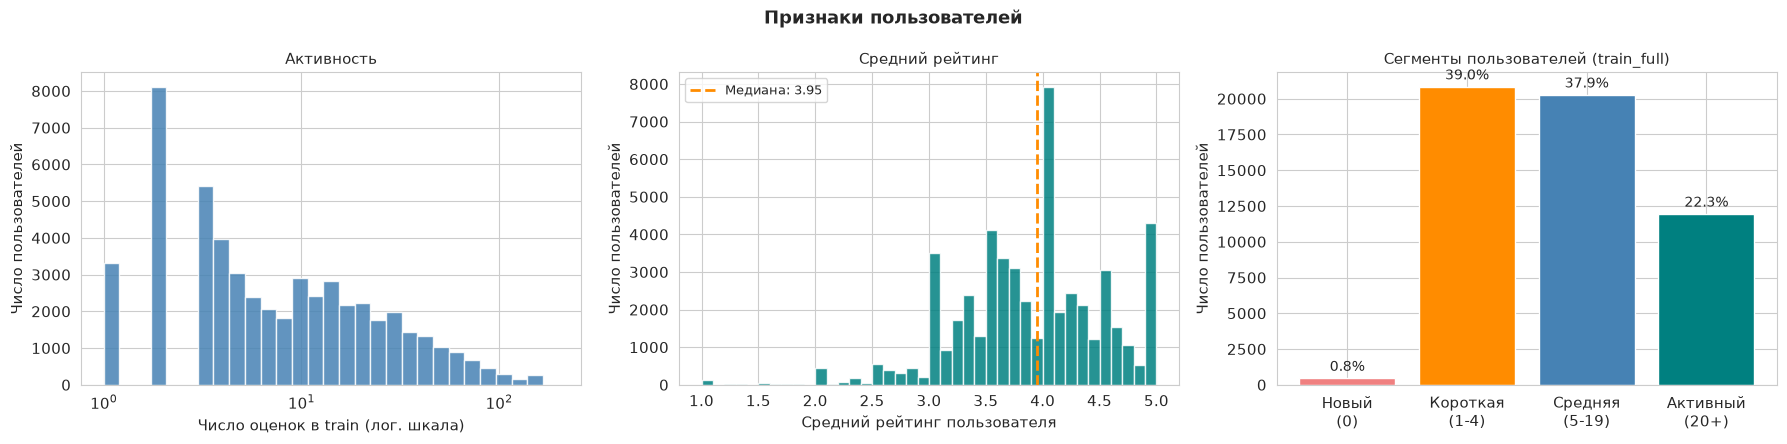

In [13]:
# Признаки пользователей по заданному train
USER_SEGMENT_NAMES = ['Новый (0)', 'Короткая история (1-4)', 'Средняя (5-19)', 'Активный (20+)']


def get_user_segment(n_ratings):
    if n_ratings == 0:
        return USER_SEGMENT_NAMES[0]
    if n_ratings <= 4:
        return USER_SEGMENT_NAMES[1]
    if n_ratings <= 19:
        return USER_SEGMENT_NAMES[2]
    return USER_SEGMENT_NAMES[3]


def build_user_features(train_df, n_users_total=None):
    # Строка на каждого пользователя 1..n_users_total, у пользователей без истории - значения по умолчанию.
    # По умолчанию пользователей столько же, сколько в ноутбуке, пайплайн раздела 7 передаёт своё число
    if n_users_total is None:
        n_users_total = n_users
    stats = train_df.groupby('user_id')['rating'].agg(['count', 'mean', 'std'])
    high_share = (train_df['rating'] >= RELEVANCE_THRESHOLD).groupby(train_df['user_id']).mean()
    global_mean = train_df['rating'].mean()

    user_features = pd.DataFrame(index=np.arange(1, n_users_total + 1))
    user_features.index.name = 'user_id'
    user_features['user_n_ratings'] = stats['count'].reindex(user_features.index).fillna(0)
    user_features['user_log_n_ratings'] = np.log1p(user_features['user_n_ratings'])
    user_features['user_mean_rating'] = stats['mean'].reindex(user_features.index).fillna(global_mean)
    user_features['user_std_rating'] = stats['std'].reindex(user_features.index).fillna(0)
    user_features['user_high_share'] = high_share.reindex(user_features.index).fillna(high_share.mean())

    segments = []
    for n_ratings in user_features['user_n_ratings']:
        segments.append(get_user_segment(n_ratings))
    user_features['user_segment'] = segments
    return user_features


user_features_fit = build_user_features(train_fit)
user_features_full = build_user_features(train_full)

print("Признаки пользователей по train_fit:")
display(user_features_fit.drop(columns=['user_segment']).describe().round(2).T)

print("Сегменты пользователей:")
segment_table = pd.DataFrame({
    'по train_fit': user_features_fit['user_segment'].value_counts(),
    'по train_full': user_features_full['user_segment'].value_counts(),
}).reindex(USER_SEGMENT_NAMES)
segment_table['доля по train_full, %'] = (segment_table['по train_full'] / n_users * 100).round(1)
display(segment_table)

# Распределения признаков пользователей по train_full
users_with_history = user_features_full[user_features_full['user_n_ratings'] > 0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(users_with_history['user_n_ratings'], bins=np.logspace(0, np.log10(200), 30),
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_xscale('log')
axes[0].set_xlabel('Число оценок в train (лог. шкала)')
axes[0].set_ylabel('Число пользователей')
axes[0].set_title('Активность', fontsize=11)

axes[1].hist(users_with_history['user_mean_rating'], bins=40, color='teal', edgecolor='white', alpha=0.85)
axes[1].axvline(users_with_history['user_mean_rating'].median(), color='darkorange', linestyle='--', linewidth=2,
                label=f"Медиана: {users_with_history['user_mean_rating'].median():.2f}")
axes[1].set_xlabel('Средний рейтинг пользователя')
axes[1].set_ylabel('Число пользователей')
axes[1].set_title('Средний рейтинг', fontsize=11)
axes[1].legend(fontsize=9)

axes[2].bar(range(len(USER_SEGMENT_NAMES)), segment_table['по train_full'].values,
            color=['lightcoral', 'darkorange', 'steelblue', 'teal'], edgecolor='white')
for i in range(len(USER_SEGMENT_NAMES)):
    axes[2].text(i, segment_table['по train_full'].values[i] + 300, f"{segment_table['доля по train_full, %'].values[i]:.1f}%",
                 ha='center', va='bottom', fontsize=10)
axes[2].set_xticks(range(len(USER_SEGMENT_NAMES)))
axes[2].set_xticklabels(['Новый\n(0)', 'Короткая\n(1-4)', 'Средняя\n(5-19)', 'Активный\n(20+)'])
axes[2].set_ylabel('Число пользователей')
axes[2].set_title('Сегменты пользователей (train_full)', fontsize=11)

plt.suptitle('Признаки пользователей', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'features_users.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Пользователи сильно различаются по активности и щедрости

- **Активность:** медиана - 5 оценок в `train_fit` и 7 в `train_full`, максимум 138 и 169. На логарифмической шкале распределение плавное, поэтому в признаки беру логарифм числа оценок.
- **Средний рейтинг** у большинства между 3.5 и 4.3, но есть и пользователи, которые ставят всем 5 или почти всем 1-2. Это то, что в ДЗ ловило смещение `b_u` у SVD.
- **Сегменты (по `train_full`):** пользователей с короткой (39.0%) и средней (37.9%) историей почти поровну, активных - 22.3%. Новых пользователей без единой оценки 439 (0.8%) - это холодный старт из ДЗ. В `train_fit` истории короче, и новых пользователей больше: 1 481.

### 3.2 Признаки книг

| Признак | Что означает |
|---|---|
| `book_n_ratings` | Популярность в нашей выборке: число оценок в train. В ранжировщик не идёт: протекает информацией о valid и test (раздел 6.1) |
| `book_log_goodreads_ratings` | Настоящая популярность: число оценок на Goodreads (в логарифме) |
| `book_mean_rating`, `book_goodreads_avg_rating` | Средний рейтинг в train и на Goodreads |
| `book_std_rating` | Разнообразие оценок: одни ставят книге 5, другие 2, или оценки единодушные |
| `book_year` | Год первой публикации |
| `book_in_series` | Входит ли книга в серию (в названии указано "#номер") |
| `book_category` | Тематическая категория по тегам. Отдельным признаком не идёт, жанры учитываются через `genre_match` (раздел 3.3) |

**Тематические категории.** Содержательные теги - это жанры, но их тысячи, и многие повторяют друг друга (`ya` и `young-adult`, `sci-fi` и `science-fiction`). Я вручную разложил самые частые теги (топ-220 без служебных) по 15 категориям. Для каждой книги суммирую `count` тегов каждой категории: вектор этих сумм, нормированный до долей, - это жанровый профиль книги. Категория с наибольшей суммой - основная категория книги.

Серию и первого автора книги беру из `books.csv`: серия указана в конце названия в скобках, например "The Reptile Room (A Series of Unfortunate Events, #2)". Это понадобится для признаков взаимодействий.

In [14]:
# Тематические категории: самые частые содержательные теги, разложенные по 15 группам
GENRE_GROUPS = {
    'Фэнтези': ['fantasy', 'urban-fantasy', 'paranormal', 'magic', 'supernatural', 'vampires', 'vampire',
                'high-fantasy', 'epic-fantasy', 'mythology', 'ya-fantasy', 'angels', 'werewolves', 'dragons',
                'witches', 'demons', 'fae', 'shifters', 'fairy-tales', 'discworld', 'harry-potter'],
    'Фантастика': ['science-fiction', 'sci-fi', 'scifi', 'sf', 'dystopian', 'dystopia', 'post-apocalyptic',
                   'time-travel', 'steampunk', 'speculative-fiction', 'star-wars', 'sci-fi-fantasy',
                   'fantasy-sci-fi', 'scifi-fantasy', 'science-fiction-fantasy', 'fantasy-scifi'],
    'Young adult': ['young-adult', 'ya', 'teen', 'ya-fiction', 'young-adult-fiction', 'ya-books', 'ya-lit',
                    'teen-fiction', 'new-adult', 'high-school', 'coming-of-age', 'college'],
    'Детские': ['childrens', 'children', 'children-s', 'children-s-books', 'childrens-books', 'kids', 'kids-books',
                'middle-grade', 'picture-books', 'picture-book', 'childhood', 'childhood-favorites',
                'childhood-books', 'juvenile', 'juvenile-fiction', 'children-s-literature', 'children-s-lit',
                'middle-school', 'animals'],
    'Романтика': ['romance', 'contemporary-romance', 'historical-romance', 'paranormal-romance', 'chick-lit',
                  'erotica', 'love', 'alpha-male', 'pnr', 'nora-roberts'],
    'Детектив и триллер': ['mystery', 'thriller', 'thrillers', 'crime', 'crime-fiction', 'suspense',
                           'mystery-thriller', 'mysteries', 'mystery-suspense', 'detective', 'agatha-christie',
                           'james-patterson'],
    'Ужасы': ['horror', 'stephen-king', 'zombies', 'ghosts', 'gothic', 'dark'],
    'Классика': ['classics', 'classic', 'literature', '1001-books', '1001', '1001-books-to-read-before-you-die',
                 'literary-fiction', 'literary', 'classic-literature', 'school', 'read-for-school', 'for-school',
                 'school-books', 'english', 'british', 'british-literature', 'american', 'american-literature',
                 '20th-century', '19th-century', 'rory-gilmore-reading-challenge', 'shakespeare',
                 'classics-to-read', 'magical-realism'],
    'Исторические': ['historical-fiction', 'historical', 'history', 'war', 'wwii', 'england'],
    'Нон-фикшн': ['non-fiction', 'nonfiction', 'biography', 'biographies', 'memoir', 'memoirs', 'autobiography',
                  'biography-memoir', 'psychology', 'science', 'philosophy', 'business', 'religion', 'christian',
                  'spirituality', 'self-help', 'politics', 'travel', 'food', 'art', 'music', 'essays', 'feminism'],
    'Комиксы и манга': ['graphic-novels', 'graphic-novel', 'comics', 'manga', 'comics-graphic-novels'],
    'Современная проза': ['contemporary', 'realistic-fiction', 'contemporary-fiction', 'general-fiction',
                          'adult-fiction', 'novels', 'novel', 'family', 'friendship', 'lgbt', 'women', 'made-me-cry'],
    'Юмор': ['humor', 'humour', 'funny', 'comedy'],
    'Приключения': ['adventure', 'action', 'action-adventure'],
    'Поэзия и драма': ['poetry', 'plays', 'drama', 'short-stories'],
}
GENRE_NAMES = list(GENRE_GROUPS.keys())

# Словарь "тег -> категория". Проверяю, что ни один тег не попал в две категории
tag_to_genre = {}
n_duplicates = 0
for genre_name, genre_tags in GENRE_GROUPS.items():
    for tag_name in genre_tags:
        if tag_name in tag_to_genre:
            n_duplicates += 1
        tag_to_genre[tag_name] = genre_name
print(f"Категорий: {len(GENRE_NAMES)}, тегов в категориях: {len(tag_to_genre)}, повторов: {n_duplicates}")

Категорий: 15, тегов в категориях: 177, повторов: 0


Книг без категории: 0
Книг в сериях: 44.4%
Корреляция популярности на Goodreads и среднего рейтинга в train: -0.03

Проверка на знакомых книгах:
  Harry Potter and the Sorcerer's Stone (Har   Фэнтези              серия: 'Harry Potter', автор: J.K. Rowling
  The Hunger Games (The Hunger Games, #1)      Фантастика           серия: 'The Hunger Games', автор: Suzanne Collins
  Gone Girl                                    Детектив и триллер   серия: '', автор: Gillian Flynn
  Thinking, Fast and Slow                      Нон-фикшн            серия: '', автор: Daniel Kahneman
  The Days Are Just Packed: A Calvin and Hob   Комиксы и манга      серия: '', автор: Bill Watterson



,count,mean,std,min,25%,50%,75%,max
book_n_ratings,10000.0,78.36,6.02,6.00,76.00,79.00,82.00,93.00
book_mean_rating,10000.0,3.86,0.31,1.92,3.67,3.88,4.07,4.89
book_std_rating,10000.0,0.93,0.13,0.43,0.85,0.93,1.01,1.76
book_log_goodreads_ratings,10000.0,10.19,0.94,7.91,9.52,9.96,10.62,15.38
book_goodreads_avg_rating,10000.0,4.00,0.25,2.47,3.85,4.02,4.18,4.82
book_year,10000.0,1991.65,36.46,1800.00,1990.00,2004.00,2011.00,2017.00


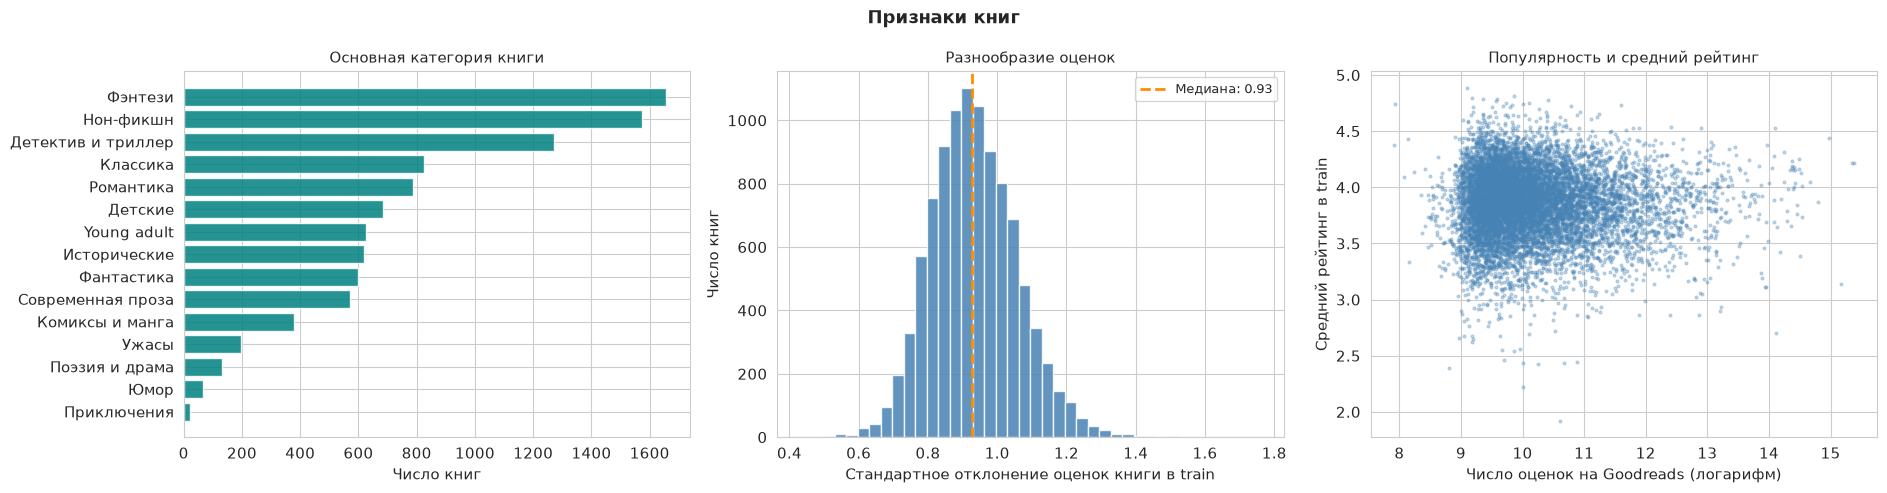

In [15]:
# Признаки книг, которые не зависят от оценок: жанры, Goodreads, год, серия, автор
def get_series(title):
    # Серия указана в конце названия в скобках: "The Reptile Room (A Series of Unfortunate Events, #2)"
    if not title.endswith(')'):
        return ''
    inside = title[title.rfind('(') + 1:-1]
    if '#' not in inside:
        return ''
    return inside.split('#')[0].strip().rstrip(',').strip()


def build_static_book_features(books, book_tags_named):
    # Жанровая матрица книга x категория: сумма count тегов каждой категории
    position_by_goodreads_id = pd.Series(books['id'].values - 1, index=books['book_id'].values)
    genre_index = {}
    for i, genre_name in enumerate(GENRE_NAMES):
        genre_index[genre_name] = i
    genre_tags = book_tags_named[book_tags_named['tag_name'].isin(tag_to_genre.keys())]
    rows = position_by_goodreads_id.loc[genre_tags['goodreads_book_id'].values].values
    cols = genre_tags['tag_name'].map(tag_to_genre).map(genre_index).values
    genre_matrix = np.zeros((n_books, len(GENRE_NAMES)))
    np.add.at(genre_matrix, (rows, cols), genre_tags['count'].values)

    # Жанровый профиль книги - доли категорий, основная категория - самая большая доля
    genre_sums = genre_matrix.sum(axis=1)
    has_genre = genre_sums > 0
    genre_vectors = np.zeros_like(genre_matrix)
    genre_vectors[has_genre] = genre_matrix[has_genre] / genre_sums[has_genre].reshape(-1, 1)
    categories = []
    for position in range(n_books):
        if has_genre[position]:
            categories.append(GENRE_NAMES[int(np.argmax(genre_matrix[position]))])
        else:
            categories.append('Прочее')

    books_sorted = books.sort_values('id').reset_index(drop=True)
    static = pd.DataFrame(index=np.arange(1, n_books + 1))
    static.index.name = 'book_id'
    static['book_category'] = categories
    static['book_log_goodreads_ratings'] = np.log1p(books_sorted['ratings_count'].values)
    static['book_goodreads_avg_rating'] = books_sorted['average_rating'].values
    publication_year = books_sorted['original_publication_year']
    static['book_year'] = publication_year.fillna(publication_year.median()).clip(lower=1800).values
    series = books_sorted['title'].map(get_series)
    static['book_series'] = series.values
    static['book_in_series'] = (series != '').astype(float).values
    static['book_first_author'] = books_sorted['authors'].str.split(',').str[0].str.strip().values
    return static, genre_vectors


def build_book_features(train_df, static_book_features):
    # Признаки книг по оценкам в train: популярность, средний рейтинг и разнообразие оценок
    stats = train_df.groupby('book_id')['rating'].agg(['count', 'mean', 'std'])
    global_mean = train_df['rating'].mean()
    book_features = static_book_features.copy()
    book_features['book_n_ratings'] = stats['count'].reindex(book_features.index).fillna(0)
    book_features['book_mean_rating'] = stats['mean'].reindex(book_features.index).fillna(global_mean)
    book_features['book_std_rating'] = stats['std'].reindex(book_features.index).fillna(0)
    return book_features


static_book_features, book_genre_vectors = build_static_book_features(books, book_tags_named)
book_features_fit = build_book_features(train_fit, static_book_features)
book_features_full = build_book_features(train_full, static_book_features)

print(f"Книг без категории: {(static_book_features['book_category'] == 'Прочее').sum()}")
print(f"Книг в сериях: {static_book_features['book_in_series'].mean() * 100:.1f}%")
popularity_rating_corr = np.corrcoef(book_features_full['book_log_goodreads_ratings'],
                                     book_features_full['book_mean_rating'])[0, 1]
print(f"Корреляция популярности на Goodreads и среднего рейтинга в train: {popularity_rating_corr:.2f}")
print()
print("Проверка на знакомых книгах:")
for example_book_id in [2, 1, 30, 619, 5207]:
    example = static_book_features.loc[example_book_id]
    print(f"  {book_info.loc[example_book_id, 'title'][:42]:<44} {example['book_category']:<20} "
          f"серия: '{example['book_series']}', автор: {example['book_first_author']}")
print()
display(book_features_full[['book_n_ratings', 'book_mean_rating', 'book_std_rating',
                            'book_log_goodreads_ratings', 'book_goodreads_avg_rating', 'book_year']].describe().round(2).T)

# Распределения признаков книг
category_counts = static_book_features['book_category'].value_counts()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
category_positions = np.arange(len(category_counts))[::-1]
axes[0].barh(category_positions, category_counts.values, color='teal', edgecolor='white', alpha=0.85)
axes[0].set_yticks(category_positions)
axes[0].set_yticklabels(category_counts.index)
axes[0].set_xlabel('Число книг')
axes[0].set_title('Основная категория книги', fontsize=11)

axes[1].hist(book_features_full['book_std_rating'], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[1].axvline(book_features_full['book_std_rating'].median(), color='darkorange', linestyle='--', linewidth=2,
                label=f"Медиана: {book_features_full['book_std_rating'].median():.2f}")
axes[1].set_xlabel('Стандартное отклонение оценок книги в train')
axes[1].set_ylabel('Число книг')
axes[1].set_title('Разнообразие оценок', fontsize=11)
axes[1].legend(fontsize=9)

axes[2].scatter(book_features_full['book_log_goodreads_ratings'], book_features_full['book_mean_rating'],
                s=4, alpha=0.3, color='steelblue')
axes[2].set_xlabel('Число оценок на Goodreads (логарифм)')
axes[2].set_ylabel('Средний рейтинг в train')
axes[2].set_title('Популярность и средний рейтинг', fontsize=11)

plt.suptitle('Признаки книг', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'features_books.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Категории и признаки книг выглядят осмысленно

- **Категория есть у всех 10 000 книг**, и на знакомых книгах она правильная: Harry Potter - фэнтези, The Hunger Games - фантастика, Gone Girl - детектив и триллер, Thinking, Fast and Slow - нон-фикшн, Calvin and Hobbes - комиксы. Больше всего книг в фэнтези, нон-фикшн и детективах, меньше всего - в приключениях и юморе: эти теги чаще стоят вторыми, а не основными.
- **44.4% книг входят в серии.** В ДЗ 61% попаданий Item-CF были продолжениями серий, так что серия - важный признак.
- **Разнообразие оценок:** у типичной книги стандартное отклонение оценок около 0.93. Спорных книг с разбросом выше 1.3 мало (около 0.5%), большинство книг оценивают довольно согласованно.
- **Популярность и средний рейтинг не связаны:** корреляция -0.03, облако точек без наклона. Популярная книга не обязательно хорошо оценена, поэтому это два разных признака.

### 3.3 Признаки взаимодействий: схожесть книги с историей пользователя

Эти признаки считаются для пары (пользователь, книга-кандидат):

| Признак | Что означает |
|---|---|
| `item_cf_score` | Сумма "схожесть x оценка" по K = 20 самым похожим книгам из истории (скор Item-CF) |
| `item_cf_similarity_sum` | Сумма схожестей тех же K книг: насколько книга вообще связана с историей |
| `item_cf_max_similarity` | Схожесть с самой похожей книгой истории |
| `item_cf_prediction` | Прогноз оценки Item-CF (взвешенное среднее) |
| `content_score` | Косинусная близость TF-IDF книги и профиля пользователя (скор Content-based) |
| `genre_match` | Косинусная близость жанрового профиля книги и среднего жанрового профиля понравившихся пользователю книг |
| `same_series_in_history` | Книга из серии, которую пользователь уже читал |
| `same_author_in_history` | Книга автора, которого пользователь уже читал |
| `pure_svd_score`, `svd_prediction`, `popularity_score` | Скоры остальных моделей: PureSVD, предсказанный рейтинг SVD и место книги в рейтинге популярности (поделённое на число книг) |

Чтобы не считать одно и то же много раз, функция `get_user_score_arrays` один раз считает для пользователя все скоры по всем 10 000 книгам. Функция `compute_candidate_features` берёт из них значения для нужных кандидатов и добавляет признаки пользователя и книги. Всего получается 22 признака: 4 признака пользователя, 7 признаков книги и 11 признаков взаимодействия. Сегмент пользователя и основная категория книги в их число не входят. Сегмент нужен для стратегий гибрида и для анализа по группам, а категория попадает в признаки через жанровый профиль книги в `genre_match`.

In [16]:
# Признаки пары (пользователь, книга-кандидат)
USER_FEATURE_COLUMNS = ['user_log_n_ratings', 'user_mean_rating', 'user_std_rating', 'user_high_share']
BOOK_FEATURE_COLUMNS = ['book_log_goodreads_ratings', 'book_goodreads_avg_rating', 'book_year', 'book_in_series',
                        'book_n_ratings', 'book_mean_rating', 'book_std_rating']
INTERACTION_FEATURE_COLUMNS = ['item_cf_score', 'item_cf_similarity_sum', 'item_cf_max_similarity',
                               'item_cf_prediction', 'content_score', 'genre_match',
                               'same_series_in_history', 'same_author_in_history',
                               'pure_svd_score', 'svd_prediction', 'popularity_score']
FEATURE_COLUMNS = USER_FEATURE_COLUMNS + BOOK_FEATURE_COLUMNS + INTERACTION_FEATURE_COLUMNS


def get_user_score_arrays(models, user_id):
    # Все скоры пользователя по всем книгам: скоры пяти моделей и дополнительные величины Item-CF
    item_cf_scores, item_cf_similarity_sums, item_cf_predictions = score_item_cf(models, user_id)
    history_positions = models['user_item'][user_id - 1].indices
    if len(history_positions) > 0:
        # Для каждой книги - максимальная схожесть с книгами истории
        item_cf_max_similarity = models['item_similarity'][history_positions].max(axis=0).toarray().flatten()
    else:
        item_cf_max_similarity = np.zeros(n_books)
    return {
        'Popularity': models['popularity_score'],
        'Content-based': score_content(models, user_id),
        'Item-CF': item_cf_scores,
        'SVD': score_svd(models, user_id),
        'PureSVD': score_pure_svd(models, user_id),
        'item_cf_similarity_sum': item_cf_similarity_sums,
        'item_cf_prediction': item_cf_predictions,
        'item_cf_max_similarity': item_cf_max_similarity,
    }


def compute_candidate_features(models, user_features, book_features, user_id, candidate_positions, score_arrays):
    # Возвращает словарь "признак -> массив значений для кандидатов"
    n_candidates = len(candidate_positions)
    user_row = models['user_item'][user_id - 1]
    history_positions = user_row.indices
    features = {}

    # Признаки пользователя одинаковые для всех его кандидатов
    for column in USER_FEATURE_COLUMNS:
        features[column] = np.full(n_candidates, user_features[column].values[user_id - 1])
    # Признаки книги
    for column in BOOK_FEATURE_COLUMNS:
        features[column] = book_features[column].values[candidate_positions]

    # Схожесть с историей и скоры моделей
    features['item_cf_score'] = score_arrays['Item-CF'][candidate_positions]
    features['item_cf_similarity_sum'] = score_arrays['item_cf_similarity_sum'][candidate_positions]
    features['item_cf_max_similarity'] = score_arrays['item_cf_max_similarity'][candidate_positions]
    features['item_cf_prediction'] = score_arrays['item_cf_prediction'][candidate_positions]
    features['content_score'] = score_arrays['Content-based'][candidate_positions]
    features['pure_svd_score'] = score_arrays['PureSVD'][candidate_positions]
    features['svd_prediction'] = score_arrays['SVD'][candidate_positions]
    features['popularity_score'] = score_arrays['Popularity'][candidate_positions] / n_books

    # Совпадение жанров: профиль пользователя - средний жанровый профиль понравившихся книг
    liked_positions = user_row.indices[user_row.data >= RELEVANCE_THRESHOLD]
    if len(liked_positions) == 0:
        liked_positions = history_positions
    genre_match = np.zeros(n_candidates)
    if len(liked_positions) > 0:
        user_genre_profile = book_genre_vectors[liked_positions].mean(axis=0)
        candidate_genres = book_genre_vectors[candidate_positions]
        norms = np.linalg.norm(candidate_genres, axis=1) * np.linalg.norm(user_genre_profile)
        has_norm = norms > 0
        genre_match[has_norm] = (candidate_genres[has_norm] @ user_genre_profile) / norms[has_norm]
    features['genre_match'] = genre_match

    # Серия и автор из истории пользователя
    history_series = set(book_features['book_series'].values[history_positions])
    history_series.discard('')
    history_authors = set(book_features['book_first_author'].values[history_positions])
    candidate_series = book_features['book_series'].values[candidate_positions]
    candidate_authors = book_features['book_first_author'].values[candidate_positions]
    same_series = np.zeros(n_candidates)
    same_author = np.zeros(n_candidates)
    for i in range(n_candidates):
        if candidate_series[i] != '' and candidate_series[i] in history_series:
            same_series[i] = 1
        if candidate_authors[i] in history_authors:
            same_author[i] = 1
    features['same_series_in_history'] = same_series
    features['same_author_in_history'] = same_author
    return features


# Пример: признаки для демо-пользователя из ДЗ (читает "A Series of Unfortunate Events")
demo_user_id = 21150
print(f"Пользователь {demo_user_id}: оценок в train_fit {models_fit['user_item'][demo_user_id - 1].nnz}, "
      f"понравившихся книг в valid {len(valid_relevant[demo_user_id])}")
demo_relevant_ids = sorted(valid_relevant[demo_user_id])[:2]
demo_random_ids = [1, 7947]
demo_candidate_ids = demo_relevant_ids + demo_random_ids
demo_features = compute_candidate_features(models_fit, user_features_fit, book_features_fit, demo_user_id,
                                           np.array(demo_candidate_ids) - 1,
                                           get_user_score_arrays(models_fit, demo_user_id))
demo_table = pd.DataFrame(demo_features, index=book_info.loc[demo_candidate_ids, 'title'].str[:30].values)
print(f"Всего признаков: {len(FEATURE_COLUMNS)}. Первые две книги - понравились пользователю в valid, две другие - нет")
display(demo_table[INTERACTION_FEATURE_COLUMNS].T.round(3))

Пользователь 21150: оценок в train_fit 23, понравившихся книг в valid 6
Всего признаков: 22. Первые две книги - понравились пользователю в valid, две другие - нет


,The Invention of Hugo Cabret,The Reptile Room (A Series of,The Hunger Games (The Hunger G,ESV Study Bible
item_cf_score,2.533,14.240,2.023,0.000
item_cf_similarity_sum,0.594,3.467,0.515,0.000
item_cf_max_similarity,0.069,0.525,0.047,0.000
item_cf_prediction,4.261,4.107,3.929,4.130
content_score,0.370,0.699,0.164,0.017
genre_match,0.828,0.908,0.332,0.307
same_series_in_history,0.000,1.000,0.000,0.000
same_author_in_history,0.000,1.000,0.000,0.000
pure_svd_score,0.027,0.243,0.017,0.002
svd_prediction,4.341,4.159,4.619,5.013


На демо-пользователе видно сразу несколько эффектов:
- **The Reptile Room** - продолжение серии, которую он читает. У неё самые большие скоры Item-CF (14.2) и контентной модели (0.70), и сработали признаки серии и автора.
- **The Invention of Hugo Cabret** связана с историей слабее: по Item-CF она почти как The Hunger Games (2.5 против 2.0). Отличают её содержание и жанр: 0.37 против 0.16 и 0.83 против 0.33. Значит, признаки разных моделей дополняют друг друга.
- **Прогноз SVD** выше всего у книг, не связанных с его чтением: ESV Study Bible (5.01) и The Hunger Games (4.62). Это та же картина, что в ДЗ: прогноз оценки поднимает книги, которые нравятся всем.

Теперь проверю это на тысячах пользователей.

### 3.4 Какие признаки полезны: проверка на validation

Беру 3000 случайных пользователей validation и для каждого собираю примеры двух видов. По ним решаю две задачи:

- **Задача А: "прочитает и оценит высоко".** Понравившиеся книги из valid (оценка >= 4) против 20 случайных непрочитанных книг. Это ровно то, что проверяют метрики top-N.
- **Задача Б: "понравится ли из прочитанного".** Понравившиеся книги из valid против прочитанных без удовольствия (оценка <= 3). Это задача прогноза оценки, которую решали RMSE в ДЗ.

Для каждого признака отдельно считаю ROC AUC: вероятность того, что у случайной понравившейся книги значение признака больше, чем у случайной книги второго класса. AUC = 0.5 - признак бесполезен, AUC = 1 - идеально разделяет. Значения меньше 0.5 тоже несут информацию: признак работает "наоборот".

Общий AUC сравнивает примеры всех пользователей сразу, и в нём смешаны два эффекта: различия между пользователями и порядок книг внутри одного пользователя. Для рекомендаций важен только второй. Поэтому после общей таблицы считаю ещё **AUC внутри пользователя**: долю пар (понравившаяся книга, книга второго класса) одного и того же пользователя, в которых у понравившейся книги значение признака больше. У признаков пользователя он по построению ровно 0.5: они одинаковые у всех книг одного пользователя и упорядочить их не могут. Но в ранжировщике они могут помочь как контекст: например, у пользователя с длинной историей скорам Item-CF можно доверять больше.

In [17]:
# Выборка для проверки признаков: 3000 пользователей validation
from sklearn.metrics import roc_auc_score    # нужен только для проверки признаков в этом разделе

feature_rng = np.random.default_rng(RANDOM_STATE)
feature_sample_ids = feature_rng.choice(np.array(valid_user_ids), size=3000, replace=False)
valid_disliked = valid[valid['rating'] < RELEVANCE_THRESHOLD].groupby('user_id')['book_id'].apply(set)

start_time = time.perf_counter()
task_a_parts = []
task_b_parts = []
for user_id in feature_sample_ids:
    rated_positions = set(models_fit['user_item'][user_id - 1].indices)
    liked_positions = []
    for book_id in valid_relevant[user_id]:
        liked_positions.append(book_id - 1)

    # 20 случайных книг, которых нет ни в train_fit, ни среди понравившихся
    random_positions = []
    while len(random_positions) < 20:
        position = int(feature_rng.integers(0, n_books))
        if position not in rated_positions and position not in liked_positions and position not in random_positions:
            random_positions.append(position)

    disliked_positions = []
    if user_id in valid_disliked.index:
        for book_id in valid_disliked[user_id]:
            disliked_positions.append(book_id - 1)

    candidate_positions = np.array(liked_positions + random_positions + disliked_positions)
    user_scores = get_user_score_arrays(models_fit, user_id)
    features = compute_candidate_features(models_fit, user_features_fit, book_features_fit, user_id,
                                          candidate_positions, user_scores)
    part = pd.DataFrame(features)
    part['user_id'] = user_id
    part['kind'] = ['liked'] * len(liked_positions) + ['random'] * len(random_positions) + ['disliked'] * len(disliked_positions)
    task_a_parts.append(part[part['kind'] != 'disliked'])
    task_b_parts.append(part[part['kind'] != 'random'])

task_a = pd.concat(task_a_parts, ignore_index=True)
task_b = pd.concat(task_b_parts, ignore_index=True)
print(f"Время: {time.perf_counter() - start_time:.0f} с")
print(f"Задача А: {len(task_a)} примеров, понравившихся {(task_a['kind'] == 'liked').mean() * 100:.1f}%")
print(f"Задача Б: {len(task_b)} примеров, понравившихся {(task_b['kind'] == 'liked').mean() * 100:.1f}%")
print()

# AUC каждого признака в двух задачах
auc_rows = []
for column in FEATURE_COLUMNS:
    if column in USER_FEATURE_COLUMNS:
        group = 'пользователь'
    elif column in BOOK_FEATURE_COLUMNS:
        group = 'книга'
    else:
        group = 'взаимодействие'
    auc_rows.append({
        'признак': column,
        'группа': group,
        'AUC задача А (прочитает)': roc_auc_score(task_a['kind'] == 'liked', task_a[column]),
        'AUC задача Б (понравится)': roc_auc_score(task_b['kind'] == 'liked', task_b[column]),
    })
feature_auc = pd.DataFrame(auc_rows).sort_values('AUC задача А (прочитает)', ascending=False).reset_index(drop=True)
display(feature_auc.round(3))

# Бинарные признаки серии и автора: доля книг с признаком среди понравившихся и случайных
for column in ['same_series_in_history', 'same_author_in_history']:
    liked_share = task_a.loc[task_a['kind'] == 'liked', column].mean() * 100
    random_share = task_a.loc[task_a['kind'] == 'random', column].mean() * 100
    print(f"{column}: у понравившихся {liked_share:.1f}%, у случайных {random_share:.1f}%")

Время: 31 с
Задача А: 69866 примеров, понравившихся 14.1%
Задача Б: 14148 примеров, понравившихся 69.7%



,признак,группа,AUC задача А (прочитает),AUC задача Б (понравится)
0,item_cf_max_similarity,взаимодействие,0.907,0.512
1,content_score,взаимодействие,0.906,0.594
2,item_cf_score,взаимодействие,0.901,0.516
3,item_cf_similarity_sum,взаимодействие,0.900,0.485
4,pure_svd_score,взаимодействие,0.892,0.472
5,genre_match,взаимодействие,0.839,0.569
6,user_log_n_ratings,пользователь,0.701,0.431
7,same_author_in_history,взаимодействие,0.696,0.522
8,same_series_in_history,взаимодействие,0.613,0.521
9,svd_prediction,взаимодействие,0.577,0.762


same_series_in_history: у понравившихся 22.8%, у случайных 0.2%
same_author_in_history: у понравившихся 39.8%, у случайных 0.7%


In [18]:
# AUC внутри пользователя: умеет ли признак упорядочить книги одного и того же пользователя.
# AUC выше считается по примерам всех пользователей сразу. Тогда признак, который отличает одних пользователей
# от других (щедрость пользователя, смещение b_u в прогнозе SVD), получает высокий AUC, хотя книги одного
# пользователя он не упорядочивает. А для рекомендаций важен именно порядок книг внутри пользователя
def within_user_auc(table, column):
    # Доля пар (понравившаяся книга, книга второго класса) одного пользователя, в которых у понравившейся
    # значение признака больше. Равные значения дают половину пары. Пользователи с одним классом пар не дают
    is_liked = (table['kind'] == 'liked').values
    ranks = table.groupby('user_id')[column].rank(method='average').values
    per_user = pd.DataFrame({'user_id': table['user_id'].values, 'liked': is_liked, 'liked_rank': ranks * is_liked})
    per_user = per_user.groupby('user_id').agg(n=('liked', 'size'), n_liked=('liked', 'sum'),
                                               rank_sum=('liked_rank', 'sum'))
    n_pairs = per_user['n_liked'] * (per_user['n'] - per_user['n_liked'])
    # Сумма рангов понравившихся минус наименьшая возможная сумма - число выигранных пар (статистика Манна-Уитни)
    won_pairs = per_user['rank_sum'] - per_user['n_liked'] * (per_user['n_liked'] + 1) / 2
    return won_pairs.sum() / n_pairs.sum()


# Проверка функции на игрушечном примере. У первого пользователя понравившаяся книга выше обеих случайных
# (2 пары из 2), у второго - выше одной из двух (1 из 2). Внутри пользователя 3 пары из 4, то есть 0.75
toy_table = pd.DataFrame({'user_id': [1, 1, 1, 2, 2, 2],
                          'kind': ['liked', 'random', 'random', 'liked', 'random', 'random'],
                          'value': [5.0, 4.0, 3.0, 1.0, 2.0, 0.5]})
print(f"Игрушечный пример: AUC внутри пользователя {within_user_auc(toy_table, 'value'):.3f} (вручную 0.750), "
      f"по всем примерам {roc_auc_score(toy_table['kind'] == 'liked', toy_table['value']):.3f}")

# В задаче Б у части пользователей нет ни одной оценки <= 3. Их понравившиеся книги входят в общий AUC,
# а пар внутри пользователя не дают. Поэтому для задачи Б считаю ещё общий AUC только по пользователям с оценками <= 3
users_with_disliked = task_b.loc[task_b['kind'] == 'disliked', 'user_id'].unique()
task_b_both = task_b[task_b['user_id'].isin(users_with_disliked)]
print(f"Задача Б: пользователей с оценками <= 3 в valid {len(users_with_disliked)} из {task_b['user_id'].nunique()}")

within_rows = []
for column in feature_auc['признак']:
    within_rows.append({
        'А: внутри пользователя': within_user_auc(task_a, column),
        'Б: польз. с оценками <= 3': roc_auc_score(task_b_both['kind'] == 'liked', task_b_both[column]),
        'Б: внутри пользователя': within_user_auc(task_b, column),
    })
feature_auc = pd.concat([feature_auc, pd.DataFrame(within_rows, index=feature_auc.index)], axis=1)
display(feature_auc[['признак', 'группа', 'AUC задача А (прочитает)', 'А: внутри пользователя',
                     'AUC задача Б (понравится)', 'Б: польз. с оценками <= 3', 'Б: внутри пользователя']].round(3))


Игрушечный пример: AUC внутри пользователя 0.750 (вручную 0.750), по всем примерам 0.625
Задача Б: пользователей с оценками <= 3 в valid 1476 из 3000


,признак,группа,AUC задача А (прочитает),А: внутри пользователя,AUC задача Б (понравится),Б: польз. с оценками <= 3,Б: внутри пользователя
0,item_cf_max_similarity,взаимодействие,0.907,0.898,0.512,0.547,0.528
1,content_score,взаимодействие,0.906,0.893,0.594,0.614,0.606
2,item_cf_score,взаимодействие,0.901,0.905,0.516,0.571,0.548
3,item_cf_similarity_sum,взаимодействие,0.900,0.905,0.485,0.544,0.531
4,pure_svd_score,взаимодействие,0.892,0.896,0.472,0.532,0.516
5,genre_match,взаимодействие,0.839,0.830,0.569,0.552,0.558
6,user_log_n_ratings,пользователь,0.701,0.500,0.431,0.528,0.500
7,same_author_in_history,взаимодействие,0.696,0.692,0.522,0.537,0.521
8,same_series_in_history,взаимодействие,0.613,0.612,0.521,0.527,0.514
9,svd_prediction,взаимодействие,0.577,0.543,0.762,0.714,0.628


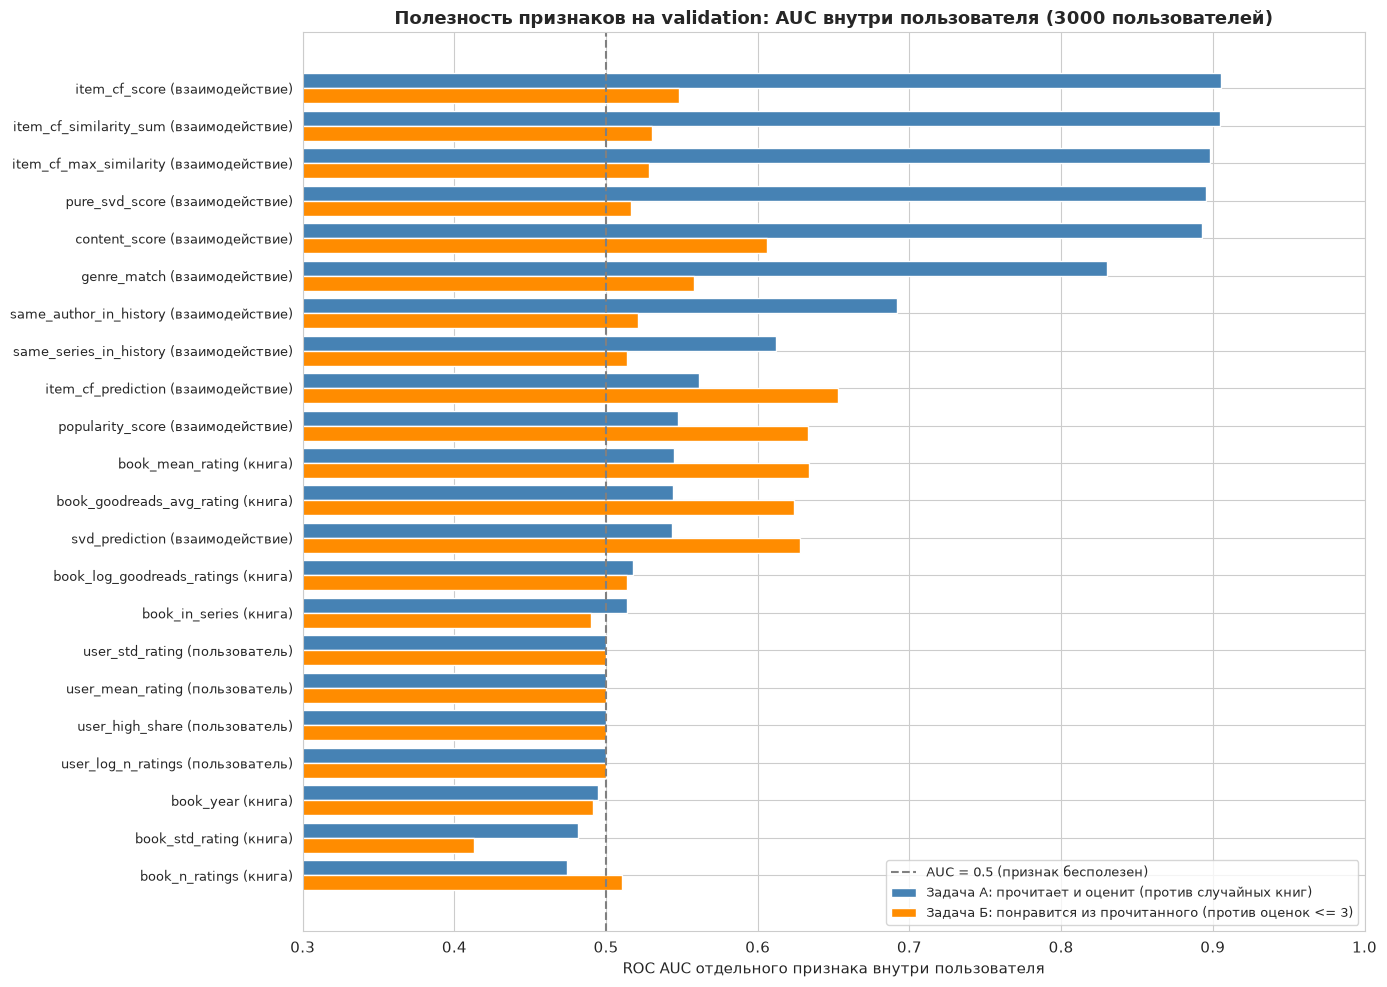

In [19]:
# График: насколько каждый признак отличает понравившиеся книги в двух задачах.
# Показываю AUC внутри пользователя: для рекомендаций важен порядок книг одного пользователя
plot_table = feature_auc.sort_values('А: внутри пользователя')
positions = np.arange(len(plot_table))
bar_height = 0.4
fig, ax = plt.subplots(figsize=(14, 10))
ax.barh(positions + bar_height / 2, plot_table['А: внутри пользователя'], height=bar_height,
        color='steelblue', label='Задача А: прочитает и оценит (против случайных книг)')
ax.barh(positions - bar_height / 2, plot_table['Б: внутри пользователя'], height=bar_height,
        color='darkorange', label='Задача Б: понравится из прочитанного (против оценок <= 3)')
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1.5, label='AUC = 0.5 (признак бесполезен)')
ylabels = []
for column, group in zip(plot_table['признак'], plot_table['группа']):
    ylabels.append(f"{column} ({group})")
ax.set_yticks(positions)
ax.set_yticklabels(ylabels, fontsize=9)
ax.set_xlim(0.3, 1.0)
ax.set_xlabel('ROC AUC отдельного признака внутри пользователя')
ax.set_title('Полезность признаков на validation: AUC внутри пользователя (3000 пользователей)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'features_auc.png'), dpi=100, bbox_inches='tight')
plt.show()


#### Признаки делятся на две группы, и ни одна не решает обе задачи

Дальше опираюсь на AUC внутри пользователя (столбцы "внутри пользователя" в таблице и график): он показывает, помогает ли признак упорядочить книги одного человека.

**Задача А "прочитает и оценит"** - её проверяют метрики top-N:
- Лучше всего работают признаки **схожести с историей**: скор Item-CF и сумма схожестей (AUC 0.905), максимальная схожесть Item-CF (0.898), PureSVD (0.896), контентная схожесть (0.893). Совпадение жанров слабее (0.830): жанр - слишком грубая характеристика. Общий AUC у этих признаков почти такой же, им разница между пользователями не помогает.
- **Серия и автор** работают как точечные, но очень надёжные сигналы. Продолжение серии из истории есть у 22.8% понравившихся книг и только у 0.2% случайных. Тот же автор - у 39.8% понравившихся и 0.7% случайных. AUC у них умеренный (0.61 и 0.69) только потому, что признак срабатывает не у всех книг.
- Прогнозы оценки (SVD 0.54, Item-CF 0.56) и признаки книги (средний рейтинг, разнообразие оценок, год) почти бесполезны: AUC 0.48-0.55.
- У активности пользователя общий AUC 0.70, а внутри пользователя ровно 0.5. Общий AUC показывал только то, что у активных пользователей больше понравившихся книг в valid.

**Задача Б "понравится из прочитанного"** - картина обратная, но разрыв меньше, чем кажется по общему AUC:
- Лучше всего работают **прогнозы оценки и средний рейтинг книги**: прогноз Item-CF (0.65), средний рейтинг книги в train (0.63), место в рейтинге популярности (0.63), прогноз SVD (0.63), средний рейтинг на Goodreads (0.62). Немного помогает и контентная схожесть (0.61).
- По общему AUC лучшей выглядела SVD (0.762), а щедрость пользователя - сильным признаком (средний рейтинг 0.725, доля оценок 4-5 0.724). Но это различия между пользователями: щедрый пользователь чаще ставит 4 и 5 всем книгам, а SVD учитывает это через смещение пользователя `b_u`. Внутри пользователя признаки щедрости дают ровно 0.5, а SVD опускается до 0.63 и уступает прогнозу Item-CF. Часть завышения даёт и сама выборка: у половины пользователей (1 524 из 3000) в valid нет ни одной оценки <= 3. Их понравившиеся книги входят в общий AUC, но пар внутри пользователя не дают. Если оставить только пользователей с обоими классами, общий AUC у SVD уже 0.71.
- Схожесть по общим читателям здесь почти бесполезна (0.52-0.55 у признаков Item-CF и PureSVD): прочитанные книги и так похожи на историю, а понравятся ли они, схожесть не говорит.
- Разброс оценок книги работает "наоборот" (0.41): спорные книги чаще получают оценки <= 3.

**Вывод:** этот раздел количественно подтверждает главный урок ДЗ. Схожесть с историей отвечает на вопрос "что пользователь прочитает" (AUC около 0.9), а прогнозы оценки и средний рейтинг книги - на вопрос "понравится ли" (около 0.62-0.65). Релевантная книга должна удовлетворять обоим условиям. Поэтому имеет смысл модель, которая учится комбинировать обе группы, то есть ранжировщик (раздел 6). Признаки пользователя книги одного пользователя не упорядочивают, но могут помочь ранжировщику как контекст. Будет ли от них польза на самом деле, проверю важностью признаков в разделе 6.5.

Отдельно стоит `book_n_ratings`: в задаче А у него AUC ниже 0.5 (0.473, внутри пользователя 0.475), хотя популярность по нашим оценкам ни о чём не говорит. Это не случайность, а утечка информации о valid из-за потолка в 100 оценок на книгу. Разбор - в разделе 6.1, в ранжировщик этот признак не идёт.

## 4. Гибридная система

По заданию гибридная система состоит из двух частей:
- **генерация кандидатов:** объединение рекомендаций всех моделей в общий пул, фильтрация прочитанных книг, баланс разнообразия и релевантности,
- **стратегия объединения моделей:** взвешенное усреднение их предсказаний, разделение пользователей по типам (новые / активные), комбинирование персонализированных и популярных рекомендаций.

Схема двухэтапная, как в реальных рекомендательных системах. Сначала быстро собираем пул из нескольких сотен правдоподобных книг, потом аккуратно ранжируем только его. Ранжирование в этом разделе - взвешенное усреднение скоров моделей, в разделе 6 его заменит нейросетевой ранжировщик. Веса и параметры здесь только задаются, а подбираются на validation в разделе 5.

### 4.1 Общий пул кандидатов

Для каждого пользователя беру top-M книг каждой модели, исключая книги из его train, и объединяю их в один пул:

| Модель | Сколько кандидатов | Почему |
|---|---|---|
| Item-CF | 50 | Лучшая модель ДЗ, даёт больше всего понравившихся книг |
| Content-based | 50 | Вторая по качеству, находит книги по содержанию, а не по общим читателям |
| PureSVD | 50 | Обобщает через скрытые факторы, находит то, чего нет у Item-CF |
| SVD | 20 | По ранжированию слабая, но приносит книги с высоким прогнозом оценки |
| Popularity | 20 | Неперсональная часть пула: одни и те же популярные книги для всех |

Квоты выбраны по предварительной проверке на validation. При 50 кандидатах от каждой модели в пул попадает около 44% понравившихся книг (у одной Item-CF - 37%). Дальше рост медленный, а размер пула и время расчёта растут линейно. SVD и Popularity почти не добавляют понравившихся книг, поэтому им хватает 20 мест. Но совсем их не брать нельзя: по заданию пул собирается от всех моделей.

**Как хранится пул.** Каждому пользователю - строка матрицы из 190 мест (50 + 50 + 50 + 20 + 20, столько максимум может быть после объединения). Пустые места помечены маской. В том же формате хранятся признаки раздела 3 (трёхмерный массив "пользователь x место x признак"), метки "книга понравилась в valid / test" и то, какие модели предложили книгу. Такой формат позволяет считать метрики любой комбинации моделей сразу для всех пользователей, без циклов.

Пул строю для двух наборов:
- **validation:** 15 000 случайных пользователей из 30 935, модели обучены на `train_fit`. На них подбираются веса (раздел 5) и обучается ранжировщик (раздел 6). 15 000 пользователей хватает с запасом, а время расчёта вдвое меньше.
- **test:** все 34 288 пользователей, модели обучены на `train_full`. Только для итоговой оценки.

In [20]:
# Генерация общего пула кандидатов
POOL_MODEL_NAMES = ['Item-CF', 'Content-based', 'PureSVD', 'SVD', 'Popularity']
CANDIDATES_PER_MODEL = {'Item-CF': 50, 'Content-based': 50, 'PureSVD': 50, 'SVD': 20, 'Popularity': 20}
POOL_SIZE = 190

# Нормированные скоры моделей (раздел 4.2) хранятся вместе с признаками раздела 3
Z_COLUMNS = {'Item-CF': 'z_item_cf', 'Content-based': 'z_content', 'PureSVD': 'z_pure_svd',
             'SVD': 'z_svd', 'Popularity': 'z_popularity'}
POOL_FEATURE_COLUMNS = FEATURE_COLUMNS + list(Z_COLUMNS.values())


def top_m_positions(scores, rated_positions, m):
    # m книг с наибольшим скором без прочитанных. argpartition быстро отбирает m лучших,
    # потом сортирую только их (устойчиво, как top_n_books в разделе 2)
    values = scores.copy()
    values[rated_positions] = -np.inf
    best = np.argpartition(-values, m)[:m]
    return best[np.argsort(-values[best], kind='stable')]


def build_candidate_pool(models, user_features, book_features, user_ids, relevant_books=None, verbose=True):
    n = len(user_ids)
    pool = {
        'user_ids': np.array(user_ids),
        'positions': np.full((n, POOL_SIZE), -1, dtype=np.int64),
        'mask': np.zeros((n, POOL_SIZE), dtype=bool),
        'labels': np.zeros((n, POOL_SIZE), dtype=np.float32),
        'sources': np.zeros((n, POOL_SIZE, len(POOL_MODEL_NAMES)), dtype=bool),
        'features': np.zeros((n, POOL_SIZE, len(POOL_FEATURE_COLUMNS)), dtype=np.float32),
        'n_relevant': np.zeros(n),
    }
    start_time = time.perf_counter()
    for row, user_id in enumerate(user_ids):
        rated_positions = models['user_item'][user_id - 1].indices
        score_arrays = get_user_score_arrays(models, user_id)

        # 1. Объединяем top-M всех моделей, прочитанные книги отфильтрованы в top_m_positions
        pool_positions = []
        slot_of_position = {}
        for model_index, model_name in enumerate(POOL_MODEL_NAMES):
            model_top = top_m_positions(score_arrays[model_name], rated_positions, CANDIDATES_PER_MODEL[model_name])
            for position in model_top:
                if position not in slot_of_position:
                    slot_of_position[position] = len(pool_positions)
                    pool_positions.append(position)
                pool['sources'][row, slot_of_position[position], model_index] = True
        pool_positions = np.array(pool_positions)
        size = len(pool_positions)
        pool['positions'][row, :size] = pool_positions
        pool['mask'][row, :size] = True

        # 2. Метки: понравилась ли книга в valid / test. n_relevant - все понравившиеся, в том числе вне пула
        if relevant_books is not None:
            relevant = relevant_books[user_id]
            pool['n_relevant'][row] = len(relevant)
            relevant_positions = np.array(list(relevant)) - 1
            pool['labels'][row, :size] = np.isin(pool_positions, relevant_positions)

        # 3. Признаки раздела 3 и нормированные скоры моделей (z-оценка по всем книгам пользователя)
        features = compute_candidate_features(models, user_features, book_features, user_id,
                                              pool_positions, score_arrays)
        for model_name, z_column in Z_COLUMNS.items():
            all_scores = score_arrays[model_name]
            spread = all_scores.std()
            if spread > 0:
                features[z_column] = (all_scores[pool_positions] - all_scores.mean()) / spread
            else:
                features[z_column] = np.zeros(size)
        for column_index, column in enumerate(POOL_FEATURE_COLUMNS):
            pool['features'][row, :size, column_index] = features[column]

        if verbose and (row + 1) % 5000 == 0:
            print(f"  {row + 1} пользователей, {time.perf_counter() - start_time:.0f} с")
    if verbose:
        print(f"  готово: {n} пользователей за {time.perf_counter() - start_time:.0f} с")
    return pool


# Пул для validation: 15 000 случайных пользователей, модели обучены на train_fit
VALID_POOL_USERS = 15000
pool_rng = np.random.default_rng(RANDOM_STATE)
valid_pool_user_ids = np.sort(pool_rng.choice(np.array(valid_user_ids), size=VALID_POOL_USERS, replace=False))
print("Пул validation:")
valid_pool = build_candidate_pool(models_fit, user_features_fit, book_features_fit, valid_pool_user_ids, valid_relevant)

# Пул для test: все пользователи, модели обучены на train_full
print("Пул test:")
test_pool = build_candidate_pool(models_full, user_features_full, book_features_full, test_user_ids, test_relevant)

Пул validation:


  5000 пользователей, 50 с


  10000 пользователей, 97 с


  15000 пользователей, 141 с
  готово: 15000 пользователей за 141 с
Пул test:


  5000 пользователей, 56 с


  10000 пользователей, 117 с


  15000 пользователей, 173 с


  20000 пользователей, 228 с


  25000 пользователей, 281 с


  30000 пользователей, 332 с


  готово: 34288 пользователей за 376 с


In [21]:
# Какую долю понравившихся книг содержит пул и что приносит каждая модель
def describe_pool(pool, pool_name):
    pool_sizes = pool['mask'].sum(axis=1)
    found = pool['labels'].sum()
    total = pool['n_relevant'].sum()
    print(f"{pool_name}: пользователей {len(pool['user_ids'])}, кандидатов на пользователя {pool_sizes.mean():.1f} "
          f"(от {pool_sizes.min()} до {pool_sizes.max()})")
    print(f"  в пул попало {found / total * 100:.1f}% понравившихся книг")

    rows = []
    labels = pool['labels'] > 0
    for model_index, model_name in enumerate(POOL_MODEL_NAMES):
        from_model = pool['sources'][:, :, model_index]
        # Уникальный вклад: книгу предложила только эта модель
        n_sources = pool['sources'].sum(axis=2)
        only_this_model = from_model & (n_sources == 1)
        rows.append({
            'модель': model_name,
            'кандидатов': CANDIDATES_PER_MODEL[model_name],
            'находит понравившихся, %': (from_model & labels).sum() / total * 100,
            'только эта модель, %': (only_this_model & labels).sum() / total * 100,
        })
    display(pd.DataFrame(rows).set_index('модель').round(2))


describe_pool(valid_pool, 'validation')
describe_pool(test_pool, 'test')

validation: пользователей 15000, кандидатов на пользователя 144.0 (от 81 до 182)
  в пул попало 43.5% понравившихся книг


,кандидатов,"находит понравившихся, %","только эта модель, %"
модель,,,
Item-CF,50,36.21,8.95
Content-based,50,27.96,4.62
PureSVD,50,18.52,1.88
SVD,20,0.25,0.08
Popularity,20,0.25,0.07


test: пользователей 34288, кандидатов на пользователя 142.9 (от 81 до 185)
  в пул попало 46.0% понравившихся книг


,кандидатов,"находит понравившихся, %","только эта модель, %"
модель,,,
Item-CF,50,39.16,9.67
Content-based,50,29.37,4.11
PureSVD,50,19.63,1.81
SVD,20,0.31,0.08
Popularity,20,0.29,0.08


#### Пул находит заметно больше понравившихся книг, чем любая модель отдельно

- В пуле в среднем 143-144 кандидата на пользователя (от 81 до 185). Модели часто предлагают одни и те же книги, поэтому до 190 мест пул не доходит.
- **На test в пул попадает 46.0% понравившихся книг**, а top-50 одной Item-CF - 39.2%. Остальные модели добавляют книги, которых у Item-CF нет: Content-based - 4.1% понравившихся книг, которые не предложила больше ни одна модель, PureSVD - 1.8%. Больше всего уникальных находок всё равно у самой Item-CF (9.7%).
- SVD и Popularity почти ничего не добавляют (по 0.3% понравившихся книг), как и ожидалось по ДЗ. Но они дают кандидатов другой природы: книги с высоким прогнозом оценки и общепризнанные книги.
- На validation пул находит чуть меньше (43.5%): модели там обучены на меньшем объёме данных.
- Пул - это потолок для любого ранжирования: книгу, которой нет в пуле, гибрид не порекомендует. 54% понравившихся книг остаются вне пула. Это цена того, что мы смотрим около 143 книг из 10 000.

### 4.2 Взвешенное усреднение предсказаний моделей

Скоры моделей нельзя усреднять как есть, потому что шкалы у них разные:
- у Item-CF сумма "схожесть x оценка" от 0 до десятков,
- у Content-based косинус от 0 до 1,
- у SVD прогноз оценки около 3-5,
- у Popularity место в рейтинге до 10 000.

Поэтому для каждого пользователя и каждой модели перевожу скоры в **z-оценку по всем 10 000 книгам**: `z = (скор - среднее) / стандартное отклонение`. Это число показывает, на сколько стандартных отклонений книга выше средней книги для этого пользователя. Шкала одна для всех моделей. В предварительной проверке z-оценка работала лучше, чем нормировка в отрезок [0, 1] и чем нормировка по месту в списке.

Гибридный скор - взвешенная сумма z-оценок: `hybrid = w_ItemCF * z_ItemCF + w_Content * z_Content + w_PureSVD * z_PureSVD + w_SVD * z_SVD + w_Popularity * z_Popularity`.

Метрики для всего пула считаю векторно: в каждой строке матрицы беру 10 книг с наибольшим скором и сравниваю с метками. Сначала проверяю, что векторный расчёт совпадает с функциями метрик из раздела 2.

In [22]:
# Взвешенное усреднение z-оценок моделей и векторный расчёт метрик по пулу
def weighted_average_scores(pool, weights):
    # weights - словарь "модель -> вес". Пустые места пула получают -inf, чтобы не попасть в top-N
    hybrid_scores = np.zeros(pool['mask'].shape)
    for model_name, weight in weights.items():
        column_index = POOL_FEATURE_COLUMNS.index(Z_COLUMNS[model_name])
        hybrid_scores += weight * pool['features'][:, :, column_index]
    hybrid_scores[~pool['mask']] = -np.inf
    return hybrid_scores


def evaluate_score_matrix(pool, score_matrix, k=10):
    # Для каждого пользователя: top-k мест пула по скору -> Precision@k, Recall@k, nDCG@k
    top_slots = np.argsort(-score_matrix, axis=1, kind='stable')[:, :k]
    top_labels = np.take_along_axis(pool['labels'], top_slots, axis=1)
    top_labels = top_labels * np.take_along_axis(pool['mask'], top_slots, axis=1)
    hits = top_labels.sum(axis=1)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    dcg = (top_labels * discounts).sum(axis=1)
    # IDCG: все релевантные книги в начале списка, их не больше k
    ideal_discount_sums = np.cumsum(discounts)
    n_ideal = np.minimum(pool['n_relevant'], k).astype(int)
    idcg = ideal_discount_sums[n_ideal - 1]
    return {'precision': hits / k, 'recall': hits / pool['n_relevant'], 'ndcg': dcg / idcg}


def summarize_metrics(metrics):
    summary = {}
    for metric_name, values in metrics.items():
        summary[metric_name] = values.mean()
    return summary


# Проверка 1: векторный расчёт совпадает с функциями метрик раздела 2 (100 пользователей validation)
check_scores = weighted_average_scores(valid_pool, {'Item-CF': 1.0})
check_metrics = evaluate_score_matrix(valid_pool, check_scores)
max_difference = 0.0
for row in range(100):
    user_id = valid_pool['user_ids'][row]
    top_slots = np.argsort(-check_scores[row], kind='stable')[:10]
    recommended = (valid_pool['positions'][row, top_slots] + 1).tolist()
    max_difference = max(max_difference, abs(ndcg_at_k(recommended, valid_relevant[user_id], 10) - check_metrics['ndcg'][row]))
print(f"Разница nDCG@10 векторного расчёта и ndcg_at_k: {max_difference:.2e}")

# Проверка 2: одна модель внутри пула даёт ту же метрику, что в разделе 2.4 (top-10 модели всегда есть в пуле)
print()
print(f"{'Модель':<15} {'nDCG@10 в пуле test':>20} {'в разделе 2.4':>14}")
print('-' * 51)
for model_name in POOL_MODEL_NAMES:
    model_metrics = summarize_metrics(evaluate_score_matrix(test_pool, weighted_average_scores(test_pool, {model_name: 1.0})))
    print(f"{model_name:<15} {model_metrics['ndcg']:>20.4f} {base_test_summary.loc[model_name, 'ndcg']:>14.4f}")

Разница nDCG@10 векторного расчёта и ndcg_at_k: 0.00e+00

Модель           nDCG@10 в пуле test  в разделе 2.4
---------------------------------------------------


Item-CF                       0.2154         0.2154


Content-based                 0.1413         0.1413


PureSVD                       0.0389         0.0389


SVD                           0.0011         0.0011


Popularity                    0.0012         0.0012


Векторный расчёт совпадает с функцией `ndcg_at_k`, а одиночные модели внутри пула дают те же nDCG@10, что в разделе 2.4: top-10 каждой модели целиком лежит в пуле. Значит, пул и метрики собраны правильно, и разные способы ранжирования пула можно честно сравнивать.

Теперь посмотрю, что даёт усреднение с "наивными" весами, ещё до подбора, на validation.

In [23]:
# Взвешенное усреднение с весами "на глаз" (подбор весов - в разделе 5.1), на validation
naive_weight_sets = {
    'Только Item-CF': {'Item-CF': 1.0},
    'Равные веса 5 моделей': {'Item-CF': 0.2, 'Content-based': 0.2, 'PureSVD': 0.2, 'SVD': 0.2, 'Popularity': 0.2},
    'Равные веса 3 лучших': {'Item-CF': 1 / 3, 'Content-based': 1 / 3, 'PureSVD': 1 / 3},
    'Item-CF 0.6, Content 0.3, PureSVD 0.1': {'Item-CF': 0.6, 'Content-based': 0.3, 'PureSVD': 0.1},
}
print(f"{'Веса':<40} {'P@10':>7} {'R@10':>7} {'nDCG@10':>8}")
print('-' * 65)
for weights_name, weights in naive_weight_sets.items():
    metrics = summarize_metrics(evaluate_score_matrix(valid_pool, weighted_average_scores(valid_pool, weights)))
    print(f"{weights_name:<40} {metrics['precision']:>7.4f} {metrics['recall']:>7.4f} {metrics['ndcg']:>8.4f}")

Веса                                        P@10    R@10  nDCG@10
-----------------------------------------------------------------
Только Item-CF                            0.0618  0.2141   0.1664


Равные веса 5 моделей                     0.0546  0.1903   0.1484
Равные веса 3 лучших                      0.0550  0.1908   0.1488


Item-CF 0.6, Content 0.3, PureSVD 0.1     0.0616  0.2136   0.1659


#### Усреднение с весами "на глаз" не лучше одной Item-CF

- Равные веса заметно ухудшают качество: nDCG@10 = 0.148-0.149 против 0.166 у одной Item-CF. Слабые модели с тем же весом, что у Item-CF, выталкивают из топа её хорошие кандидаты.
- Даже разумные на первый взгляд веса (Item-CF 0.6, Content 0.3, PureSVD 0.1) дают 0.166, то есть столько же, сколько одна Item-CF.
- Значит, веса нужно подбирать на данных. Это задача раздела 5.1.

### 4.3 Типы пользователей и популярные рекомендации

**Разделение пользователей по типам.** Гибрид по-разному обслуживает пользователей из сегментов раздела 3.1:
- **Новый пользователь (0 оценок):** персональным моделям не на что опереться, поэтому только популярные книги. В реальном сервисе лучше сразу попросить отметить несколько любимых книг, и тогда он переходит в следующий сегмент.
- **Короткая история, средняя и активные (1+ оценок):** взвешенное усреднение по пулу. В ДЗ Item-CF работала уже при 1-4 оценках, поэтому порог - 0 оценок, а не 5 или 10. Нужны ли разным сегментам разные веса, проверю в разделе 5.1.

**Комбинирование персонализированных и популярных рекомендаций** сделано двумя способами:
1. Popularity - одна из моделей пула, а её z-оценка входит во взвешенную сумму со своим весом. Вес подберу в разделе 5.1, и если популярность помогает, он окажется больше нуля.
2. Если персональных кандидатов не хватает (пул меньше N книг), список добивается популярными книгами. Это страховка: в нашем пуле не меньше 81 книги (раздел 4.1), поэтому на этих данных добивка не срабатывает ни разу.

Сначала проверю, сколько пользователей приходится на каждый тип и как на холодном старте работают популярные книги.

In [24]:
# Сколько пользователей каждого типа на test и как работают популярные книги для новых пользователей
test_segments = user_features_full['user_segment'].values[np.array(test_user_ids) - 1]
print("Пользователи test, которых оцениваем (есть история и понравившиеся книги):")
for segment_name in USER_SEGMENT_NAMES:
    print(f"  {segment_name:<24} {(test_segments == segment_name).sum():>6}")

# Новые пользователи: понравившиеся книги в test есть, а истории в train_full нет
cold_user_ids = []
for user_id in test_relevant.index:
    if user_features_full['user_n_ratings'].values[user_id - 1] == 0:
        cold_user_ids.append(user_id)
popularity_top_10 = top_n_books(models_full['popularity_score'], np.array([], dtype=int), 10)
cold_rng = np.random.default_rng(RANDOM_STATE)
cold_ndcg = []
random_ndcg = []
for user_id in cold_user_ids:
    cold_ndcg.append(ndcg_at_k(popularity_top_10, test_relevant[user_id], 10))
    random_books = (cold_rng.choice(n_books, size=10, replace=False) + 1).tolist()
    random_ndcg.append(ndcg_at_k(random_books, test_relevant[user_id], 10))
print()
print(f"Новых пользователей с понравившимися книгами в test: {len(cold_user_ids)}")
print(f"  Popularity: nDCG@10 = {np.mean(cold_ndcg):.4f}, случайные книги: {np.mean(random_ndcg):.4f}")

Пользователи test, которых оцениваем (есть история и понравившиеся книги):
  Новый (0)                     0
  Короткая история (1-4)     8188
  Средняя (5-19)            14516
  Активный (20+)            11584



Новых пользователей с понравившимися книгами в test: 376
  Popularity: nDCG@10 = 0.0059, случайные книги: 0.0000


#### Для новых пользователей популярные книги почти не помогают

- Среди оцениваемых пользователей test больше всего пользователей со средней историей (5-19 оценок, 14 516), активных - 11 584, с короткой историей - 8 188. Новых среди них нет по построению: для оценки нужна история в train.
- Для 376 новых пользователей с понравившимися книгами в test популярные книги дают nDCG@10 = 0.006. Это лучше случайных книг (0.000), но в 36 раз хуже, чем Item-CF у пользователей с историей (0.215). Причина та же, что в ДЗ: в нашей выборке у всех книг почти одинаковое число оценок, и популярность по среднему рейтингу почти ничего не говорит о том, что человек будет читать.
- **Вывод:** ветка "новый пользователь -> популярные книги" нужна, других данных о таком пользователе нет. Но реальный выход из холодного старта - быстро получить первые оценки. Как только у пользователя есть хотя бы одна оценка, работают персональные модели.

### 4.4 Баланс разнообразия и релевантности (MMR)

Если ранжировать только по релевантности, список легко забивается однотипными книгами. Читателю серии Harry Potter Item-CF может выдать сразу все её тома. Для баланса использую **MMR (Maximal Marginal Relevance)**. Список строится по одной книге: на каждом шаге выбирается книга с наибольшим значением

`lambda * релевантность - (1 - lambda) * максимальная схожесть с уже выбранными книгами`.

- Релевантность - гибридный скор, приведённый к отрезку [0, 1] среди 50 лучших кандидатов пользователя.
- Схожесть книг - косинус их TF-IDF профилей (название и теги).
- `lambda = 1` - чистая релевантность. Чем меньше lambda, тем сильнее штраф за похожие книги.

Чтобы видеть, что происходит с разнообразием, считаю три метрики списка:
- **разнообразие списка (ILD)** - `1 - средний косинус` между книгами списка: 0 - все книги одинаковые, 1 - совсем разные,
- **число разных категорий** среди 10 книг (по категориям раздела 3.2),
- **доля книг из одной серии:** сколько книг списка повторяют серию другой книги этого же списка.

Значение lambda подберу на validation в разделе 5.

In [25]:
# MMR: переранжирование top-50 гибрида с учётом разнообразия
MMR_TOP = 50
book_category_index = {}
for category_index, category_name in enumerate(static_book_features['book_category'].unique()):
    book_category_index[category_name] = category_index
book_category_codes = static_book_features['book_category'].map(book_category_index).values
book_series_values = static_book_features['book_series'].values


def mmr_rerank(pool, score_matrix, mmr_lambda, n=10):
    # Возвращает места пула для top-n каждого пользователя (матрица пользователей x n)
    n_users_pool = score_matrix.shape[0]
    chosen_slots = np.zeros((n_users_pool, n), dtype=np.int64)
    for row in range(n_users_pool):
        candidate_slots = np.argsort(-score_matrix[row], kind='stable')[:MMR_TOP]
        candidate_slots = candidate_slots[pool['mask'][row, candidate_slots]]
        relevance = score_matrix[row, candidate_slots]
        relevance = (relevance - relevance.min()) / (relevance.max() - relevance.min() + 1e-12)
        candidate_positions = pool['positions'][row, candidate_slots]
        similarity = (tfidf_matrix[candidate_positions] @ tfidf_matrix[candidate_positions].T).toarray()

        max_similarity = np.zeros(len(candidate_slots))
        available = np.ones(len(candidate_slots), dtype=bool)
        for step in range(min(n, len(candidate_slots))):
            values = mmr_lambda * relevance - (1 - mmr_lambda) * max_similarity
            values[~available] = -np.inf
            best = int(np.argmax(values))
            chosen_slots[row, step] = candidate_slots[best]
            available[best] = False
            max_similarity = np.maximum(max_similarity, similarity[best])
    return chosen_slots


def slots_to_score_matrix(pool, chosen_slots):
    # Превращает выбранные места в матрицу скоров, чтобы посчитать метрики evaluate_score_matrix
    score_matrix = np.full(pool['mask'].shape, -np.inf)
    n = chosen_slots.shape[1]
    for step in range(n):
        score_matrix[np.arange(score_matrix.shape[0]), chosen_slots[:, step]] = n - step
    return score_matrix


def diversity_metrics(pool, chosen_slots):
    # Разнообразие списков: ILD по TF-IDF, число категорий и доля повторов серии
    ild_values = []
    category_counts = []
    series_repeat_shares = []
    for row in range(chosen_slots.shape[0]):
        positions = pool['positions'][row, chosen_slots[row]]
        similarity = (tfidf_matrix[positions] @ tfidf_matrix[positions].T).toarray()
        n = len(positions)
        ild_values.append(1 - (similarity.sum() - n) / (n * (n - 1)))
        category_counts.append(len(np.unique(book_category_codes[positions])))
        series = book_series_values[positions]
        n_repeats = 0
        for i in range(n):
            if series[i] != '' and (series == series[i]).sum() > 1:
                n_repeats += 1
        series_repeat_shares.append(n_repeats / n)
    return {'ILD': np.mean(ild_values), 'категорий в top-10': np.mean(category_counts),
            'доля книг одной серии': np.mean(series_repeat_shares)}


# Демонстрация на 2000 пользователях validation: Item-CF без MMR и с MMR
demo_pool = {}
for key in valid_pool:
    demo_pool[key] = valid_pool[key][:2000]
demo_scores = weighted_average_scores(demo_pool, {'Item-CF': 1.0})

print(f"{'lambda':<8} {'nDCG@10':>8} {'ILD':>6} {'категорий':>10} {'одна серия':>11}")
print('-' * 47)
for mmr_lambda in [1.0, 0.8, 0.6]:
    chosen = mmr_rerank(demo_pool, demo_scores, mmr_lambda)
    ndcg_value = evaluate_score_matrix(demo_pool, slots_to_score_matrix(demo_pool, chosen))['ndcg'].mean()
    diversity = diversity_metrics(demo_pool, chosen)
    print(f"{mmr_lambda:<8} {ndcg_value:>8.4f} {diversity['ILD']:>6.3f} {diversity['категорий в top-10']:>10.2f} "
          f"{diversity['доля книг одной серии']:>11.3f}")

lambda    nDCG@10    ILD  категорий  одна серия
-----------------------------------------------


1.0        0.1397  0.750       2.76       0.297


0.8        0.1411  0.776       3.02       0.250


0.6        0.1414  0.817       3.41       0.186


#### MMR работает: списки становятся разнообразнее, а точность не падает

- При lambda = 1 (без MMR) почти 30% книг в списке Item-CF - тома одной серии (0.297), а в среднем в списке всего 2.8 категории.
- С уменьшением lambda растут все метрики разнообразия: ILD 0.750 -> 0.776 -> 0.817, число категорий 2.76 -> 3.02 -> 3.41, доля книг одной серии падает 0.297 -> 0.250 -> 0.186.
- При этом nDCG@10 даже немного вырос: 0.1397 -> 0.1411 -> 0.1414. Похожие книги в топе часто дублируют друг друга: если пользователь прочитал из серии только часть томов, лишние тома в списке ничего не дают и отнимают место у другой понравившейся книги.
- Бесконечно уменьшать lambda нельзя: при слишком маленьком lambda гибрид начнёт рекомендовать просто непохожие книги вместо релевантных. Где проходит граница, проверю в разделе 5, а lambda подберу на validation.
- Здесь это 2000 первых пользователей validation, поэтому абсолютные значения nDCG ниже, чем по всему validation. Сравнивать нужно строки между собой.

### 4.5 Функция гибридных рекомендаций

Собираю всё вместе в одну функцию для одного пользователя:
1. Новый пользователь -> популярные книги.
2. Иначе -> пул кандидатов -> взвешенное усреднение z-оценок -> MMR -> top-N.
3. Если персональных кандидатов меньше N, список добивается популярными книгами (страховка: в пуле не меньше 81 книги, поэтому на наших данных этого не происходит).

Для каждой книги функция показывает, какие модели её предложили. Веса и lambda пока "наивные", итоговые значения появятся в разделе 5.

In [26]:
# Гибридные рекомендации для одного пользователя
HYBRID_WEIGHTS = {'Item-CF': 0.6, 'Content-based': 0.3, 'PureSVD': 0.1, 'SVD': 0.0, 'Popularity': 0.0}
HYBRID_MMR_LAMBDA = 0.8


def recommend_hybrid(user_id, models, user_features, book_features, weights, mmr_lambda, n=10):
    rated_positions = models['user_item'][user_id - 1].indices

    # 1. Новый пользователь: только популярные книги
    if len(rated_positions) == 0:
        book_ids = top_n_books(models['popularity_score'], rated_positions, n)
        result = pd.DataFrame({'book_id': book_ids, 'источник': 'Popularity (новый пользователь)'})
        result['title'] = book_info.loc[result['book_id'], 'title'].values
        return result[['book_id', 'title', 'источник']]

    # 2. Пул кандидатов, взвешенное усреднение и MMR
    user_pool = build_candidate_pool(models, user_features, book_features, [user_id], verbose=False)
    hybrid_scores = weighted_average_scores(user_pool, weights)
    chosen_slots = mmr_rerank(user_pool, hybrid_scores, mmr_lambda, n)[0]
    chosen_slots = chosen_slots[user_pool['mask'][0, chosen_slots]]

    book_ids = []
    sources = []
    for slot in chosen_slots:
        book_ids.append(int(user_pool['positions'][0, slot]) + 1)
        source_names = []
        for model_index, model_name in enumerate(POOL_MODEL_NAMES):
            if user_pool['sources'][0, slot, model_index]:
                source_names.append(model_name)
        sources.append(', '.join(source_names))

    # 3. Если персональных кандидатов не хватило, добиваем популярными книгами
    if len(book_ids) < n:
        for book_id in top_n_books(models['popularity_score'], rated_positions, n * 2):
            if book_id not in book_ids and len(book_ids) < n:
                book_ids.append(book_id)
                sources.append('Popularity (добивка)')

    result = pd.DataFrame({'book_id': book_ids, 'источник': sources})
    result['title'] = book_info.loc[result['book_id'], 'title'].values
    return result[['book_id', 'title', 'источник']]


print(f"Пользователь {demo_user_id} (читает 'A Series of Unfortunate Events'), модели train_full:")
display(recommend_hybrid(demo_user_id, models_full, user_features_full, book_features_full,
                         HYBRID_WEIGHTS, HYBRID_MMR_LAMBDA))

new_user_id = cold_user_ids[0]
print(f"Новый пользователь {new_user_id} (нет оценок в train_full):")
display(recommend_hybrid(new_user_id, models_full, user_features_full, book_features_full,
                         HYBRID_WEIGHTS, HYBRID_MMR_LAMBDA).head(5))

Пользователь 21150 (читает 'A Series of Unfortunate Events'), модели train_full:


,book_id,title,источник
0,1163,The Miserable Mill (A Series of Unfortunate Ev...,"Item-CF, Content-based, PureSVD"
1,356,The Bad Beginning (A Series of Unfortunate Eve...,"Item-CF, Content-based, PureSVD"
2,1662,Fantastic Mr. Fox,"Item-CF, Content-based, PureSVD"
3,2007,The Thief Lord,"Item-CF, Content-based, PureSVD"
4,8626,Lemony Snicket: The Unauthorized Autobiography...,"Item-CF, Content-based, PureSVD"
5,187,"Uglies (Uglies, #1)","Item-CF, PureSVD"
6,1020,The Tale of Despereaux,"Item-CF, PureSVD"
7,223,"Artemis Fowl (Artemis Fowl, #1)","Item-CF, Content-based"
8,1391,"Inkspell (Inkworld, #2)","Item-CF, PureSVD"
9,486,"The City of Ember (Book of Ember, #1)","Item-CF, PureSVD"


Новый пользователь 45 (нет оценок в train_full):


,book_id,title,источник
0,7947,ESV Study Bible,Popularity (новый пользователь)
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Popularity (новый пользователь)
2,9566,Attack of the Deranged Mutant Killer Monster S...,Popularity (новый пользователь)
3,8978,The Revenge of the Baby-Sat,Popularity (новый пользователь)
4,6920,The Indispensable Calvin and Hobbes,Popularity (новый пользователь)


#### Гибрид работает для обоих типов пользователей

- Демо-пользователь получает продолжения своей серии (The Miserable Mill, The Bad Beginning, биографию Лемони Сникета из той же вселенной) и близкие детские и подростковые книги (Fantastic Mr. Fox, The Thief Lord, Artemis Fowl, The City of Ember). Серия не занимает весь список, как это было у Item-CF в ДЗ.
- **Три книги из списка пользователь действительно прочитал и оценил на 4-5** (они лежат в его test): The Miserable Mill, The Tale of Despereaux и Inkspell.
- Все 10 книг предложила Item-CF, и почти все - ещё одна-две модели. Совпадение нескольких моделей - дополнительный сигнал надёжности кандидата.
- Новый пользователь получает популярные книги, потому что других сигналов о нём нет.

Гибрид собран полностью. Дальше, в разделе 5, подбираю веса и lambda на validation и сравниваю гибрид с отдельными моделями на test.

## 5. Оценка и оптимизация гибрида

По заданию на этом этапе нужно:
- **оптимизировать веса** в гибридной модели,
- **сравнить гибрид с отдельными моделями,**
- **проанализировать эффективность для разных сегментов пользователей.**

Все настройки (веса, lambda для MMR, выбор между общими и сегментными весами) подбираю только на validation. Test используется один раз, для итогового сравнения. Иначе выигрыш гибрида был бы подогнан под test.

### 5.1 Подбор весов на validation

Перебираю веса по сетке с шагом 0.1: веса четырёх персональных моделей (Item-CF, Content-based, PureSVD, SVD) в сумме дают 1, а вес Popularity берётся из {0, 0.05, 0.1}. Получается 858 комбинаций, критерий - nDCG@10 на 15 000 пользователях validation.

Чтобы перебор шёл быстро, z-оценки пяти моделей один раз вырезаю из пула в отдельный массив, а top-10 отбираю через `argpartition` вместо полной сортировки. Сначала проверяю, что быстрый расчёт совпадает с `evaluate_score_matrix` из раздела 4.

In [27]:
# Быстрый расчёт метрик для перебора весов
Z_INDICES = []
for model_name in POOL_MODEL_NAMES:
    Z_INDICES.append(POOL_FEATURE_COLUMNS.index(Z_COLUMNS[model_name]))


def get_z_tensor(pool):
    # z-оценки всех моделей одним массивом: пользователи x места x модели (порядок POOL_MODEL_NAMES)
    return np.ascontiguousarray(pool['features'][:, :, Z_INDICES])


def subset_pool(pool, rows):
    # Часть пула: только выбранные строки (пользователи)
    part = {}
    for key in pool:
        part[key] = pool[key][rows]
    return part


def top_k_slots(score_matrix, k=10):
    # k лучших мест в каждой строке: argpartition отбирает k, потом сортирую только их
    best = np.argpartition(-score_matrix, k, axis=1)[:, :k]
    best_scores = np.take_along_axis(score_matrix, best, axis=1)
    order = np.argsort(-best_scores, axis=1, kind='stable')
    return np.take_along_axis(best, order, axis=1)


def metrics_from_slots(pool, slots):
    # Precision, Recall и nDCG по уже выбранным местам пула (формулы как в evaluate_score_matrix)
    k = slots.shape[1]
    top_labels = np.take_along_axis(pool['labels'], slots, axis=1) * np.take_along_axis(pool['mask'], slots, axis=1)
    hits = top_labels.sum(axis=1)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    dcg = (top_labels * discounts).sum(axis=1)
    idcg = np.cumsum(discounts)[np.minimum(pool['n_relevant'], k).astype(int) - 1]
    return {'precision': hits / k, 'recall': hits / pool['n_relevant'], 'ndcg': dcg / idcg}


def hybrid_scores_from_vector(pool, z_tensor, weight_vector):
    # Взвешенная сумма z-оценок, веса в порядке POOL_MODEL_NAMES
    scores = z_tensor @ weight_vector
    scores[~pool['mask']] = -np.inf
    return scores


def format_weights(weight_vector):
    parts = []
    for model_name, weight in zip(POOL_MODEL_NAMES, weight_vector):
        parts.append(f"{model_name} {weight:.2f}")
    return ', '.join(parts)


# Сетка весов
weight_grid = []
for w_item_cf in range(0, 11):
    for w_content in range(0, 11 - w_item_cf):
        for w_pure_svd in range(0, 11 - w_item_cf - w_content):
            w_svd = 10 - w_item_cf - w_content - w_pure_svd
            for w_popularity in [0.0, 0.05, 0.1]:
                weight_grid.append(np.array([w_item_cf / 10, w_content / 10, w_pure_svd / 10, w_svd / 10, w_popularity]))
print(f"Комбинаций весов: {len(weight_grid)}")


def grid_search(pool, z_tensor):
    # Перебор всех комбинаций, возвращает лучшие веса и таблицу результатов
    results = []
    for weight_vector in weight_grid:
        slots = top_k_slots(hybrid_scores_from_vector(pool, z_tensor, weight_vector))
        results.append(metrics_from_slots(pool, slots)['ndcg'].mean())
    results = np.array(results)
    best_index = int(np.argmax(results))
    return weight_grid[best_index], results


valid_z = get_z_tensor(valid_pool)

# Проверка: быстрый расчёт совпадает с evaluate_score_matrix (веса "на глаз" из раздела 4)
check_vector = np.array([0.6, 0.3, 0.1, 0.0, 0.0])
fast_value = metrics_from_slots(valid_pool, top_k_slots(hybrid_scores_from_vector(valid_pool, valid_z, check_vector)))['ndcg'].mean()
slow_value = evaluate_score_matrix(valid_pool, weighted_average_scores(valid_pool, HYBRID_WEIGHTS))['ndcg'].mean()
print(f"Проверка: быстрый расчёт {fast_value:.6f}, evaluate_score_matrix {slow_value:.6f}")

start_time = time.perf_counter()
best_weights, grid_results = grid_search(valid_pool, valid_z)
print(f"Перебор занял {time.perf_counter() - start_time:.0f} с")
print()

item_cf_vector = np.array([1.0, 0.0, 0.0, 0.0, 0.0])
item_cf_valid_ndcg = metrics_from_slots(valid_pool, top_k_slots(hybrid_scores_from_vector(valid_pool, valid_z, item_cf_vector)))['ndcg'].mean()
print(f"Только Item-CF:      nDCG@10 = {item_cf_valid_ndcg:.4f}")
print(f"Лучшие веса:         nDCG@10 = {grid_results.max():.4f} ({format_weights(best_weights)})")
print()
print("Пять лучших комбинаций:")
for index in np.argsort(-grid_results)[:5]:
    print(f"  {grid_results[index]:.4f}  {format_weights(weight_grid[index])}")

Комбинаций весов: 858


Проверка: быстрый расчёт 0.165873, evaluate_score_matrix 0.165873


Перебор занял 128 с

Только Item-CF:      nDCG@10 = 0.1664
Лучшие веса:         nDCG@10 = 0.1702 (Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.05)

Пять лучших комбинаций:
  0.1702  Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.05
  0.1701  Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.10
  0.1701  Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.00
  0.1700  Item-CF 0.60, Content-based 0.30, PureSVD 0.00, SVD 0.10, Popularity 0.00
  0.1700  Item-CF 0.50, Content-based 0.40, PureSVD 0.00, SVD 0.10, Popularity 0.10


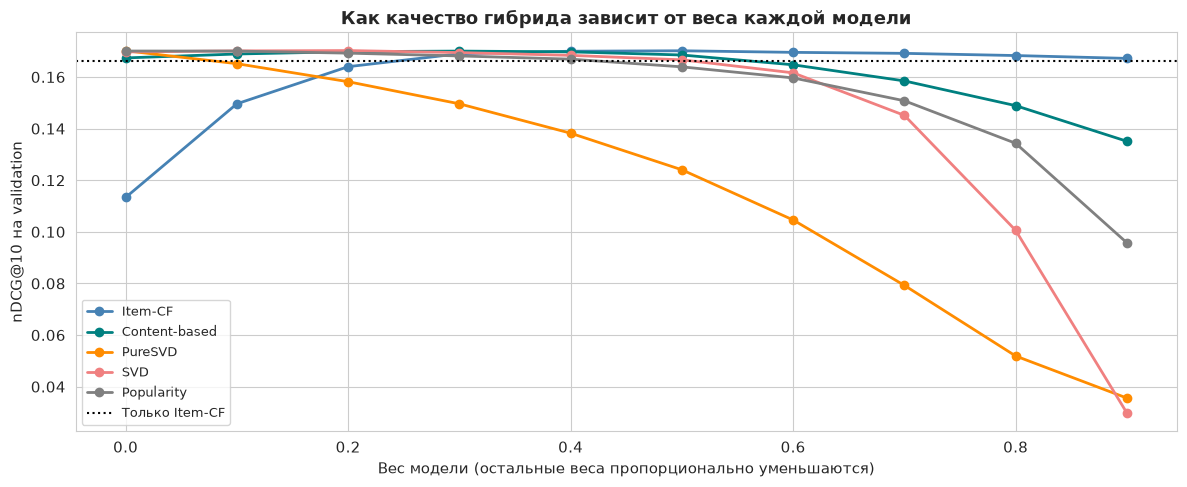

In [28]:
# Чувствительность к весам: меняю вес одной модели, остальные веса пропорционально подстраиваю
sensitivity_values = np.arange(0, 0.91, 0.1)
fig, ax = plt.subplots(figsize=(12, 5))
line_colors = ['steelblue', 'teal', 'darkorange', 'lightcoral', 'gray']
for model_index, model_name in enumerate(POOL_MODEL_NAMES):
    ndcg_values = []
    for new_weight in sensitivity_values:
        vector = best_weights.copy()
        other_sum = vector.sum() - vector[model_index]
        if other_sum > 0:
            vector = vector * (1 - new_weight) / other_sum
        vector[model_index] = new_weight
        slots = top_k_slots(hybrid_scores_from_vector(valid_pool, valid_z, vector))
        ndcg_values.append(metrics_from_slots(valid_pool, slots)['ndcg'].mean())
    ax.plot(sensitivity_values, ndcg_values, marker='o', color=line_colors[model_index], linewidth=2, label=model_name)
ax.axhline(item_cf_valid_ndcg, color='black', linestyle=':', linewidth=1.5, label='Только Item-CF')
ax.set_xlabel('Вес модели (остальные веса пропорционально уменьшаются)')
ax.set_ylabel('nDCG@10 на validation')
ax.set_title('Как качество гибрида зависит от веса каждой модели', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'hybrid_weights.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Подобранные веса: Item-CF 0.5, Content 0.3, SVD 0.2, Popularity 0.05

- Лучшая комбинация на validation даёт **nDCG@10 = 0.170 против 0.166 у одной Item-CF**, то есть прирост около 2%. Небольшой, но это лучшая точка из 858.
- **Item-CF остаётся основой** (0.5), Content-based добавляет книги, похожие по содержанию (0.3).
- Неожиданно полезным оказался **SVD с весом 0.2**. Одна SVD ранжирует почти случайно, но в гибриде она решает другую задачу: среди книг, которые Item-CF и Content уже сочли связанными с историей, она поднимает те, которые пользователю скорее понравятся. Это ровно то, что показал раздел 3.4: схожесть отвечает на "прочитает ли", а прогноз оценки - на "понравится ли".
- **PureSVD получила вес 0:** её сигнал почти полностью повторяет Item-CF (тоже "кто что читал"), но слабее.
- **Вес Popularity 0.05 на деле ничего не даёт:** на validation 0.1702 против 0.1701 с весом 0, на test разница -0.00002 +- 0.00019 (раздел 5.3). Перебор оставил вес больше нуля только из-за разницы в пятом знаке. Пользователям с историей популярность ничего не добавляет: в нашей выборке она почти не связана с тем, что человек читает (раздел 1.2).
- По графику чувствительности видно, что оптимум пологий. Вес Item-CF от 0.3 до 0.9 даёт почти одинаковый результат, а без Item-CF (вес 0) качество падает до 0.113: без неё гибрид не работает. Большие веса SVD (больше 0.6), Popularity (больше 0.5) и Content-based (больше 0.6) быстро портят качество, а PureSVD вредит уже с веса 0.1.

**Нужны ли разным типам пользователей разные веса?** Задание требует разделять пользователей по типам, поэтому проверяю это честно, кросс-валидацией на validation. Делю 15 000 пользователей на две половины: на одной подбираю веса (общие и отдельно для каждого сегмента), на другой проверяю, потом меняю половины местами. Если сегментные веса не лучше общих на "чужой" половине, значит их различие - подгонка под шум.

In [29]:
# Общие веса против отдельных весов для каждого сегмента: кросс-валидация на двух половинах validation
valid_segments = user_features_fit['user_segment'].values[valid_pool['user_ids'] - 1]
print("Сегменты пользователей validation:")
for segment_name in USER_SEGMENT_NAMES[1:]:
    print(f"  {segment_name:<24} {(valid_segments == segment_name).sum():>6}")
print()

cv_rng = np.random.default_rng(RANDOM_STATE)
permutation = cv_rng.permutation(len(valid_pool['user_ids']))
halves = [permutation[:len(permutation) // 2], permutation[len(permutation) // 2:]]

start_time = time.perf_counter()
cv_rows = []
for fold in range(2):
    fit_rows = halves[fold]
    check_rows = halves[1 - fold]
    fit_pool = subset_pool(valid_pool, fit_rows)
    check_pool = subset_pool(valid_pool, check_rows)
    fit_z = valid_z[fit_rows]
    check_z = valid_z[check_rows]

    # Общие веса
    global_vector, fit_results = grid_search(fit_pool, fit_z)
    global_ndcg = metrics_from_slots(check_pool, top_k_slots(hybrid_scores_from_vector(check_pool, check_z, global_vector)))['ndcg']
    item_cf_ndcg = metrics_from_slots(check_pool, top_k_slots(hybrid_scores_from_vector(check_pool, check_z, item_cf_vector)))['ndcg']

    # Отдельные веса для каждого сегмента
    segment_ndcg = np.zeros(len(check_rows))
    for segment_name in USER_SEGMENT_NAMES[1:]:
        fit_segment_rows = np.where(valid_segments[fit_rows] == segment_name)[0]
        check_segment_rows = np.where(valid_segments[check_rows] == segment_name)[0]
        segment_vector, segment_results = grid_search(subset_pool(fit_pool, fit_segment_rows), fit_z[fit_segment_rows])
        segment_check_pool = subset_pool(check_pool, check_segment_rows)
        segment_slots = top_k_slots(hybrid_scores_from_vector(segment_check_pool, check_z[check_segment_rows], segment_vector))
        segment_ndcg[check_segment_rows] = metrics_from_slots(segment_check_pool, segment_slots)['ndcg']
        print(f"Половина {fold + 1}, {segment_name:<24} веса: {format_weights(segment_vector)}")

    cv_rows.append({'проверочная половина': fold + 1, 'Только Item-CF': item_cf_ndcg.mean(),
                    'Общие веса': global_ndcg.mean(), 'Веса по сегментам': segment_ndcg.mean()})
print(f"Время: {time.perf_counter() - start_time:.0f} с")
print()
print("nDCG@10 на проверочной половине:")
display(pd.DataFrame(cv_rows).set_index('проверочная половина').round(4))

Сегменты пользователей validation:
  Короткая история (1-4)     3828
  Средняя (5-19)             6751
  Активный (20+)             4421



Половина 1, Короткая история (1-4)   веса: Item-CF 0.80, Content-based 0.20, PureSVD 0.00, SVD 0.00, Popularity 0.00


Половина 1, Средняя (5-19)           веса: Item-CF 0.60, Content-based 0.20, PureSVD 0.00, SVD 0.20, Popularity 0.05


Половина 1, Активный (20+)           веса: Item-CF 0.40, Content-based 0.40, PureSVD 0.00, SVD 0.20, Popularity 0.00


Половина 2, Короткая история (1-4)   веса: Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.00


Половина 2, Средняя (5-19)           веса: Item-CF 0.70, Content-based 0.30, PureSVD 0.00, SVD 0.00, Popularity 0.10


Половина 2, Активный (20+)           веса: Item-CF 0.40, Content-based 0.50, PureSVD 0.00, SVD 0.10, Popularity 0.05
Время: 220 с

nDCG@10 на проверочной половине:


,Только Item-CF,Общие веса,Веса по сегментам
проверочная половина,,,
1,0.1635,0.1668,0.1668
2,0.1693,0.1729,0.1731


#### Отдельные веса для сегментов не дают выигрыша

- Сегментные веса различаются, но не всегда одинаково в двух половинах. Активным пользователям обе половины дают больше веса Content-based (0.4 и 0.5 против 0.3 в общих весах): у активных длинная история, и контентный профиль по ней надёжнее. А пользователям с короткой историей первая половина даёт больше веса Item-CF (0.8), вторая - те же веса, что общие (Item-CF 0.5).
- Но на "чужой" половине сегментные веса работают так же, как общие: разница в четвёртом знаке, в одну и в другую сторону. Различие весов - в основном подгонка под конкретных пользователей, а обобщается только общая картина.
- **Решение:** гибрид использует одни общие веса для всех пользователей с историей. Разделение по типам остаётся там, где оно действительно меняет стратегию: новый пользователь без оценок получает популярные книги (раздел 4.3). Как гибрид работает в каждом сегменте, проверю на test в разделе 5.4.

### 5.2 Подбор lambda для MMR на validation

С подобранными весами прогоняю MMR при разных lambda на 5000 пользователях validation: MMR считается в цикле по пользователям, и 5000 хватает, чтобы увидеть картину. Для каждого lambda считаю nDCG@10 и метрики разнообразия из раздела 4.4.

Время: 63 с


,nDCG@10,ILD,категорий в top-10,доля книг одной серии
lambda,,,,
1.0,0.1644,0.7157,2.4196,0.3251
0.9,0.1653,0.7271,2.4988,0.3008
0.8,0.1665,0.7404,2.6020,0.2753
0.7,0.1672,0.7578,2.7328,0.2459
0.6,0.1671,0.7794,2.9056,0.2115
0.5,0.1639,0.8096,3.1336,0.1612
0.4,0.1522,0.8480,3.3988,0.0887


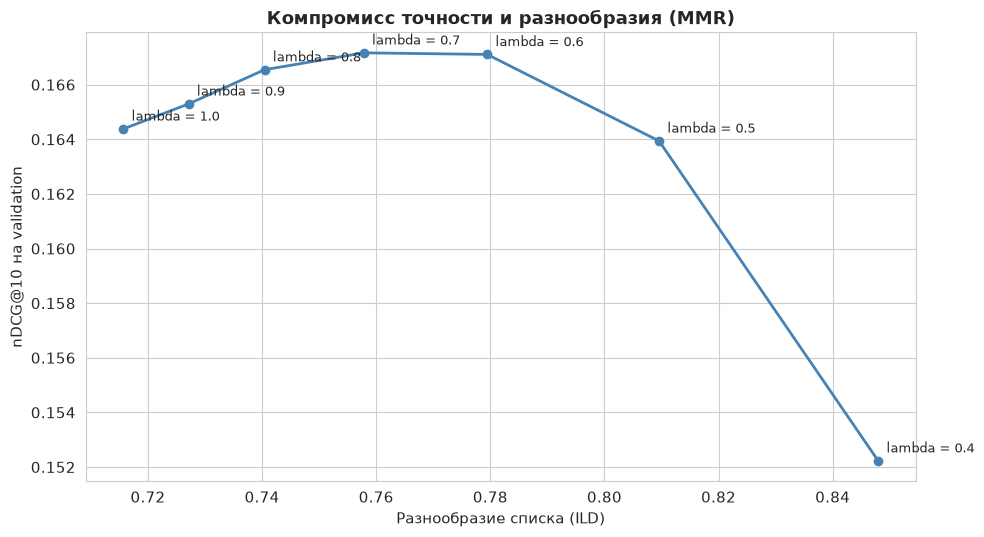

In [30]:
# Точность и разнообразие при разных lambda (5000 пользователей validation, подобранные веса)
lambda_pool = subset_pool(valid_pool, np.arange(5000))
lambda_scores = hybrid_scores_from_vector(lambda_pool, valid_z[:5000], best_weights)

start_time = time.perf_counter()
lambda_rows = []
for mmr_lambda in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4]:
    chosen = mmr_rerank(lambda_pool, lambda_scores, mmr_lambda)
    diversity = diversity_metrics(lambda_pool, chosen)
    lambda_rows.append({
        'lambda': mmr_lambda,
        'nDCG@10': metrics_from_slots(lambda_pool, chosen)['ndcg'].mean(),
        'ILD': diversity['ILD'],
        'категорий в top-10': diversity['категорий в top-10'],
        'доля книг одной серии': diversity['доля книг одной серии'],
    })
lambda_table = pd.DataFrame(lambda_rows).set_index('lambda')
print(f"Время: {time.perf_counter() - start_time:.0f} с")
display(lambda_table.round(4))

# Компромисс точности и разнообразия
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(lambda_table['ILD'], lambda_table['nDCG@10'], marker='o', color='steelblue', linewidth=2)
for mmr_lambda in lambda_table.index:
    ax.annotate(f'lambda = {mmr_lambda}', (lambda_table.loc[mmr_lambda, 'ILD'], lambda_table.loc[mmr_lambda, 'nDCG@10']),
                textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_xlabel('Разнообразие списка (ILD)')
ax.set_ylabel('nDCG@10 на validation')
ax.set_title('Компромисс точности и разнообразия (MMR)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'hybrid_mmr_tradeoff.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Выбираю lambda = 0.6: та же точность, заметно разнообразнее

- От lambda = 1 до 0.7 точность растёт (0.1644 -> 0.1672), и одновременно растёт разнообразие. MMR убирает из топа лишние тома одной серии, а на освободившиеся места попадают другие понравившиеся книги.
- lambda = 0.7 и 0.6 дают одинаковую точность (0.1672 и 0.1671, разница намного меньше погрешности). Но при 0.6 списки разнообразнее: ILD 0.779 против 0.758, доля книг одной серии 0.21 против 0.25.
- Дальше начинается настоящий компромисс: при 0.5 точность уже ниже, чем без MMR (0.1639), а при 0.4 падает до 0.152. Гибрид начинает предпочитать "непохожие" книги релевантным.
- **Решение:** lambda = 0.6. По сравнению с гибридом без MMR точность выше на 1.6%, доля книг одной серии ниже примерно на треть (0.325 -> 0.211), а категорий в списке больше (2.4 -> 2.9).

**Честная база для гибрида: Item-CF + MMR.** В разделе 4.4 MMR улучшил даже одну Item-CF. Значит, если сравнивать гибрид + MMR с Item-CF без MMR, часть выигрыша гибрида на самом деле принесёт MMR. Чтобы разделить эти эффекты, подбираю lambda и для Item-CF + MMR на тех же 5000 пользователях validation. Правило выбора то же, что для ранжировщика в разделе 6.4: самое маленькое lambda, у которого nDCG@10 ниже максимума не больше чем на 0.0005 (это меньше погрешности). Для гибрида это правило даёт то же lambda = 0.6, что выбрано выше.

In [31]:
# MMR поверх одной Item-CF: подбор lambda на тех же 5000 пользователях validation.
# Это честная база для гибрида + MMR: MMR сам по себе улучшает Item-CF (раздел 4.4), и нужно понять,
# какая часть выигрыша гибрида + MMR приходится на MMR, а какая - на объединение моделей
item_cf_lambda_scores = hybrid_scores_from_vector(lambda_pool, valid_z[:5000], item_cf_vector)
item_cf_lambda_rows = []
for mmr_lambda in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    chosen = mmr_rerank(lambda_pool, item_cf_lambda_scores, mmr_lambda)
    diversity = diversity_metrics(lambda_pool, chosen)
    item_cf_lambda_rows.append({
        'lambda': mmr_lambda,
        'nDCG@10': metrics_from_slots(lambda_pool, chosen)['ndcg'].mean(),
        'ILD': diversity['ILD'],
        'доля книг одной серии': diversity['доля книг одной серии'],
    })
item_cf_lambda_table = pd.DataFrame(item_cf_lambda_rows).set_index('lambda')
print("Item-CF + MMR на validation:")
display(item_cf_lambda_table.round(4))

# Правило выбора то же, что для ранжировщика в разделе 6.4: самое маленькое lambda, у которого nDCG@10
# ниже максимума не больше чем на 0.0005. Для гибрида это правило тоже даёт выбранное выше lambda = 0.6
best_item_cf_lambda_ndcg = item_cf_lambda_table['nDCG@10'].max()
ITEM_CF_MMR_LAMBDA = 1.0
for mmr_lambda in item_cf_lambda_table.index:
    if item_cf_lambda_table.loc[mmr_lambda, 'nDCG@10'] >= best_item_cf_lambda_ndcg - 0.0005:
        ITEM_CF_MMR_LAMBDA = mmr_lambda    # lambda идут по убыванию, останется самое маленькое подходящее
print(f"Item-CF + MMR: выбрано lambda = {ITEM_CF_MMR_LAMBDA}")
print(f"Для сравнения на тех же пользователях: гибрид + MMR (lambda = 0.6) {lambda_table.loc[0.6, 'nDCG@10']:.4f}, "
      f"Item-CF + MMR {item_cf_lambda_table.loc[ITEM_CF_MMR_LAMBDA, 'nDCG@10']:.4f}")


Item-CF + MMR на validation:


,nDCG@10,ILD,доля книг одной серии
lambda,,,
1.0,0.1599,0.7396,0.3209
0.9,0.1604,0.7507,0.2959
0.8,0.1608,0.7656,0.2685
0.7,0.1610,0.7833,0.2377
0.6,0.1603,0.8062,0.2000
0.5,0.1559,0.8387,0.1470


Item-CF + MMR: выбрано lambda = 0.7
Для сравнения на тех же пользователях: гибрид + MMR (lambda = 0.6) 0.1671, Item-CF + MMR 0.1610


- MMR помогает и одной Item-CF: nDCG@10 растёт с 0.1599 (lambda = 1) до 0.1610 (lambda = 0.7), а доля книг одной серии падает с 0.32 до 0.24. Выбрано **lambda = 0.7**: при 0.6 точность уже на 0.0007 ниже максимума.
- Гибрид + MMR на тех же пользователях всё равно заметно лучше: 0.1671 против 0.1610. Подтвердится ли это на test, проверю в разделе 5.3.

### 5.3 Сравнение гибрида с отдельными моделями на test

Итоговое сравнение на всех 34 288 пользователях test. Модели обучены на `train_full`, веса и lambda зафиксированы на validation. Сравниваю:
- пять отдельных моделей (их top-10 из пула совпадают с разделом 2.4),
- Item-CF + MMR (lambda = 0.7 из раздела 5.2): чтобы отделить вклад MMR от вклада объединения моделей,
- гибрид с весами "на глаз" из раздела 4 (чтобы видеть эффект подбора весов),
- гибрид с подобранными весами,
- гибрид с подобранными весами и MMR (lambda = 0.6).

Метрики точности считаю на всех пользователях. Метрики разнообразия считаю на 5000 случайных пользователях: они требуют цикла по пользователям, а 5000 для средних значений достаточно. Добавляю **покрытие каталога**: какая доля из 10 000 книг попала хотя бы в один top-10.

Для гибридов считаю 95% доверительный интервал разницы nDCG@10 с Item-CF по парам "пользователь - пользователь". Так видно, не случаен ли выигрыш.

In [32]:
# Итоговое сравнение на test
MMR_LAMBDA = 0.6
test_z = get_z_tensor(test_pool)
test_methods = {
    'Popularity': np.array([0.0, 0.0, 0.0, 0.0, 1.0]),
    'Content-based': np.array([0.0, 1.0, 0.0, 0.0, 0.0]),
    'Item-CF': item_cf_vector,
    'SVD': np.array([0.0, 0.0, 0.0, 1.0, 0.0]),
    'PureSVD': np.array([0.0, 0.0, 1.0, 0.0, 0.0]),
    'Гибрид (веса на глаз)': np.array([0.6, 0.3, 0.1, 0.0, 0.0]),
    'Гибрид (подобранные веса)': best_weights,
}

start_time = time.perf_counter()
test_slots = {}
for method_name, weight_vector in test_methods.items():
    method_scores = hybrid_scores_from_vector(test_pool, test_z, weight_vector)
    test_slots[method_name] = top_k_slots(method_scores)
# Item-CF + MMR (lambda из раздела 5.2): база, чтобы отделить вклад MMR от вклада объединения моделей
item_cf_test_scores = hybrid_scores_from_vector(test_pool, test_z, item_cf_vector)
test_slots['Item-CF + MMR'] = mmr_rerank(test_pool, item_cf_test_scores, ITEM_CF_MMR_LAMBDA)
# Гибрид с MMR: переранжирую top-50 гибрида с подобранными весами
hybrid_test_scores = hybrid_scores_from_vector(test_pool, test_z, best_weights)
test_slots['Гибрид + MMR'] = mmr_rerank(test_pool, hybrid_test_scores, MMR_LAMBDA)
print(f"Списки построены за {time.perf_counter() - start_time:.0f} с")

# Метрики точности при K = 5 и 10 на всех пользователях
test_metrics = {}
comparison_rows = []
for method_name, slots in test_slots.items():
    row = {'Модель': method_name}
    for k in K_VALUES:
        metrics = metrics_from_slots(test_pool, slots[:, :k])
        row[f'Precision@{k}'] = metrics['precision'].mean()
        row[f'Recall@{k}'] = metrics['recall'].mean()
        row[f'nDCG@{k}'] = metrics['ndcg'].mean()
        if k == 10:
            test_metrics[method_name] = metrics
    comparison_rows.append(row)

# Разнообразие и покрытие каталога на 5000 случайных пользователях
diversity_rng = np.random.default_rng(RANDOM_STATE)
diversity_rows = np.sort(diversity_rng.choice(len(test_pool['user_ids']), size=5000, replace=False))
diversity_pool = subset_pool(test_pool, diversity_rows)
for row in comparison_rows:
    slots = test_slots[row['Модель']][diversity_rows]
    diversity = diversity_metrics(diversity_pool, slots)
    row['ILD'] = diversity['ILD']
    row['категорий в top-10'] = diversity['категорий в top-10']
    row['доля одной серии'] = diversity['доля книг одной серии']
    recommended_positions = np.take_along_axis(diversity_pool['positions'], slots, axis=1)
    row['покрытие каталога, %'] = len(np.unique(recommended_positions)) / n_books * 100

hybrid_comparison = pd.DataFrame(comparison_rows).set_index('Модель')
print("Сравнение на test (точность - 34 288 пользователей, разнообразие - 5000):")
display(hybrid_comparison.round(4))

# Насколько выигрыш гибридов над Item-CF надёжен: разница по парам пользователей
print("Разница nDCG@10 с Item-CF (среднее и 95% доверительный интервал):")
for method_name in ['Item-CF + MMR', 'Гибрид (веса на глаз)', 'Гибрид (подобранные веса)', 'Гибрид + MMR']:
    difference = test_metrics[method_name]['ndcg'] - test_metrics['Item-CF']['ndcg']
    half_width = 1.96 * difference.std() / np.sqrt(len(difference))
    relative = difference.mean() / test_metrics['Item-CF']['ndcg'].mean() * 100
    print(f"  {method_name:<27} {difference.mean():+.4f} +- {half_width:.4f} ({relative:+.1f}%)")

# Вклад самого объединения моделей: гибрид + MMR против Item-CF + MMR (MMR есть у обоих)
difference = test_metrics['Гибрид + MMR']['ndcg'] - test_metrics['Item-CF + MMR']['ndcg']
half_width = 1.96 * difference.std() / np.sqrt(len(difference))
relative = difference.mean() / test_metrics['Item-CF + MMR']['ndcg'].mean() * 100
print(f"  {'Гибрид + MMR к Item-CF + MMR':<27} {difference.mean():+.4f} +- {half_width:.4f} ({relative:+.1f}%)")

# Вклад веса Popularity: те же подобранные веса, но вес Popularity равен 0
no_popularity_vector = best_weights.copy()
no_popularity_vector[POOL_MODEL_NAMES.index('Popularity')] = 0.0
no_popularity_ndcg = metrics_from_slots(test_pool, top_k_slots(
    hybrid_scores_from_vector(test_pool, test_z, no_popularity_vector)))['ndcg']
difference = test_metrics['Гибрид (подобранные веса)']['ndcg'] - no_popularity_ndcg
half_width = 1.96 * difference.std() / np.sqrt(len(difference))
print()
print(f"Вклад веса Popularity {best_weights[POOL_MODEL_NAMES.index('Popularity')]:.2f} в гибрид на test: "
      f"{difference.mean():+.5f} +- {half_width:.5f}")


Списки построены за 68 с


Сравнение на test (точность - 34 288 пользователей, разнообразие - 5000):


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,ILD,категорий в top-10,доля одной серии,"покрытие каталога, %"
Модель,,,,,,,,,,
Popularity,0.0005,0.0009,0.0008,0.0006,0.0017,0.0012,0.7127,3.9988,0.1994,0.16
Content-based,0.0781,0.1262,0.1312,0.0559,0.1691,0.1413,0.6263,1.9490,0.2827,75.73
Item-CF,0.1187,0.1926,0.2039,0.0817,0.2502,0.2154,0.7370,2.3886,0.3086,83.07
SVD,0.0006,0.0009,0.0008,0.0006,0.0017,0.0011,0.8157,3.7432,0.0253,3.49
PureSVD,0.0318,0.0238,0.0374,0.0258,0.0397,0.0389,0.6084,1.7768,0.4824,23.96
Гибрид (веса на глаз),0.1166,0.1896,0.2009,0.0804,0.2454,0.2119,0.7117,2.2334,0.3162,83.16
Гибрид (подобранные веса),0.1203,0.1946,0.2064,0.0826,0.2524,0.2177,0.7133,2.2528,0.3161,83.08
Item-CF + MMR,0.1216,0.1975,0.2076,0.0834,0.2544,0.2188,0.7822,2.7708,0.2193,84.95
Гибрид + MMR,0.1250,0.2021,0.2123,0.0856,0.2602,0.2236,0.7776,2.7038,0.1933,85.30


Разница nDCG@10 с Item-CF (среднее и 95% доверительный интервал):
  Item-CF + MMR               +0.0034 +- 0.0005 (+1.6%)
  Гибрид (веса на глаз)       -0.0035 +- 0.0007 (-1.6%)
  Гибрид (подобранные веса)   +0.0023 +- 0.0007 (+1.1%)
  Гибрид + MMR                +0.0083 +- 0.0008 (+3.8%)
  Гибрид + MMR к Item-CF + MMR +0.0049 +- 0.0007 (+2.2%)



Вклад веса Popularity 0.05 в гибрид на test: -0.00002 +- 0.00019


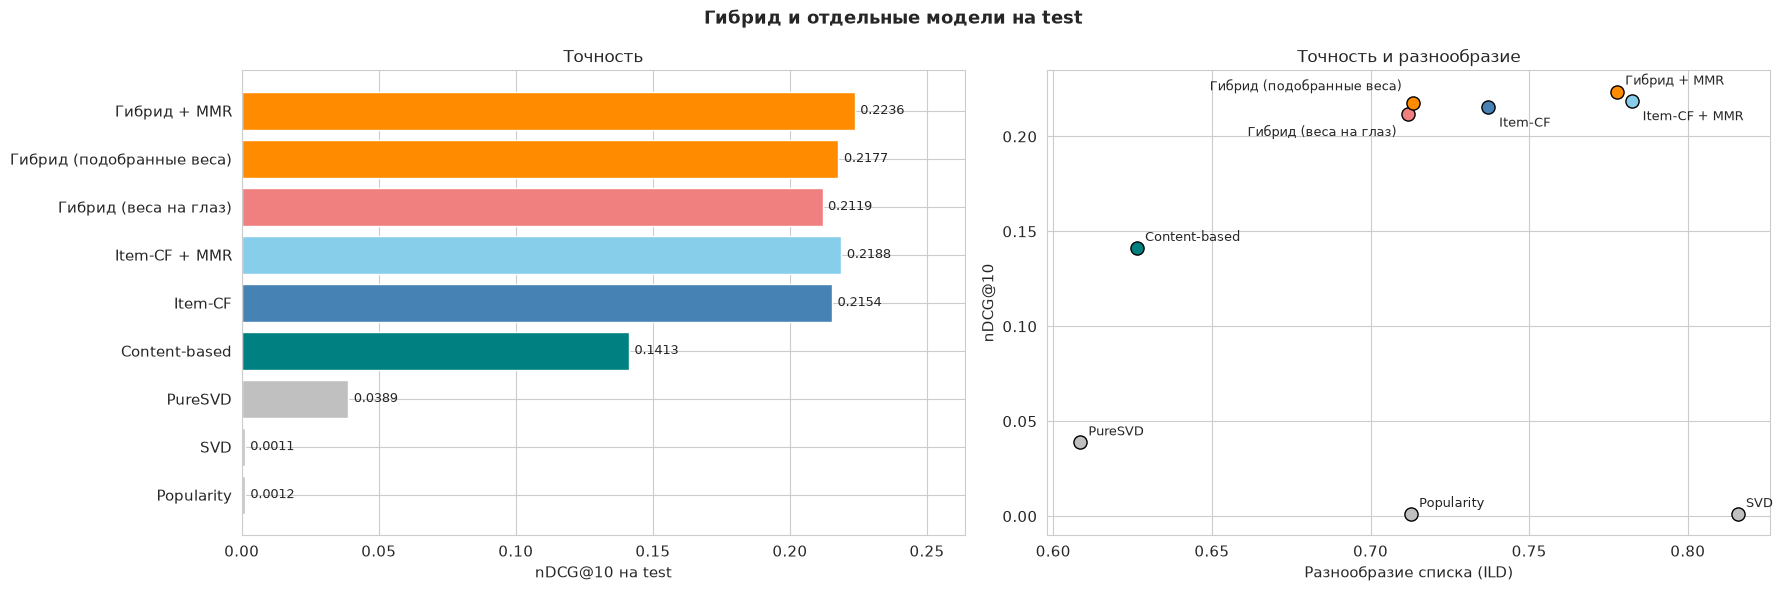

In [33]:
# График: точность и разнообразие моделей на test
plot_order = ['Popularity', 'SVD', 'PureSVD', 'Content-based', 'Item-CF', 'Item-CF + MMR',
              'Гибрид (веса на глаз)', 'Гибрид (подобранные веса)', 'Гибрид + MMR']
plot_colors = ['silver', 'silver', 'silver', 'teal', 'steelblue', 'skyblue', 'lightcoral', 'darkorange', 'darkorange']
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ndcg_values = hybrid_comparison.loc[plot_order, 'nDCG@10'].values
bars = axes[0].barh(range(len(plot_order)), ndcg_values, color=plot_colors, edgecolor='white')
for i in range(len(plot_order)):
    axes[0].text(ndcg_values[i] + 0.002, i, f'{ndcg_values[i]:.4f}', va='center', fontsize=9)
axes[0].set_yticks(range(len(plot_order)))
axes[0].set_yticklabels(plot_order)
axes[0].set_xlim(0, ndcg_values.max() * 1.18)
axes[0].set_xlabel('nDCG@10 на test')
axes[0].set_title('Точность', fontsize=12)

# Смещения подписей, чтобы близкие точки не перекрывали друг друга
label_offsets = {'Item-CF': (8, -14), 'Item-CF + MMR': (8, -14), 'Гибрид (веса на глаз)': (-8, -16),
                 'Гибрид (подобранные веса)': (-8, 9)}
label_alignment = {'Гибрид (веса на глаз)': 'right', 'Гибрид (подобранные веса)': 'right'}
for i, method_name in enumerate(plot_order):
    point = (hybrid_comparison.loc[method_name, 'ILD'], hybrid_comparison.loc[method_name, 'nDCG@10'])
    axes[1].scatter(point[0], point[1], s=90, color=plot_colors[i], edgecolor='black', zorder=3)
    axes[1].annotate(method_name, point, textcoords='offset points', xytext=label_offsets.get(method_name, (6, 5)),
                     ha=label_alignment.get(method_name, 'left'), fontsize=9)
axes[1].set_xlabel('Разнообразие списка (ILD)')
axes[1].set_ylabel('nDCG@10')
axes[1].set_title('Точность и разнообразие', fontsize=12)

plt.suptitle('Гибрид и отдельные модели на test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'hybrid_test_comparison.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Гибрид лучше всех отдельных моделей, но выигрыш у Item-CF небольшой

- **Лучший результат - гибрид с подобранными весами и MMR:** nDCG@10 = 0.2236 против 0.2154 у Item-CF, то есть +0.0083 +- 0.0008 (+3.8%). Доверительный интервал далеко от нуля, выигрыш не случайный. Precision@10 тоже выше (0.0856 против 0.0817), Recall@10 - 0.260 против 0.250.
- **Но часть этого выигрыша даёт сам MMR.** Item-CF + MMR без всякого гибрида даёт 0.2188, то есть +1.6% к Item-CF. Гибрид + MMR лучше Item-CF + MMR на +0.0049 +- 0.0007 (+2.2%). Значит, из +3.8% примерно 1.6% приносит MMR, а объединение моделей добавляет ещё около 2.2%. Оба вклада значимы.
- **Подобранные веса без MMR** дают +1.1% (0.2177). А **веса "на глаз" хуже одной Item-CF** (0.2119, -1.6%): гибрид без настройки весов может только навредить. Это прямое подтверждение, что оптимизация весов на validation нужна.
- **MMR даёт больше, чем подбор весов:** у гибрида ещё +2.7% сверху. И он же делает списки разнообразнее: ILD 0.713 -> 0.778, категорий в top-10 2.25 -> 2.70, доля книг одной серии 0.316 -> 0.193, покрытие каталога 83.1% -> 85.3%. У Item-CF + MMR разнообразие почти такое же (ILD 0.782, доля одной серии 0.219, покрытие 85.0%). Здесь разнообразие и точность не конкурируют, а помогают друг другу.
- **Вес Popularity** в гибриде на test ничего не меняет: -0.00002 +- 0.00019.
- Отдельные модели - как в ДЗ: Content-based 0.141, PureSVD 0.039, SVD и Popularity на уровне случайных. Высокое разнообразие у SVD и Popularity (ILD 0.82 и 0.71) - не достоинство. Это разнородные общепризнанные книги, почти одинаковые для всех: они покрывают 3.5% и 0.16% каталога.
- **Почему выигрыш всего 3.8%:** Item-CF уже ловит главный сигнал данных (что читают одни и те же люди, продолжения серий). Остальные модели в основном повторяют её кандидатов (раздел 4.1), а линейное усреднение с одними весами для всех не умеет решать, когда какой модели доверять. Это задача для ранжировщика в разделе 6.

### 5.4 Эффективность для разных сегментов пользователей

Смотрю nDCG@10 на test отдельно по сегментам раздела 3.1. Новых пользователей среди оцениваемых нет (для оценки нужна история), поэтому для них отдельной строкой беру результат популярных книг из раздела 4.3.

,Пользователей,Popularity,Content-based,Item-CF,Item-CF + MMR,PureSVD,Гибрид (подобранные веса),Гибрид + MMR,"Item-CF + MMR к Item-CF, %","Гибрид + MMR к Item-CF, %"
Сегмент,,,,,,,,,,
Короткая история (1-4),8188,0.0011,0.1268,0.1929,0.1934,0.0030,0.1936,0.1940,0.2230,0.5441
Средняя (5-19),14516,0.0012,0.1393,0.2175,0.2215,0.0174,0.2184,0.2248,1.8304,3.3340
Активный (20+),11584,0.0012,0.1539,0.2285,0.2333,0.0911,0.2340,0.2432,2.0933,6.4120


Новые пользователи (0 оценок), раздел 4.3: 376 пользователей, Popularity nDCG@10 = 0.0059


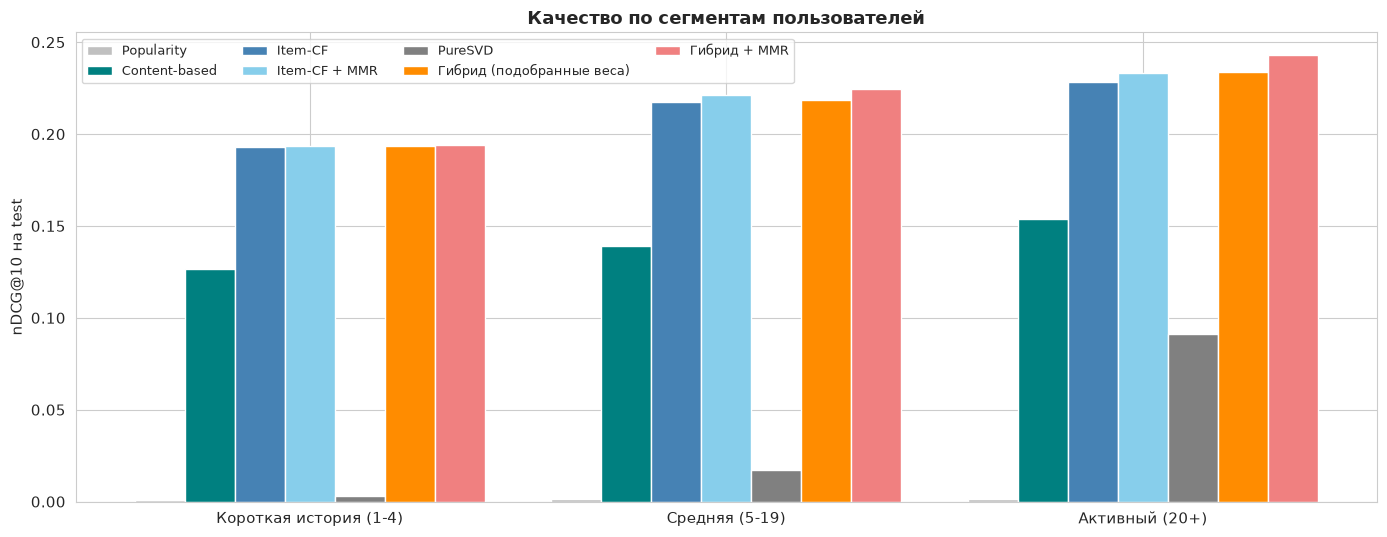

In [34]:
# nDCG@10 по сегментам пользователей на test
test_pool_segments = user_features_full['user_segment'].values[test_pool['user_ids'] - 1]
segment_methods = ['Popularity', 'Content-based', 'Item-CF', 'Item-CF + MMR', 'PureSVD',
                   'Гибрид (подобранные веса)', 'Гибрид + MMR']
segment_rows = []
for segment_name in USER_SEGMENT_NAMES[1:]:
    segment_mask = test_pool_segments == segment_name
    row = {'Сегмент': segment_name, 'Пользователей': segment_mask.sum()}
    for method_name in segment_methods:
        row[method_name] = test_metrics[method_name]['ndcg'][segment_mask].mean()
    row['Item-CF + MMR к Item-CF, %'] = (row['Item-CF + MMR'] - row['Item-CF']) / row['Item-CF'] * 100
    row['Гибрид + MMR к Item-CF, %'] = (row['Гибрид + MMR'] - row['Item-CF']) / row['Item-CF'] * 100
    segment_rows.append(row)
segment_table = pd.DataFrame(segment_rows).set_index('Сегмент')
display(segment_table.round(4))
print(f"Новые пользователи (0 оценок), раздел 4.3: {len(cold_user_ids)} пользователей, Popularity nDCG@10 = {np.mean(cold_ndcg):.4f}")

# График по сегментам
fig, ax = plt.subplots(figsize=(14, 5.5))
segment_positions = np.arange(len(segment_table))
bar_width = 0.12
segment_colors = ['silver', 'teal', 'steelblue', 'skyblue', 'gray', 'darkorange', 'lightcoral']
for method_index, method_name in enumerate(segment_methods):
    offsets = segment_positions + (method_index - 3) * bar_width
    ax.bar(offsets, segment_table[method_name].values, width=bar_width, color=segment_colors[method_index],
           edgecolor='white', label=method_name)
ax.set_xticks(segment_positions)
ax.set_xticklabels(segment_table.index)
ax.set_ylabel('nDCG@10 на test')
ax.set_title('Качество по сегментам пользователей', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, ncol=4)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'hybrid_segments.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Чем длиннее история, тем лучше работают все персональные модели и тем больше выигрыш гибрида

- **Все персональные модели лучше работают при длинной истории.** Item-CF: 0.193 (1-4 оценки) -> 0.218 (5-19) -> 0.229 (20+). Content-based: 0.127 -> 0.139 -> 0.154. Сильнее всех от истории зависит PureSVD: 0.003 -> 0.017 -> 0.091, ей для осмысленных факторов нужно много оценок.
- **Выигрыш гибрида + MMR над Item-CF растёт с активностью:** +0.5% у пользователей с 1-4 оценками (0.1940 против 0.1929, почти ничего), +3.3% при 5-19 оценках (0.2248 против 0.2175) и +6.4% у активных (0.2432 против 0.2285).
- Причина: при 1-4 книгах в истории другим моделям почти не на что опереться, и гибрид фактически повторяет Item-CF. У активных пользователей контентный профиль надёжнее, а в списке Item-CF больше однотипных книг, которые убирает MMR.
- **Item-CF + MMR** даёт к Item-CF +0.2% / +1.8% / +2.1% по сегментам, гибрид + MMR - +0.5% / +3.3% / +6.4%. У пользователей с 1-4 оценками гибрид почти равен Item-CF + MMR (0.1940 против 0.1934): объединение моделей им ничего не даёт. А у активных гибрид заметно лучше (0.2432 против 0.2333).
- **Новые пользователи без истории - самый слабый сегмент:** популярные книги дают им nDCG@10 = 0.006.
- **Вывод для выбора модели:** пользователям с 1-4 оценками достаточно Item-CF (с MMR или без), гибрид им почти ничего не добавляет. Для пользователей с 5 и более оценками гибрид с MMR оправдывает свою сложность, и чем длиннее история, тем больше.

### 5.5 Итоги оценки и оптимизации

По трём требованиям этапа 3:
1. **Оптимизация весов.** Перебор 858 комбинаций на validation дал веса Item-CF 0.5, Content-based 0.3, SVD 0.2, Popularity 0.05, PureSVD 0. Отдельные веса для сегментов проверены кросс-валидацией и выигрыша не дали, поэтому веса общие. Для MMR выбрано lambda = 0.6.
2. **Сравнение с отдельными моделями.** Гибрид + MMR - лучший по всем метрикам точности на test (nDCG@10 = 0.2236, +3.8% к Item-CF, выигрыш значим) и при этом разнообразнее Item-CF. Из этих 3.8% около 1.6% даёт сам MMR (Item-CF + MMR - 0.2188), объединение моделей добавляет ещё 2.2%. Без подбора весов гибрид хуже Item-CF.
3. **Сегменты.** Выигрыш гибрида растёт с длиной истории: от +0.5% при 1-4 оценках до +6.4% у активных. Новым пользователям гибрид помочь не может.

**Главное ограничение взвешенного усреднения:** один и тот же набор весов для всех пар (пользователь, книга). Раздел 3.4 показал, что признаки отвечают на разные вопросы ("прочитает ли" и "понравится ли"), и их сочетание зависит от ситуации: например, продолжению серии из истории можно доверять почти всегда. Линейная сумма z-оценок этого не учитывает. Следующий шаг - нейросетевой ранжировщик, который учится сразу на признаках раздела 3 и скорах всех моделей (раздел 6).

## 6. Нейросетевой ранжировщик

По заданию продвинутой части нужно реализовать одну нейросетевую архитектуру, встроить её в гибридную систему и сравнить с классическими методами. Из трёх вариантов задания выбран **нейросетевой ранжировщик**.

**Почему именно ранжировщик.** Разделы 3.4 и 5.5 показали главное ограничение взвешенного усреднения: признаки отвечают на разные вопросы ("прочитает ли" и "понравится ли"), а их удачное сочетание зависит от ситуации. Например, продолжению серии из истории можно доверять почти всегда, а скору Item-CF у пользователя с 2 оценками - меньше, чем у пользователя с 50. Одни общие веса для всех это не учитывают. Ранжировщик - это нейросеть, которая получает 26 признаков пары (пользователь, книга-кандидат) и сама учится, как их сочетать.

**Место в системе.** Ранжировщик заменяет взвешенное усреднение на втором этапе. Пул кандидатов от всех моделей остаётся тем же (раздел 4.1), MMR работает поверх, а новые пользователи по-прежнему получают популярные книги.

### 6.1 Обучающая выборка

- **На чём учится:** пул validation из раздела 4 (15 000 пользователей). Модели, которые дали кандидатов и признаки, обучены на `train_fit`, а метка "книга понравилась" взята из `valid`. Ни одна оценка test в обучение не попадает.
- **Отложенные пользователи:** 20% пользователей validation (3000) не участвуют в обучении. На них идёт ранняя остановка, выбор функции потерь и lambda для MMR, а в разделе 6.5 - важность признаков. Test используется только в итоговом сравнении.
- **Признаки:** 26 признаков: 22 признака раздела 3 и 5 z-оценок моделей без `book_n_ratings`, который протекает информацией о valid и test (проверка ниже). Стандартизирую их по обучающим пользователям и обрезаю до [-5, 5], чтобы редкие огромные значения (например, сумма "схожесть x оценка" у очень активных пользователей) не ломали обучение.
- **Дисбаланс классов:** понравившихся книг в пуле около 1%. Кроме того, у части пользователей в пуле нет ни одной понравившейся книги, и для списочной функции потерь (раздел 6.2) они бесполезны.

In [35]:
# Обучающая выборка ранжировщика: пул validation, 80% пользователей - обучение, 20% - отложены
ranker_rng = np.random.default_rng(RANDOM_STATE)
ranker_permutation = ranker_rng.permutation(len(valid_pool['user_ids']))
ranker_train_rows = np.sort(ranker_permutation[:12000])
ranker_holdout_rows = np.sort(ranker_permutation[12000:])
ranker_train_pool = subset_pool(valid_pool, ranker_train_rows)
ranker_holdout_pool = subset_pool(valid_pool, ranker_holdout_rows)

ALL_FEATURE_INDICES = list(range(len(POOL_FEATURE_COLUMNS)))


def fit_feature_scaler(pool, feature_indices):
    # Среднее и стандартное отклонение каждого признака по заполненным местам пула
    rows = pool['features'][:, :, feature_indices][pool['mask']]
    return rows.mean(axis=0), rows.std(axis=0) + 1e-6


def prepare_tensor(pool, feature_indices, feature_mean, feature_std):
    # Стандартизация, обрезка выбросов и нули на пустых местах пула
    values = (pool['features'][:, :, feature_indices] - feature_mean) / feature_std
    values = np.clip(values, -5, 5)
    values[~pool['mask']] = 0
    return torch.tensor(values, dtype=torch.float32)


train_labels = ranker_train_pool['labels'][ranker_train_pool['mask']]
print(f"Обучение:   {len(ranker_train_rows)} пользователей, {ranker_train_pool['mask'].sum()} пар (пользователь, книга)")
print(f"Отложенные: {len(ranker_holdout_rows)} пользователей")
print(f"Доля понравившихся книг среди кандидатов: {train_labels.mean() * 100:.2f}%")
print(f"Пользователей, у которых в пуле есть понравившаяся книга: "
      f"{(ranker_train_pool['labels'].sum(axis=1) > 0).mean() * 100:.1f}%")

Обучение:   12000 пользователей, 1728692 пар (пользователь, книга)
Отложенные: 3000 пользователей
Доля понравившихся книг среди кандидатов: 1.01%
Пользователей, у которых в пуле есть понравившаяся книга: 64.5%


Пар (пользователь, книга) для обучения много, 1.7 млн, но понравившихся книг среди них всего 1%, поэтому в поточечной функции потерь положительные примеры получат больший вес (раздел 6.2). У трети пользователей (35.5%) в пуле нет ни одной понравившейся книги: в поточечной функции потерь они дают только отрицательные примеры, а в списочной не участвуют.

**Признак `book_n_ratings` в ранжировщик не беру.** В разделе 3.4 у него AUC ниже 0.5: у понравившихся книг оценок в train меньше, чем у случайных. Причина в устройстве выборки, а не в книгах. В этой версии датасета у 62.5% книг ровно 100 оценок (раздел 1.2), а разбиение случайное. Значит, число оценок книги в train равно 100 минус число её оценок, отложенных в valid и test. Если пара (пользователь, книга) лежит в valid, именно эта оценка вычтена из train, и у книги на одну оценку меньше. Признак косвенно знает ответ. Ранжировщик выучил бы эту закономерность на validation и воспользовался бы ею на test, а в реальном сервисе будущие оценки прошлые не уменьшают. Проверяю это на пулах кандидатов.

In [36]:
# Проверка признака book_n_ratings на утечку информации о valid и test.
# У 62.5% книг в выборке ровно 100 оценок (раздел 1.2), а разбиение случайное. Тогда число оценок книги
# в train = 100 - число её оценок в valid и test. Если пара (пользователь, книга) лежит в valid, эта оценка
# вычтена из train, и у понравившихся книг оценок в train должно быть в среднем меньше
total_book_ratings = ratings.groupby('book_id').size().reindex(np.arange(1, n_books + 1)).fillna(0).values
book_n_ratings_index = POOL_FEATURE_COLUMNS.index('book_n_ratings')

leak_rows = []
for pool_name, pool in [('validation', valid_pool), ('test', test_pool)]:
    liked = pool['labels'][pool['mask']] > 0
    positions = pool['positions'][pool['mask']]
    train_count = pool['features'][:, :, book_n_ratings_index][pool['mask']]
    capped = total_book_ratings[positions] == 100
    leak_rows.append({
        'пул': pool_name,
        'книги со 100 оценками, % кандидатов': capped.mean() * 100,
        'оценок в train: понравившиеся': train_count[liked & capped].mean(),
        'оценок в train: остальные': train_count[~liked & capped].mean(),
        'AUC "меньше оценок в train"': roc_auc_score(liked, -train_count),
        'AUC общего числа оценок': roc_auc_score(liked, total_book_ratings[positions]),
    })
print("Признак book_n_ratings у кандидатов пула (понравившиеся книги против остальных):")
display(pd.DataFrame(leak_rows).set_index('пул').round(3))

# Признаки ранжировщика: все признаки пула, кроме book_n_ratings
RANKER_FEATURE_INDICES = []
for feature_index in ALL_FEATURE_INDICES:
    if POOL_FEATURE_COLUMNS[feature_index] != 'book_n_ratings':
        RANKER_FEATURE_INDICES.append(feature_index)
print(f"Признаков в пуле: {len(ALL_FEATURE_INDICES)}, признаков ранжировщика: {len(RANKER_FEATURE_INDICES)}")


Признак book_n_ratings у кандидатов пула (понравившиеся книги против остальных):


,"книги со 100 оценками, % кандидатов",оценок в train: понравившиеся,оценок в train: остальные,"AUC ""меньше оценок в train""",AUC общего числа оценок
пул,,,,,
validation,66.184,63.516998,64.672997,0.556,0.502
test,66.476,79.308998,80.167000,0.555,0.496


Признаков в пуле: 27, признаков ранжировщика: 26


#### Признак `book_n_ratings` протекает, поэтому ранжировщик учится на 26 признаках

- На книги ровно со 100 оценками приходится две трети кандидатов пула (66.2% на validation и 66.5% на test). Среди этих книг у понравившихся пользователю в среднем меньше оценок в train, чем у остальных кандидатов: 63.5 против 64.7 на validation и 79.3 против 80.2 на test. Разница около одной оценки - это та самая оценка, которая ушла в valid или test.
- Поэтому признак "меньше оценок в train" отличает понравившиеся книги с AUC 0.556, хотя общее число оценок книги (без разбиения) не говорит ничего: AUC около 0.50. Сигнал создаёт само разбиение, а не книги.
- Есть и вторая проблема: на validation у книги в среднем около 64 оценок в train (`train_fit`), а на test около 80 (`train_full`). Сеть, обученная на validation, увидела бы на test значения, которых не было в обучении.
- В реальном сервисе такой зависимости не будет, поэтому ранжировщик получает все признаки пула, кроме `book_n_ratings`. Средний рейтинг и разброс оценок книги тоже считаются по train без отложенных оценок, но одна вычтенная оценка из 60-80 почти не сдвигает среднее, поэтому их оставляю.

### 6.2 Архитектура и функции потерь

**Сеть - многослойный перцептрон (MLP):** 26 признаков -> 64 нейрона -> 32 нейрона -> 1 число. Между слоями ReLU, после первого слоя Dropout 0.1 против переобучения. Сеть применяется к каждому кандидату отдельно, и выход - скор книги для пользователя: чем больше, тем выше книга в списке. Сеть маленькая (около 4 тысяч параметров): данных много, а признаки уже содержательные, большая сеть здесь не нужна.

Сравниваю две функции потерь, сеть одна и та же:
- **поточечная (BCE):** каждая пара (пользователь, книга) - отдельный пример бинарной классификации "понравится или нет". Из-за дисбаланса положительные примеры получают вес `pos_weight` = (доля отрицательных) / (доля положительных).
- **списочная (ListNet):** для пользователя скоры всех его кандидатов превращаются в softmax-распределение, и сеть учится отдавать как можно больше вероятности понравившимся книгам. Эта функция прямо оптимизирует порядок книг внутри пользователя, а это и есть задача ранжирования. Пул хранится матрицей "пользователь x место", поэтому такая функция потерь считается одной строкой.

In [37]:
# Нейросетевой ранжировщик: MLP, который выдаёт скор каждого кандидата
class NeuralRanker(nn.Module):
    def __init__(self, n_features, hidden_size=64):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, features):
        # features: пользователи x места x признаки -> скоры: пользователи x места
        return self.layers(features).squeeze(-1)


example_ranker = NeuralRanker(len(RANKER_FEATURE_INDICES))
n_parameters = 0
for parameter in example_ranker.parameters():
    n_parameters += parameter.numel()
print(example_ranker)
print(f"Параметров: {n_parameters}")

NeuralRanker(
  (layers): Sequential(
    (0): Linear(in_features=26, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)
Параметров: 3841


### 6.3 Обучение

- Оптимизатор Adam, шаг 0.001, пачка - 256 пользователей (около 36 тысяч пар).
- До 25 эпох с **ранней остановкой:** после каждой эпохи считаю nDCG@10 на отложенных пользователях и запоминаю лучшую версию сети. Если 4 эпохи подряд качество не растёт, обучение останавливается, и берётся лучшая версия.
- Зерно генератора фиксировано, поэтому обучение воспроизводимо.

Функция `train_neural_ranker` пригодится и дальше: в разделе 6.5 (сеть на z-оценках и логистическая регрессия) и в пайплайне раздела 7.

In [38]:
# Обучение ранжировщика с ранней остановкой по nDCG@10 на отложенных пользователях
RANKER_MAX_EPOCHS = 25
RANKER_PATIENCE = 4
RANKER_BATCH_USERS = 256


def predict_ranker_scores(model, features_tensor, mask):
    # Скоры сети для всех кандидатов, пустые места пула получают -inf
    model.eval()
    with torch.no_grad():
        scores = model(features_tensor).numpy().astype(np.float64)
    scores[~mask] = -np.inf
    return scores


def train_neural_ranker(train_pool, holdout_pool, feature_indices, loss_name, verbose=True, model_class=None):
    # model_class - архитектура сети. По умолчанию NeuralRanker, в разделе 6.5 сюда передаётся линейная модель
    if model_class is None:
        model_class = NeuralRanker
    torch.manual_seed(RANDOM_STATE)
    feature_mean, feature_std = fit_feature_scaler(train_pool, feature_indices)
    train_x = prepare_tensor(train_pool, feature_indices, feature_mean, feature_std)
    holdout_x = prepare_tensor(holdout_pool, feature_indices, feature_mean, feature_std)
    train_y = torch.tensor(train_pool['labels'])
    train_mask = torch.tensor(train_pool['mask'])

    # Для списочной функции потерь нужны пользователи хотя бы с одной понравившейся книгой в пуле
    if loss_name == 'listwise':
        train_rows = np.where(train_pool['labels'].sum(axis=1) > 0)[0]
    else:
        train_rows = np.arange(len(train_pool['user_ids']))
    positive_share = train_pool['labels'][train_pool['mask']].mean()
    bce_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - positive_share) / positive_share))

    model = model_class(len(feature_indices))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    shuffle_generator = torch.Generator().manual_seed(RANDOM_STATE)
    history = []
    best_ndcg = -1.0
    best_epoch = 0
    best_state = None
    for epoch in range(RANKER_MAX_EPOCHS):
        model.train()
        epoch_start = time.perf_counter()
        order = train_rows[torch.randperm(len(train_rows), generator=shuffle_generator).numpy()]
        loss_sum = 0.0
        n_batches = 0
        for batch_start in range(0, len(order), RANKER_BATCH_USERS):
            batch_rows = order[batch_start:batch_start + RANKER_BATCH_USERS]
            logits = model(train_x[batch_rows])
            if loss_name == 'listwise':
                # softmax по кандидатам пользователя, пустые места исключены
                logits = logits.masked_fill(~train_mask[batch_rows], -1e9)
                log_probabilities = torch.log_softmax(logits, dim=1)
                batch_labels = train_y[batch_rows]
                loss = (-(batch_labels * log_probabilities).sum(dim=1) / batch_labels.sum(dim=1)).mean()
            else:
                batch_mask = train_mask[batch_rows]
                loss = bce_loss(logits[batch_mask], train_y[batch_rows][batch_mask])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()
            n_batches += 1

        holdout_scores = predict_ranker_scores(model, holdout_x, holdout_pool['mask'])
        holdout_ndcg = metrics_from_slots(holdout_pool, top_k_slots(holdout_scores))['ndcg'].mean()
        history.append({'epoch': epoch + 1, 'loss': loss_sum / n_batches, 'holdout_ndcg': holdout_ndcg})
        if verbose:
            print(f"  эпоха {epoch + 1:2d}: потери {loss_sum / n_batches:.4f}, nDCG@10 отложенных {holdout_ndcg:.4f} "
                  f"({time.perf_counter() - epoch_start:.1f} с)")
        if holdout_ndcg > best_ndcg:
            best_ndcg = holdout_ndcg
            best_epoch = epoch + 1
            best_state = {}
            for name, tensor in model.state_dict().items():
                best_state[name] = tensor.clone()
        elif epoch + 1 - best_epoch >= RANKER_PATIENCE:
            if verbose:
                print(f"  ранняя остановка: {RANKER_PATIENCE} эпохи без улучшения")
            break

    model.load_state_dict(best_state)
    return {'model': model, 'feature_indices': feature_indices, 'feature_mean': feature_mean,
            'feature_std': feature_std, 'history': pd.DataFrame(history),
            'best_epoch': best_epoch, 'best_holdout_ndcg': best_ndcg}


ranker_runs = {}
for loss_name in ['bce', 'listwise']:
    print(f"Функция потерь: {loss_name}")
    start_time = time.perf_counter()
    ranker_runs[loss_name] = train_neural_ranker(ranker_train_pool, ranker_holdout_pool, RANKER_FEATURE_INDICES, loss_name)
    print(f"  лучшая эпоха {ranker_runs[loss_name]['best_epoch']}, nDCG@10 отложенных "
          f"{ranker_runs[loss_name]['best_holdout_ndcg']:.4f}, время {time.perf_counter() - start_time:.0f} с")
    print()

# Для сравнения: Item-CF и взвешенный гибрид на тех же отложенных пользователях
holdout_z = get_z_tensor(ranker_holdout_pool)
holdout_item_cf = metrics_from_slots(ranker_holdout_pool, top_k_slots(
    hybrid_scores_from_vector(ranker_holdout_pool, holdout_z, item_cf_vector)))['ndcg'].mean()
holdout_hybrid = metrics_from_slots(ranker_holdout_pool, top_k_slots(
    hybrid_scores_from_vector(ranker_holdout_pool, holdout_z, best_weights)))['ndcg'].mean()
print(f"Отложенные пользователи: Item-CF {holdout_item_cf:.4f}, взвешенный гибрид {holdout_hybrid:.4f}")

# Выбор функции потерь - по отложенным пользователям validation
best_loss_name = 'bce'
if ranker_runs['listwise']['best_holdout_ndcg'] > ranker_runs['bce']['best_holdout_ndcg']:
    best_loss_name = 'listwise'
neural_ranker = ranker_runs[best_loss_name]
print(f"Выбрана функция потерь: {best_loss_name}")

Функция потерь: bce


  эпоха  1: потери 1.0665, nDCG@10 отложенных 0.1710 (2.5 с)


  эпоха  2: потери 0.7864, nDCG@10 отложенных 0.1797 (2.5 с)


  эпоха  3: потери 0.7354, nDCG@10 отложенных 0.1820 (2.7 с)


  эпоха  4: потери 0.7198, nDCG@10 отложенных 0.1836 (2.9 с)


  эпоха  5: потери 0.7135, nDCG@10 отложенных 0.1850 (2.9 с)


... (26 outputs left out)

  эпоха 12: потери 3.5730, nDCG@10 отложенных 0.1872 (1.6 с)


  эпоха 13: потери 3.5744, nDCG@10 отложенных 0.1873 (1.7 с)


  эпоха 14: потери 3.5758, nDCG@10 отложенных 0.1869 (1.6 с)


  эпоха 15: потери 3.5614, nDCG@10 отложенных 0.1871 (1.6 с)
  ранняя остановка: 4 эпохи без улучшения
  лучшая эпоха 11, nDCG@10 отложенных 0.1873, время 27 с

Отложенные пользователи: Item-CF 0.1598, взвешенный гибрид 0.1646
Выбрана функция потерь: bce


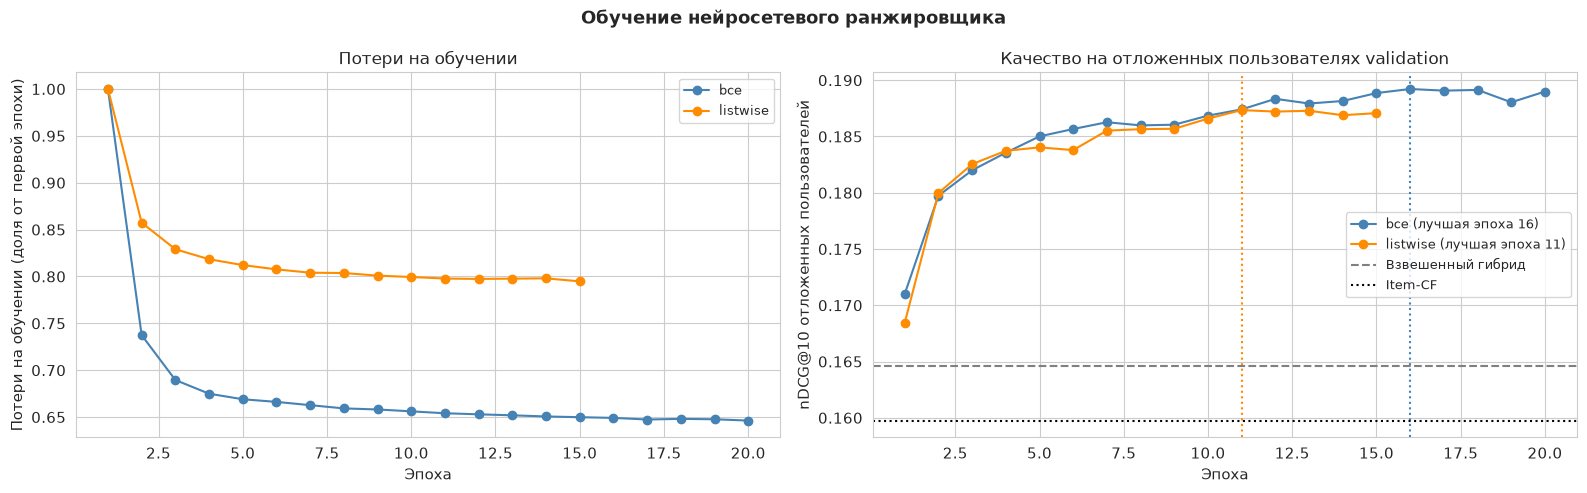

In [39]:
# Кривые обучения: потери и nDCG@10 на отложенных пользователях по эпохам
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
curve_colors = {'bce': 'steelblue', 'listwise': 'darkorange'}
for loss_name, run in ranker_runs.items():
    history = run['history']
    # Потери у двух функций в разных единицах, поэтому показываю их относительно первой эпохи
    axes[0].plot(history['epoch'], history['loss'] / history['loss'].iloc[0], marker='o',
                 color=curve_colors[loss_name], label=loss_name)
    axes[1].plot(history['epoch'], history['holdout_ndcg'], marker='o', color=curve_colors[loss_name],
                 label=f"{loss_name} (лучшая эпоха {run['best_epoch']})")
    axes[1].axvline(run['best_epoch'], color=curve_colors[loss_name], linestyle=':', linewidth=1.5)
axes[1].axhline(holdout_hybrid, color='gray', linestyle='--', linewidth=1.5, label='Взвешенный гибрид')
axes[1].axhline(holdout_item_cf, color='black', linestyle=':', linewidth=1.5, label='Item-CF')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Потери на обучении (доля от первой эпохи)')
axes[0].set_title('Потери на обучении', fontsize=12)
axes[0].legend(fontsize=9)
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('nDCG@10 отложенных пользователей')
axes[1].set_title('Качество на отложенных пользователях validation', fontsize=12)
axes[1].legend(fontsize=9)
plt.suptitle('Обучение нейросетевого ранжировщика', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'ranker_training.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Сеть обучается корректно и уже на validation заметно лучше гибрида

- Обе функции потерь обучаются стабильно: потери на обучении снижаются, а nDCG@10 отложенных пользователей растёт и выходит на плато. Ранняя остановка сработала: для BCE лучшая эпоха 16 из 20, для ListNet - 11 из 15. Эпоха занимает 1.6-2.7 секунды.
- **BCE чуть лучше:** 0.1892 против 0.1873 на отложенных пользователях. Разница небольшая, но выбор делается по validation, поэтому дальше используется сеть с BCE. Списочная функция потерь при этом учится почти вдвое быстрее.
- **Уже на отложенных пользователях validation сеть заметно лучше остальных:** 0.1892 против 0.1646 у взвешенного гибрида и 0.1598 у Item-CF, то есть +18% к Item-CF. Эту оценку стоит считать оптимистичной: на тех же отложенных пользователях выбирались лучшая эпоха и функция потерь, а дальше выбирается lambda и считается важность признаков. Честная оценка - на test (раздел 6.4).

### 6.4 Интеграция в гибрид и сравнение на test

Ранжировщик встаёт на место взвешенного усреднения. Итоговая система:
1. Новый пользователь -> популярные книги.
2. Иначе -> общий пул кандидатов от всех моделей -> скоры нейросетевого ранжировщика -> MMR -> top-N.

Скоры сети устроены иначе, чем взвешенная сумма z-оценок, поэтому lambda для MMR подбираю заново, на тех же отложенных пользователях validation.

In [40]:
# Подбор lambda для MMR поверх ранжировщика (отложенные пользователи validation)
holdout_x = prepare_tensor(ranker_holdout_pool, neural_ranker['feature_indices'],
                           neural_ranker['feature_mean'], neural_ranker['feature_std'])
holdout_neural_scores = predict_ranker_scores(neural_ranker['model'], holdout_x, ranker_holdout_pool['mask'])
neural_lambda_rows = []
for mmr_lambda in [1.0, 0.9, 0.8, 0.7, 0.6]:
    chosen = mmr_rerank(ranker_holdout_pool, holdout_neural_scores, mmr_lambda)
    diversity = diversity_metrics(ranker_holdout_pool, chosen)
    neural_lambda_rows.append({'lambda': mmr_lambda,
                               'nDCG@10': metrics_from_slots(ranker_holdout_pool, chosen)['ndcg'].mean(),
                               'ILD': diversity['ILD'],
                               'доля книг одной серии': diversity['доля книг одной серии']})
neural_lambda_table = pd.DataFrame(neural_lambda_rows).set_index('lambda')
display(neural_lambda_table.round(4))

# Правило выбора: самое маленькое lambda, у которого nDCG@10 ниже максимума не больше чем на 0.0005
# (это меньше погрешности). При той же точности меньшее lambda даёт более разнообразные списки
best_lambda_ndcg = neural_lambda_table['nDCG@10'].max()
NEURAL_MMR_LAMBDA = 1.0
for mmr_lambda in neural_lambda_table.index:
    if neural_lambda_table.loc[mmr_lambda, 'nDCG@10'] >= best_lambda_ndcg - 0.0005:
        NEURAL_MMR_LAMBDA = mmr_lambda    # lambda идут по убыванию, останется самое маленькое подходящее
print(f"Выбрано lambda = {NEURAL_MMR_LAMBDA}")

,nDCG@10,ILD,доля книг одной серии
lambda,,,
1.0,0.1892,0.7549,0.3045
0.9,0.1904,0.7645,0.2844
0.8,0.1906,0.7764,0.2593
0.7,0.1903,0.7912,0.2279
0.6,0.1868,0.8104,0.1880


Выбрано lambda = 0.7


In [41]:
# Итоговое сравнение на test: ранжировщик против гибрида и отдельных моделей
test_x = prepare_tensor(test_pool, neural_ranker['feature_indices'], neural_ranker['feature_mean'],
                        neural_ranker['feature_std'])
test_neural_scores = predict_ranker_scores(neural_ranker['model'], test_x, test_pool['mask'])
test_slots['Нейро-ранжировщик'] = top_k_slots(test_neural_scores)
test_slots['Нейро-ранжировщик + MMR'] = mmr_rerank(test_pool, test_neural_scores, NEURAL_MMR_LAMBDA)

final_methods = ['Content-based', 'Item-CF', 'Item-CF + MMR', 'Гибрид (подобранные веса)', 'Гибрид + MMR',
                 'Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']
final_rows = []
for method_name in final_methods:
    slots = test_slots[method_name]
    row = {'Модель': method_name}
    for k in K_VALUES:
        metrics = metrics_from_slots(test_pool, slots[:, :k])
        row[f'Precision@{k}'] = metrics['precision'].mean()
        row[f'Recall@{k}'] = metrics['recall'].mean()
        row[f'nDCG@{k}'] = metrics['ndcg'].mean()
        if k == 10:
            test_metrics[method_name] = metrics
    diversity = diversity_metrics(diversity_pool, slots[diversity_rows])
    row['ILD'] = diversity['ILD']
    row['доля одной серии'] = diversity['доля книг одной серии']
    recommended_positions = np.take_along_axis(diversity_pool['positions'], slots[diversity_rows], axis=1)
    row['покрытие каталога, %'] = len(np.unique(recommended_positions)) / n_books * 100
    final_rows.append(row)
final_comparison = pd.DataFrame(final_rows).set_index('Модель')
print("Сравнение на test (точность - 34 288 пользователей, разнообразие - 5000):")
display(final_comparison.round(4))

print("Разница nDCG@10 (среднее и 95% доверительный интервал по парам пользователей):")
for method_name in ['Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']:
    for base_name in ['Item-CF', 'Item-CF + MMR', 'Гибрид + MMR']:
        difference = test_metrics[method_name]['ndcg'] - test_metrics[base_name]['ndcg']
        half_width = 1.96 * difference.std() / np.sqrt(len(difference))
        relative = difference.mean() / test_metrics[base_name]['ndcg'].mean() * 100
        print(f"  {method_name:<26} к {base_name:<14} {difference.mean():+.4f} +- {half_width:.4f} ({relative:+.1f}%)")
print()

# По сегментам пользователей
neural_segment_rows = []
for segment_name in USER_SEGMENT_NAMES[1:]:
    segment_mask = test_pool_segments == segment_name
    row = {'Сегмент': segment_name}
    for method_name in ['Item-CF', 'Гибрид + MMR', 'Нейро-ранжировщик + MMR']:
        row[method_name] = test_metrics[method_name]['ndcg'][segment_mask].mean()
    row['Нейро + MMR к Item-CF, %'] = (row['Нейро-ранжировщик + MMR'] - row['Item-CF']) / row['Item-CF'] * 100
    neural_segment_rows.append(row)
neural_segment_table = pd.DataFrame(neural_segment_rows).set_index('Сегмент')
print("nDCG@10 по сегментам:")
display(neural_segment_table.round(4))

Сравнение на test (точность - 34 288 пользователей, разнообразие - 5000):


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,ILD,доля одной серии,"покрытие каталога, %"
Модель,,,,,,,,,
Content-based,0.0781,0.1262,0.1312,0.0559,0.1691,0.1413,0.6263,0.2827,75.73
Item-CF,0.1187,0.1926,0.2039,0.0817,0.2502,0.2154,0.7370,0.3086,83.07
Item-CF + MMR,0.1216,0.1975,0.2076,0.0834,0.2544,0.2188,0.7822,0.2193,84.95
Гибрид (подобранные веса),0.1203,0.1946,0.2064,0.0826,0.2524,0.2177,0.7133,0.3161,83.08
Гибрид + MMR,0.1250,0.2021,0.2123,0.0856,0.2602,0.2236,0.7776,0.1933,85.30
Нейро-ранжировщик,0.1345,0.2168,0.2282,0.0937,0.2829,0.2423,0.7542,0.3031,81.96
Нейро-ранжировщик + MMR,0.1370,0.2218,0.2314,0.0956,0.2872,0.2455,0.7910,0.2255,83.00


Разница nDCG@10 (среднее и 95% доверительный интервал по парам пользователей):
  Нейро-ранжировщик          к Item-CF        +0.0269 +- 0.0015 (+12.5%)
  Нейро-ранжировщик          к Item-CF + MMR  +0.0235 +- 0.0014 (+10.8%)
  Нейро-ранжировщик          к Гибрид + MMR   +0.0187 +- 0.0013 (+8.3%)
  Нейро-ранжировщик + MMR    к Item-CF        +0.0302 +- 0.0015 (+14.0%)
  Нейро-ранжировщик + MMR    к Item-CF + MMR  +0.0267 +- 0.0015 (+12.2%)
  Нейро-ранжировщик + MMR    к Гибрид + MMR   +0.0219 +- 0.0014 (+9.8%)

nDCG@10 по сегментам:


,Item-CF,Гибрид + MMR,Нейро-ранжировщик + MMR,"Нейро + MMR к Item-CF, %"
Сегмент,,,,
Короткая история (1-4),0.1929,0.1940,0.2108,9.2727
Средняя (5-19),0.2175,0.2248,0.2447,12.5178
Активный (20+),0.2285,0.2432,0.2710,18.5885


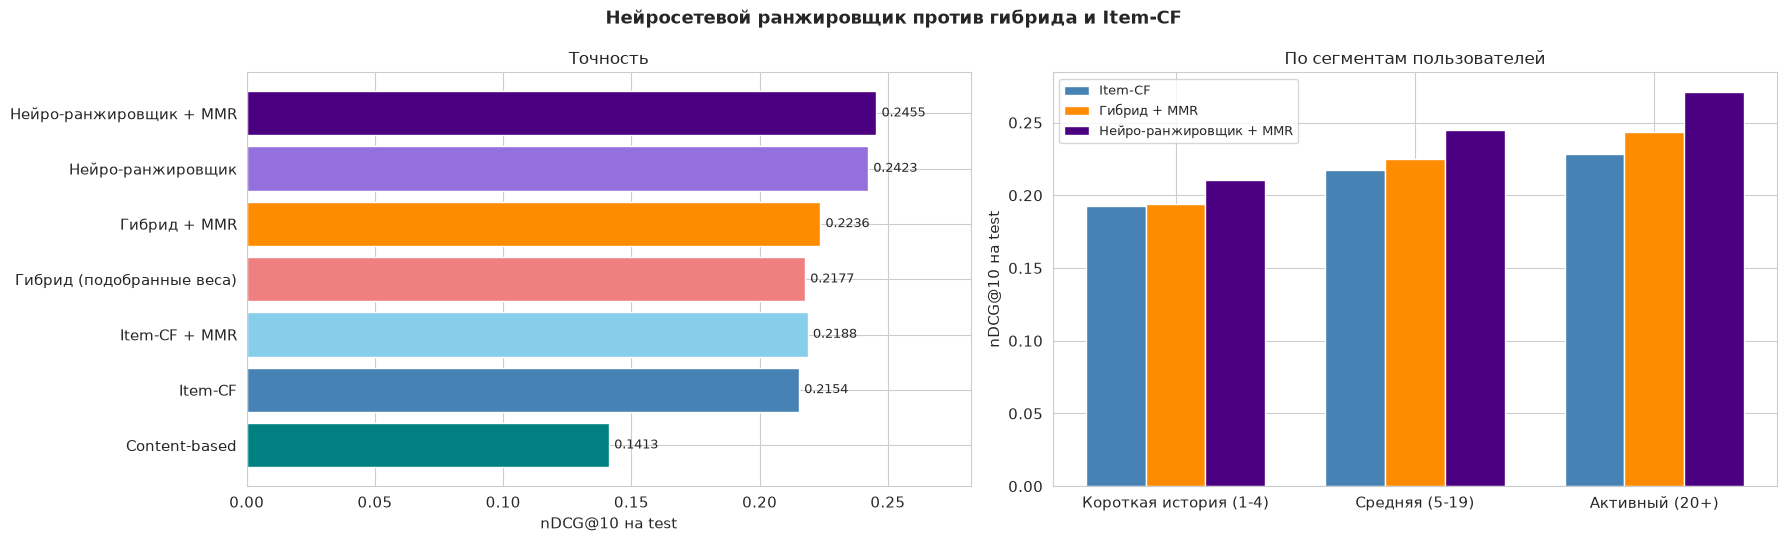

In [42]:
# График: точность на test и выигрыш по сегментам
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
method_colors = ['teal', 'steelblue', 'skyblue', 'lightcoral', 'darkorange', 'mediumpurple', 'indigo']
ndcg_values = final_comparison['nDCG@10'].values
axes[0].barh(range(len(final_methods)), ndcg_values, color=method_colors, edgecolor='white')
for i in range(len(final_methods)):
    axes[0].text(ndcg_values[i] + 0.002, i, f'{ndcg_values[i]:.4f}', va='center', fontsize=9)
axes[0].set_yticks(range(len(final_methods)))
axes[0].set_yticklabels(final_methods)
axes[0].set_xlim(0, ndcg_values.max() * 1.15)
axes[0].set_xlabel('nDCG@10 на test')
axes[0].set_title('Точность', fontsize=12)

segment_positions = np.arange(len(neural_segment_table))
bar_width = 0.25
segment_plot_methods = ['Item-CF', 'Гибрид + MMR', 'Нейро-ранжировщик + MMR']
segment_plot_colors = ['steelblue', 'darkorange', 'indigo']
for method_index, method_name in enumerate(segment_plot_methods):
    offsets = segment_positions + (method_index - 1) * bar_width
    axes[1].bar(offsets, neural_segment_table[method_name].values, width=bar_width,
                color=segment_plot_colors[method_index], edgecolor='white', label=method_name)
axes[1].set_xticks(segment_positions)
axes[1].set_xticklabels(neural_segment_table.index)
axes[1].set_ylabel('nDCG@10 на test')
axes[1].set_title('По сегментам пользователей', fontsize=12)
axes[1].legend(fontsize=9)

plt.suptitle('Нейросетевой ранжировщик против гибрида и Item-CF', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'ranker_test_comparison.png'), dpi=100, bbox_inches='tight')
plt.show()

In [43]:
# Почему у ранжировщика другое покрытие каталога: какие книги попадают в top-10 разных методов.
# Считаю на тех же 5000 пользователях, на которых считались разнообразие и покрытие
goodreads_ratings_count = books.sort_values('id')['ratings_count'].values
recommended_rows = []
for method_name in ['Item-CF', 'Item-CF + MMR', 'Гибрид + MMR', 'Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']:
    positions = np.take_along_axis(diversity_pool['positions'], test_slots[method_name][diversity_rows], axis=1).flatten()
    book_counts = np.bincount(positions, minlength=n_books)
    most_frequent = np.sort(book_counts)[::-1]
    recommended_rows.append({
        'Модель': method_name,
        'медиана оценок на Goodreads': np.median(goodreads_ratings_count[positions]),
        'среднее оценок в train': book_features_full['book_n_ratings'].values[positions].mean(),
        'книги со 100 оценками, %': (total_book_ratings[positions] == 100).mean() * 100,
        'разных книг': (book_counts > 0).sum(),
        'доля 100 самых частых книг, %': most_frequent[:100].sum() / len(positions) * 100,
    })
print("Книги в top-10 (5000 пользователей test):")
display(pd.DataFrame(recommended_rows).set_index('Модель').round(2))


Книги в top-10 (5000 пользователей test):


,медиана оценок на Goodreads,среднее оценок в train,"книги со 100 оценками, %",разных книг,"доля 100 самых частых книг, %"
Модель,,,,,
Item-CF,20962.0,78.74,62.11,8307,5.50
Item-CF + MMR,20453.0,78.68,61.50,8495,5.47
Гибрид + MMR,20948.0,78.67,61.27,8530,5.67
Нейро-ранжировщик,16742.5,77.70,53.21,8196,4.99
Нейро-ранжировщик + MMR,16384.0,77.56,51.94,8300,5.09


#### Нейросетевой ранжировщик - лучший вариант системы

- **Ранжировщик + MMR - лучший вариант по всем метрикам точности:** nDCG@10 = 0.2455 против 0.2154 у Item-CF (+0.0302 +- 0.0015, +14.0%), 0.2188 у Item-CF + MMR (+12.2%) и 0.2236 у гибрида + MMR (+9.8%). Precision@10 - 0.0956 против 0.0817, Recall@10 - 0.287 против 0.250: в top-10 попадает почти 29% понравившихся пользователю книг из test.
- Без MMR сеть даёт 0.2423 (+12.5%). MMR добавляет ещё немного точности и разнообразия: ILD 0.754 -> 0.791, доля книг одной серии 0.30 -> 0.23. Для сети на отложенных пользователях выбрано lambda = 0.7, как у Item-CF: при 0.6 точность уже падает (0.1868 против 0.1906 у лучшего lambda).
- **Выигрыш есть во всех сегментах и растёт с активностью:** +9.3% при 1-4 оценках, +12.5% при 5-19, +18.6% у активных. В отличие от взвешенного гибрида, сеть заметно помогает и пользователям с короткой историей (0.211 против 0.193).
- **Покрытие каталога на уровне Item-CF:** 83.0% против 83.1%. Гибрид + MMR и Item-CF + MMR покрывают чуть больше (85.3% и 85.0%): MMR со штрафом за похожие книги освобождает места для других книг.
- **Какие книги поднимает сеть** (таблица выше): менее популярные на Goodreads, чем Item-CF. Медиана числа оценок на Goodreads у книг из её top-10 - около 16 тысяч против 21 тысячи у Item-CF, а доля 100 самых частых книг в рекомендациях даже чуть ниже (5.1% против 5.5%). То есть сеть не сужает рекомендации до популярных книг, а скорее ослабляет известный сдвиг Item-CF к популярным книгам.

Итоговая функция рекомендаций для одного пользователя: та же схема, что в разделе 4.5, только на втором этапе вместо взвешенного усреднения - ранжировщик.

In [44]:
# Итоговые рекомендации: пул кандидатов -> нейросетевой ранжировщик -> MMR
def recommend_neural_hybrid(user_id, models, user_features, book_features, ranker, mmr_lambda, n=10):
    rated_positions = models['user_item'][user_id - 1].indices
    if len(rated_positions) == 0:
        book_ids = top_n_books(models['popularity_score'], rated_positions, n)
        result = pd.DataFrame({'book_id': book_ids, 'источник': 'Popularity (новый пользователь)'})
        result['title'] = book_info.loc[result['book_id'], 'title'].values
        return result[['book_id', 'title', 'источник']]

    user_pool = build_candidate_pool(models, user_features, book_features, [user_id], verbose=False)
    user_x = prepare_tensor(user_pool, ranker['feature_indices'], ranker['feature_mean'], ranker['feature_std'])
    user_scores = predict_ranker_scores(ranker['model'], user_x, user_pool['mask'])
    chosen_slots = mmr_rerank(user_pool, user_scores, mmr_lambda, n)[0]
    chosen_slots = chosen_slots[user_pool['mask'][0, chosen_slots]]

    book_ids = []
    sources = []
    for slot in chosen_slots:
        book_ids.append(int(user_pool['positions'][0, slot]) + 1)
        source_names = []
        for model_index, model_name in enumerate(POOL_MODEL_NAMES):
            if user_pool['sources'][0, slot, model_index]:
                source_names.append(model_name)
        sources.append(', '.join(source_names))
    result = pd.DataFrame({'book_id': book_ids, 'источник': sources})
    result['title'] = book_info.loc[result['book_id'], 'title'].values
    return result[['book_id', 'title', 'источник']]


demo_recommendations = recommend_neural_hybrid(demo_user_id, models_full, user_features_full, book_features_full,
                                               neural_ranker, NEURAL_MMR_LAMBDA)
demo_test_books = set(test[(test['user_id'] == demo_user_id) & (test['rating'] >= RELEVANCE_THRESHOLD)]['book_id'])
demo_recommendations['понравилась в test'] = demo_recommendations['book_id'].isin(demo_test_books)
print(f"Пользователь {demo_user_id}:")
display(demo_recommendations)

Пользователь 21150:


,book_id,title,источник,понравилась в test
0,1163,The Miserable Mill (A Series of Unfortunate Ev...,"Item-CF, Content-based, PureSVD",True
1,5151,"The Ironwood Tree (The Spiderwick Chronicles, #4)",Content-based,False
2,519,"Pretties (Uglies, #2)","Item-CF, PureSVD",False
3,976,"Dr. Seuss's Green Eggs and Ham: For Soprano, B...",Item-CF,False
4,8626,Lemony Snicket: The Unauthorized Autobiography...,"Item-CF, Content-based, PureSVD",False
5,1290,"Messenger (The Giver, #3)",Item-CF,False
6,1662,Fantastic Mr. Fox,"Item-CF, Content-based, PureSVD",False
7,356,The Bad Beginning (A Series of Unfortunate Eve...,"Item-CF, Content-based, PureSVD",False
8,1020,The Tale of Despereaux,"Item-CF, PureSVD",True
9,9461,A Series of Unfortunate Events Box: The Comple...,Content-based,False


Для демо-пользователя ранжировщик собрал другой список, чем взвешенный гибрид в разделе 4.5. Кроме его серии, здесь соседние детские серии (Spiderwick, Uglies, The Giver), и часть книг пришла только от Content-based: сеть доверяет контентной схожести больше, чем общие веса гибрида. Из его test в списке две книги (The Miserable Mill и The Tale of Despereaux), у взвешенного гибрида их было три. На одном пользователе картина может быть любой: ранжировщик выигрывает в среднем по 34 288 пользователям, а не на каждом.

### 6.5 Улучшают ли расширенные признаки качество и нужна ли здесь нейросеть

Критерий задания требует, чтобы признаки были осмысленными и **улучшали качество**, а продвинутая часть - сравнить нейросеть с классическими методами. Проверяю это тремя способами:
1. **Сеть только на 5 z-оценках моделей**, то есть на том, что видит взвешенное усреднение. Разница с полной сетью - вклад признаков раздела 3.
2. **Логистическая регрессия на тех же 26 признаках:** тот же цикл обучения и та же функция потерь, но вместо MLP один линейный слой. Это классический обучаемый ранжировщик. Его разница с взвешенным гибридом - вклад признаков, а разница MLP с ним - вклад самой нейросети.
3. **Важность признаков (permutation importance)** на отложенных пользователях validation. Значения признака перемешиваются, и смотрим, насколько упадёт nDCG@10. Признаки книги и взаимодействия перемешиваются между всеми кандидатами. Признаки пользователя одинаковы у всех его книг, поэтому их переставляю между пользователями: пользователь целиком получает признаки другого пользователя. Так же проверяю целые группы признаков.

In [45]:
# 1. Сеть только на 5 z-оценках моделей (без признаков раздела 3)
Z_FEATURE_INDICES = []
for z_column in Z_COLUMNS.values():
    Z_FEATURE_INDICES.append(POOL_FEATURE_COLUMNS.index(z_column))

start_time = time.perf_counter()
z_only_ranker = train_neural_ranker(ranker_train_pool, ranker_holdout_pool, Z_FEATURE_INDICES, best_loss_name, verbose=False)
z_only_x = prepare_tensor(test_pool, Z_FEATURE_INDICES, z_only_ranker['feature_mean'], z_only_ranker['feature_std'])
z_only_ndcg = metrics_from_slots(test_pool, top_k_slots(
    predict_ranker_scores(z_only_ranker['model'], z_only_x, test_pool['mask'])))['ndcg']
print(f"Время обучения: {time.perf_counter() - start_time:.0f} с")
print()
print(f"{'Вариант':<45} {'nDCG@10 отложенных':>19} {'nDCG@10 test':>13}")
print('-' * 79)
print(f"{'Взвешенный гибрид (5 z-оценок, общие веса)':<45} {holdout_hybrid:>19.4f} "
      f"{test_metrics['Гибрид (подобранные веса)']['ndcg'].mean():>13.4f}")
print(f"{'Сеть на 5 z-оценках':<45} {z_only_ranker['best_holdout_ndcg']:>19.4f} {z_only_ndcg.mean():>13.4f}")
print(f"{'Сеть на всех признаках ранжировщика':<45} {neural_ranker['best_holdout_ndcg']:>19.4f} "
      f"{test_metrics['Нейро-ранжировщик']['ndcg'].mean():>13.4f}")
feature_gain = test_metrics['Нейро-ранжировщик']['ndcg'] - z_only_ndcg
print()
print(f"Вклад признаков раздела 3 на test: {feature_gain.mean():+.4f} +- {1.96 * feature_gain.std() / np.sqrt(len(feature_gain)):.4f} "
      f"({feature_gain.mean() / z_only_ndcg.mean() * 100:+.1f}%)")

Время обучения: 17 с

Вариант                                        nDCG@10 отложенных  nDCG@10 test
-------------------------------------------------------------------------------
Взвешенный гибрид (5 z-оценок, общие веса)                 0.1646        0.2177
Сеть на 5 z-оценках                                        0.1599        0.2090
Сеть на всех признаках ранжировщика                        0.1892        0.2423

Вклад признаков раздела 3 на test: +0.0333 +- 0.0015 (+15.9%)


In [46]:
# 2. Классический обучаемый ранжировщик на тех же признаках: логистическая регрессия.
# Тот же цикл обучения, та же функция потерь, те же признаки и те же пользователи, только вместо MLP
# один линейный слой. Разница MLP и линейной модели - вклад именно нейросети, то есть нелинейности
class LinearRanker(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layer = nn.Linear(n_features, 1)

    def forward(self, features):
        return self.layer(features).squeeze(-1)


start_time = time.perf_counter()
linear_ranker = train_neural_ranker(ranker_train_pool, ranker_holdout_pool, RANKER_FEATURE_INDICES, best_loss_name,
                                    verbose=False, model_class=LinearRanker)
linear_x = prepare_tensor(test_pool, RANKER_FEATURE_INDICES, linear_ranker['feature_mean'], linear_ranker['feature_std'])
linear_ndcg = metrics_from_slots(test_pool, top_k_slots(
    predict_ranker_scores(linear_ranker['model'], linear_x, test_pool['mask'])))['ndcg']
print(f"Время обучения: {time.perf_counter() - start_time:.0f} с, лучшая эпоха {linear_ranker['best_epoch']}")
print()


def difference_with_interval(new_values, base_values):
    # Средняя разница по парам пользователей, 95% доверительный интервал и разница в процентах
    difference = new_values - base_values
    half_width = 1.96 * difference.std() / np.sqrt(len(difference))
    return f"{difference.mean():+.4f} +- {half_width:.4f} ({difference.mean() / base_values.mean() * 100:+.1f}%)"


hybrid_ndcg = test_metrics['Гибрид (подобранные веса)']['ndcg']
mlp_ndcg = test_metrics['Нейро-ранжировщик']['ndcg']
print(f"{'Ранжирование пула (без MMR)':<46} {'nDCG@10 отложенных':>19} {'nDCG@10 test':>13}")
print('-' * 80)
print(f"{'Взвешенный гибрид (5 z-оценок, общие веса)':<46} {holdout_hybrid:>19.4f} {hybrid_ndcg.mean():>13.4f}")
print(f"{'Логистическая регрессия на тех же признаках':<46} {linear_ranker['best_holdout_ndcg']:>19.4f} "
      f"{linear_ndcg.mean():>13.4f}")
print(f"{'MLP (нейросетевой ранжировщик)':<46} {neural_ranker['best_holdout_ndcg']:>19.4f} {mlp_ndcg.mean():>13.4f}")
print()
print("Разница nDCG@10 на test (среднее и 95% доверительный интервал по парам пользователей):")
print(f"  признаки: логистическая регрессия к взвешенному гибриду  {difference_with_interval(linear_ndcg, hybrid_ndcg)}")
print(f"  нейросеть: MLP к логистической регрессии                {difference_with_interval(mlp_ndcg, linear_ndcg)}")
print(f"  всего: MLP к взвешенному гибриду                        {difference_with_interval(mlp_ndcg, hybrid_ndcg)}")


Время обучения: 8 с, лучшая эпоха 11

Ранжирование пула (без MMR)                     nDCG@10 отложенных  nDCG@10 test
--------------------------------------------------------------------------------
Взвешенный гибрид (5 z-оценок, общие веса)                  0.1646        0.2177
Логистическая регрессия на тех же признаках                 0.1797        0.2327
MLP (нейросетевой ранжировщик)                              0.1892        0.2423

Разница nDCG@10 на test (среднее и 95% доверительный интервал по парам пользователей):
  признаки: логистическая регрессия к взвешенному гибриду  +0.0150 +- 0.0013 (+6.9%)
  нейросеть: MLP к логистической регрессии                +0.0096 +- 0.0009 (+4.1%)
  всего: MLP к взвешенному гибриду                        +0.0246 +- 0.0014 (+11.3%)


nDCG@10 отложенных без перемешивания: 0.1892


,признак,группа,падение nDCG@10
0,z_item_cf,z-оценка модели,0.0398
1,item_cf_max_similarity,взаимодействие,0.0224
2,book_log_goodreads_ratings,книга,0.0197
3,z_pure_svd,z-оценка модели,0.0161
4,item_cf_score,взаимодействие,0.0140
5,content_score,взаимодействие,0.0086
6,item_cf_similarity_sum,взаимодействие,0.0081
7,same_series_in_history,взаимодействие,0.0062
8,z_svd,z-оценка модели,0.0045
9,user_log_n_ratings,пользователь,0.0037


,признаков,падение nDCG@10
группа,,
пользователь,4,0.0034
книга,6,0.0247
взаимодействие,11,0.1237
z-оценка модели,5,0.0469


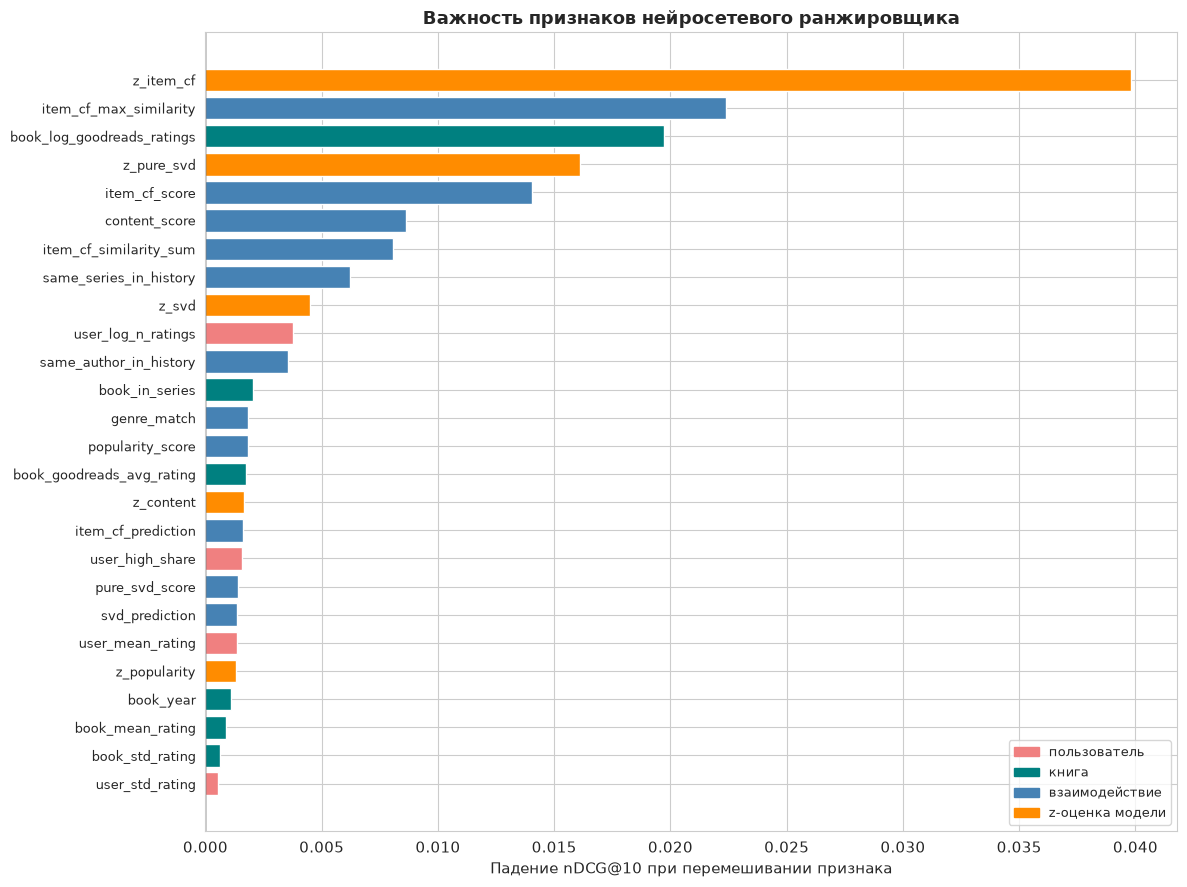

In [47]:
# 3. Важность признаков: падение nDCG@10 отложенных пользователей при перемешивании признака
importance_rng = np.random.default_rng(RANDOM_STATE)
holdout_x_numpy = holdout_x.numpy()
holdout_mask = ranker_holdout_pool['mask']
base_ndcg = metrics_from_slots(ranker_holdout_pool, top_k_slots(
    predict_ranker_scores(neural_ranker['model'], holdout_x, holdout_mask)))['ndcg'].mean()

# Столбцы тензора идут в порядке признаков ранжировщика (без book_n_ratings)
ranker_feature_names = []
for feature_index in neural_ranker['feature_indices']:
    ranker_feature_names.append(POOL_FEATURE_COLUMNS[feature_index])


def permutation_drop(column_indices):
    # Признаки книги, взаимодействия и z-оценки перемешиваю между всеми кандидатами отложенных пользователей.
    # Признаки пользователя одинаковы у всех его книг, поэтому их переставляю между пользователями:
    # пользователь целиком получает признаки другого пользователя. Если перемешать их между кандидатами,
    # внутри одного пользователя появятся разные значения, которых сеть никогда не видела, и падение
    # покажет реакцию на шум, а не потерю информации о пользователе
    shuffled = holdout_x_numpy.copy()
    filled_rows, filled_slots = np.where(holdout_mask)
    shuffled_order = importance_rng.permutation(len(filled_rows))
    user_order = importance_rng.permutation(shuffled.shape[0])
    for column in column_indices:
        if ranker_feature_names[column] in USER_FEATURE_COLUMNS:
            # Первое место пула заполнено у всех пользователей, значение признака беру оттуда
            user_values = holdout_x_numpy[:, 0, column][user_order]
            shuffled[:, :, column] = user_values.reshape(-1, 1)
            shuffled[~holdout_mask, column] = 0
        else:
            values = shuffled[filled_rows, filled_slots, column]
            shuffled[filled_rows, filled_slots, column] = values[shuffled_order]
    scores = predict_ranker_scores(neural_ranker['model'], torch.tensor(shuffled), holdout_mask)
    return base_ndcg - metrics_from_slots(ranker_holdout_pool, top_k_slots(scores))['ndcg'].mean()


# Группа каждого признака
feature_groups = {}
for column_name in POOL_FEATURE_COLUMNS:
    if column_name in USER_FEATURE_COLUMNS:
        feature_groups[column_name] = 'пользователь'
    elif column_name in BOOK_FEATURE_COLUMNS:
        feature_groups[column_name] = 'книга'
    elif column_name in INTERACTION_FEATURE_COLUMNS:
        feature_groups[column_name] = 'взаимодействие'
    else:
        feature_groups[column_name] = 'z-оценка модели'

importance_rows = []
for column_index, column_name in enumerate(ranker_feature_names):
    importance_rows.append({'признак': column_name, 'группа': feature_groups[column_name],
                            'падение nDCG@10': permutation_drop([column_index])})
feature_importance = pd.DataFrame(importance_rows).sort_values('падение nDCG@10', ascending=False).reset_index(drop=True)
print(f"nDCG@10 отложенных без перемешивания: {base_ndcg:.4f}")
display(feature_importance.head(12).round(4))

# Важность целых групп признаков
group_rows = []
for group_name in ['пользователь', 'книга', 'взаимодействие', 'z-оценка модели']:
    group_columns = []
    for column_index, column_name in enumerate(ranker_feature_names):
        if feature_groups[column_name] == group_name:
            group_columns.append(column_index)
    group_rows.append({'группа': group_name, 'признаков': len(group_columns),
                       'падение nDCG@10': permutation_drop(group_columns)})
group_importance = pd.DataFrame(group_rows).set_index('группа')
display(group_importance.round(4))

# График важности признаков
plot_importance = feature_importance.sort_values('падение nDCG@10')
group_colors = {'пользователь': 'lightcoral', 'книга': 'teal', 'взаимодействие': 'steelblue', 'z-оценка модели': 'darkorange'}
bar_colors = []
for group_name in plot_importance['группа']:
    bar_colors.append(group_colors[group_name])
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(range(len(plot_importance)), plot_importance['падение nDCG@10'], color=bar_colors, edgecolor='white')
ax.set_yticks(range(len(plot_importance)))
ax.set_yticklabels(plot_importance['признак'], fontsize=9)
from matplotlib.patches import Patch    # нужен только для легенды этого графика
legend_handles = []
for group_name, color in group_colors.items():
    legend_handles.append(Patch(color=color, label=group_name))
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Падение nDCG@10 при перемешивании признака')
ax.set_title('Важность признаков нейросетевого ранжировщика', fontsize=13, fontweight='bold')
ax.legend(handles=legend_handles, fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'ranker_feature_importance.png'), dpi=100, bbox_inches='tight')
plt.show()


#### Расширенные признаки улучшают качество, а нейросеть добавляет к ним ещё треть выигрыша

- **Признаки раздела 3 дают +15.9%:** сеть на 26 признаках - 0.2423 на test, та же сеть только на 5 z-оценках моделей - 0.2090 (разница +0.0333 +- 0.0015). Это прямое доказательство, что расширенные признаки улучшают качество.
- Сеть только на z-оценках хуже взвешенного гибрида (0.2090 против 0.2177). Веса гибрида подбирались прямо по nDCG@10, а сеть с поточечной функцией потерь учится угадывать отдельные понравившиеся книги и без контекста пользователя не знает, какие значения z-оценок для него высокие. Поэтому вклад признаков честнее считать от взвешенного гибрида.
- **Нейросеть оправдана.** Логистическая регрессия на тех же признаках даёт 0.2327, то есть +6.9% к взвешенному гибриду (+0.0150 +- 0.0013). MLP лучше логистической регрессии ещё на +4.1% (+0.0096 +- 0.0009). Путь от гибрида к сети (+11.3%) раскладывается так: около 60% выигрыша дают признаки (ими может пользоваться и линейная модель), около 40% - нелинейность. Сеть может учитывать сочетания признаков, например доверять скору Item-CF по-разному в зависимости от длины истории, а линейная модель так не умеет.
- **Самые важные признаки:** z-оценка Item-CF (падение 0.040), максимальная схожесть с историей (0.022) и число оценок книги на Goodreads (0.020), дальше PureSVD (0.016) и скор Item-CF (0.014). Сигнал "что читают одни и те же люди" остаётся главным.
- Число оценок на Goodreads по отдельности почти бесполезно (AUC 0.52 внутри пользователя в разделе 3.4), но вместе со схожестью работает. Направление его влияния видно в разделе 6.4: сеть рекомендует менее популярные на Goodreads книги, чем Item-CF.
- **Признаки пользователя** при перестановке между пользователями дают небольшой, но не нулевой вклад: активность пользователя - 0.0037, вся группа - 0.0034. Сеть действительно использует их как контекст, как и ожидалось в разделе 3.4, но эффект скромный.
- **По группам:** если перемешать признаки взаимодействия, nDCG@10 падает с 0.189 до 0.066, то есть почти втрое. Без z-оценок падение 0.047, без признаков книги - 0.025, без признаков пользователя - 0.003. Основа - схожесть с историей.

## 7. Сквозной пайплайн

По заданию нужен единый процесс от данных до рекомендаций: загрузка данных -> предобработка -> обучение моделей -> генерация рекомендаций -> оценка качества, который можно запустить заново на новых данных. В разделах 1-6 эти шаги разнесены по ячейкам, здесь они собраны в одну функцию `run_pipeline`. Каждый этап вызывает уже проверенные функции разделов 1-6, нового алгоритма в пайплайне нет.

| Этап | Что делает | Функции из разделов 1-6 |
|---|---|---|
| 1. Загрузка | Читает и чистит файлы датасета, проверяет, что каталог книг тот же | `load_and_clean_data`, `build_static_book_features` |
| 2. Предобработка | Разбиение на train, validation и test, признаки пользователей и книг | `split_data`, `get_eval_users`, `build_user_features`, `build_book_features` |
| 3. Обучение | Пять базовых моделей на `train_fit` и `train_full`, пул кандидатов validation, нейросетевой ранжировщик | `fit_base_models`, `build_candidate_pool`, `train_neural_ranker` |
| 4. Рекомендации | Top-10 итоговой системы (пул -> ранжировщик -> MMR) для пользователей test. Для сравнения на тех же пулах - списки Item-CF и взвешенного гибрида + MMR | `build_candidate_pool`, `predict_ranker_scores`, `mmr_rerank` |
| 5. Оценка | Precision, Recall и nDCG@10, разнообразие ILD, покрытие каталога | `metrics_from_slots`, `diversity_metrics` |
| 6. Сохранение | Если задана папка `output_dir`: таблица рекомендаций, метрики и веса ранжировщика | `to_csv`, `torch.save` |

Решения:
- **Настройки берутся из разделов 5-6** (веса гибрида, lambda для MMR, функция потерь) и лежат в словаре `PIPELINE_CONFIG`. При новых данных модели и ранжировщик обучаются заново, а перебор настроек не повторяется: он долгий, и в рабочей системе модели обычно переобучают чаще, чем пересматривают настройки.
- **Пользователей меньше, чем в разделах 4-6:** для ранжировщика берётся 8 000 пользователей validation (6 400 для обучения и 1 600 отложенных для ранней остановки), качество оценивается на 5 000 пользователях test. Так один прогон занимает около 3.5 минуты вместо получаса. Размеры можно поменять в настройках.
- **Что считается новыми данными:** новые оценки по тому же каталогу книг, в том числе от новых пользователей с новыми id. Строка матрицы пользователя - это `user_id - 1`, а число строк пайплайн берёт из самих данных (проверка в разделе 7.4). Оценки можно передать и таблицей (`ratings_df`), например выгрузкой из базы данных. TF-IDF и жанровые профили книг построены в разделах 2-3, поэтому пайплайн проверяет, что каталог тот же, и иначе останавливается с понятной ошибкой. Если изменился сам каталог, ноутбук нужно запустить целиком с новой папкой `DATA_DIR`: все его разделы строятся по загруженным файлам.
- **Результат пайплайна** - словарь: обученные модели и ранжировщик, таблица рекомендаций "пользователь - место - книга", метрики и время этапов. Функция `pipeline_recommend(result, user_id)` выдаёт рекомендации одному пользователю по моделям из этого словаря, а пользователю, которого не было в данных запуска, - популярные книги.
- **Ограничение:** пайплайн - это функция ноутбука. Он вызывает функции разделов 1-6 и использует построенные там TF-IDF и жанровые профили книг (`tfidf_matrix`, `book_genre_vectors`), поэтому работает в том же ядре после выполнения разделов 1-6. Чтобы запускать его отдельным скриптом или сервисом, эти функции нужно вынести в модуль `.py`. В проекте я этого не делал, чтобы весь код оставался в одном ноутбуке и его было удобно проверять.

### 7.1 Функция пайплайна

In [48]:
# Сквозной пайплайн: загрузка -> предобработка -> обучение -> рекомендации -> оценка
# Каждый этап вызывает функции разделов 1-6. Гиперпараметры найдены в разделах 5-6 и не перебираются заново:
# на новых данных переобучаются модели и ранжировщик, а настройки остаются теми же
PIPELINE_CONFIG = {
    'hybrid_weights': best_weights,            # веса взвешенного гибрида (раздел 5.1), для сравнения
    'hybrid_mmr_lambda': MMR_LAMBDA,           # lambda MMR гибрида (раздел 5.2)
    'loss_name': best_loss_name,               # функция потерь ранжировщика (раздел 6.3)
    'neural_mmr_lambda': NEURAL_MMR_LAMBDA,    # lambda MMR ранжировщика (раздел 6.4)
    'ranker_users': 8000,                      # пользователей validation для обучения ранжировщика
    'holdout_share': 0.2,                      # из них доля отложенных для ранней остановки
    'eval_users': 5000,                        # пользователей test для оценки качества
    'top_n': 10,                               # длина списка рекомендаций
}
PIPELINE_OUTPUT_DIR = 'pipeline_output'       # куда пайплайн сохраняет результаты (раздел 7.2)


def run_pipeline(data_dir, config, user_ids=None, verbose=True, ratings_df=None, output_dir=None):
    # ratings_df - новые оценки таблицей (например, выгрузка из базы данных) вместо ratings.csv из data_dir.
    # output_dir - папка, куда сохранить рекомендации, метрики и веса ранжировщика
    timings = {}
    top_n = config['top_n']

    # 1. Загрузка данных и проверка каталога
    start_time = time.perf_counter()
    ratings_p, books_p, book_tags_p = load_and_clean_data(data_dir, verbose=False)
    if ratings_df is not None:
        # Повторы пары (пользователь, книга) убираю так же, как в load_and_clean_data
        ratings_p = ratings_df.drop_duplicates(subset=['user_id', 'book_id'], keep='first').reset_index(drop=True)
    if user_ids is not None:
        # Только оценки заданных пользователей: так моделирую выгрузку, в которой ещё нет части пользователей
        ratings_p = ratings_p[ratings_p['user_id'].isin(user_ids)].reset_index(drop=True)
    static_features_p, genre_vectors_p = build_static_book_features(books_p, book_tags_p)
    # TF-IDF книг (Content-based и MMR) и жанровые профили посчитаны в разделах 2-3 для каталога ноутбука.
    # Пайплайн принимает новые оценки по тому же каталогу, иначе нужно перезапустить ноутбук целиком
    same_catalog = len(books_p) == n_books and np.allclose(genre_vectors_p, book_genre_vectors)
    if not same_catalog:
        raise ValueError("Каталог книг отличается от данных ноутбука. "
                         "Нужно перезапустить ноутбук целиком с новой папкой DATA_DIR")
    # Строка матрицы пользователя = user_id - 1. Новые пользователи с номерами больше, чем в ноутбуке,
    # просто добавляют строки, поэтому число строк берётся из самих данных
    n_users_p = int(ratings_p['user_id'].max())
    timings['1. Загрузка'] = time.perf_counter() - start_time
    if verbose:
        print(f"[1/5] Загрузка: {len(ratings_p)} оценок, {ratings_p['user_id'].nunique()} пользователей "
              f"(наибольший id {n_users_p}), "
              f"{ratings_p['book_id'].nunique()} книг, каталог совпадает с ноутбуком "
              f"({timings['1. Загрузка']:.0f} с)")

    # 2. Предобработка: разбиение, пользователи для оценки, признаки пользователей и книг
    start_time = time.perf_counter()
    train_full_p, test_p, train_fit_p, valid_p = split_data(ratings_p, verbose=False)
    valid_relevant_p, valid_user_ids_p = get_eval_users(train_fit_p, valid_p)
    test_relevant_p, test_user_ids_p = get_eval_users(train_full_p, test_p)
    user_features_fit_p = build_user_features(train_fit_p, n_users_p)
    user_features_full_p = build_user_features(train_full_p, n_users_p)
    book_features_fit_p = build_book_features(train_fit_p, static_features_p)
    book_features_full_p = build_book_features(train_full_p, static_features_p)
    timings['2. Предобработка'] = time.perf_counter() - start_time
    if verbose:
        print(f"[2/5] Предобработка: train_fit {len(train_fit_p)}, valid {len(valid_p)}, test {len(test_p)} оценок. "
              f"Пользователей для оценки: valid {len(valid_user_ids_p)}, test {len(test_user_ids_p)} "
              f"({timings['2. Предобработка']:.0f} с)")

    # 3. Обучение: базовые модели на train_fit (для ранжировщика) и train_full (для рекомендаций), ранжировщик
    start_time = time.perf_counter()
    models_fit_p = fit_base_models(train_fit_p, verbose=False, n_users_total=n_users_p)
    models_full_p = fit_base_models(train_full_p, verbose=False, n_users_total=n_users_p)
    ranker_rng_p = np.random.default_rng(RANDOM_STATE)
    n_ranker_users = min(config['ranker_users'], len(valid_user_ids_p))
    ranker_user_ids = np.sort(ranker_rng_p.choice(np.array(valid_user_ids_p), size=n_ranker_users, replace=False))
    ranker_pool = build_candidate_pool(models_fit_p, user_features_fit_p, book_features_fit_p,
                                       ranker_user_ids, valid_relevant_p, verbose=False)
    # Часть пользователей откладываю для ранней остановки, как в разделе 6.1
    permutation = ranker_rng_p.permutation(n_ranker_users)
    n_holdout = int(n_ranker_users * config['holdout_share'])
    ranker_train_part = subset_pool(ranker_pool, np.sort(permutation[n_holdout:]))
    ranker_holdout_part = subset_pool(ranker_pool, np.sort(permutation[:n_holdout]))
    ranker_p = train_neural_ranker(ranker_train_part, ranker_holdout_part, RANKER_FEATURE_INDICES,
                                   config['loss_name'], verbose=False)
    timings['3. Обучение'] = time.perf_counter() - start_time
    if verbose:
        print(f"[3/5] Обучение: 5 базовых моделей на train_fit и train_full, ранжировщик на "
              f"{n_ranker_users - n_holdout} пользователях (отложено {n_holdout}), лучшая эпоха {ranker_p['best_epoch']}, "
              f"nDCG@10 отложенных {ranker_p['best_holdout_ndcg']:.4f} ({timings['3. Обучение']:.0f} с)")

    # 4. Рекомендации для пользователей test: пул кандидатов -> ранжировщик -> MMR.
    # Для сравнения на тех же пулах строятся списки Item-CF и взвешенного гибрида + MMR
    start_time = time.perf_counter()
    eval_rng = np.random.default_rng(RANDOM_STATE)
    n_eval_users = min(config['eval_users'], len(test_user_ids_p))
    eval_user_ids = np.sort(eval_rng.choice(np.array(test_user_ids_p), size=n_eval_users, replace=False))
    eval_pool = build_candidate_pool(models_full_p, user_features_full_p, book_features_full_p,
                                     eval_user_ids, test_relevant_p, verbose=False)
    eval_z = get_z_tensor(eval_pool)
    eval_slots = {}
    eval_slots['Item-CF'] = top_k_slots(hybrid_scores_from_vector(eval_pool, eval_z, item_cf_vector), top_n)
    hybrid_scores = hybrid_scores_from_vector(eval_pool, eval_z, config['hybrid_weights'])
    eval_slots['Гибрид + MMR'] = mmr_rerank(eval_pool, hybrid_scores, config['hybrid_mmr_lambda'], top_n)
    eval_x = prepare_tensor(eval_pool, ranker_p['feature_indices'], ranker_p['feature_mean'], ranker_p['feature_std'])
    neural_scores = predict_ranker_scores(ranker_p['model'], eval_x, eval_pool['mask'])
    eval_slots['Нейро-ранжировщик + MMR'] = mmr_rerank(eval_pool, neural_scores, config['neural_mmr_lambda'], top_n)

    # Таблица рекомендаций итоговой системы: пользователь, место в списке, книга
    final_positions = np.take_along_axis(eval_pool['positions'], eval_slots['Нейро-ранжировщик + MMR'], axis=1)
    recommendation_rows = []
    for row in range(n_eval_users):
        for rank in range(top_n):
            recommendation_rows.append({'user_id': int(eval_user_ids[row]), 'rank': rank + 1,
                                        'book_id': int(final_positions[row, rank]) + 1})
    recommendations = pd.DataFrame(recommendation_rows)
    timings['4. Рекомендации'] = time.perf_counter() - start_time
    if verbose:
        print(f"[4/5] Рекомендации: top-{top_n} для {n_eval_users} пользователей test "
              f"({timings['4. Рекомендации']:.0f} с)")

    # 5. Оценка качества: точность, разнообразие и покрытие каталога
    start_time = time.perf_counter()
    metric_rows = []
    per_user_metrics = {}
    for method_name, method_slots in eval_slots.items():
        metrics = metrics_from_slots(eval_pool, method_slots)
        per_user_metrics[method_name] = metrics
        diversity = diversity_metrics(eval_pool, method_slots)
        recommended_positions = np.take_along_axis(eval_pool['positions'], method_slots, axis=1)
        metric_rows.append({'Модель': method_name,
                            f'Precision@{top_n}': metrics['precision'].mean(),
                            f'Recall@{top_n}': metrics['recall'].mean(),
                            f'nDCG@{top_n}': metrics['ndcg'].mean(),
                            'ILD': diversity['ILD'],
                            'покрытие каталога, %': len(np.unique(recommended_positions)) / n_books * 100})
    metrics_table = pd.DataFrame(metric_rows).set_index('Модель')
    timings['5. Оценка'] = time.perf_counter() - start_time
    if verbose:
        print(f"[5/5] Оценка ({timings['5. Оценка']:.0f} с)")
        print(f"Весь пайплайн: {sum(timings.values()) / 60:.1f} мин")

    # 6. Сохранение на диск: таблица рекомендаций, метрики и всё, что нужно, чтобы восстановить ранжировщик
    if output_dir is not None:
        os.makedirs(output_dir, exist_ok=True)
        recommendations.to_csv(os.path.join(output_dir, 'recommendations.csv'), index=False)
        metrics_table.to_csv(os.path.join(output_dir, 'metrics.csv'))
        saved_feature_names = []
        for feature_index in ranker_p['feature_indices']:
            saved_feature_names.append(POOL_FEATURE_COLUMNS[feature_index])
        torch.save({'state_dict': ranker_p['model'].state_dict(),
                    'feature_names': saved_feature_names,
                    'feature_mean': torch.tensor(ranker_p['feature_mean']),
                    'feature_std': torch.tensor(ranker_p['feature_std'])},
                   os.path.join(output_dir, 'neural_ranker.pt'))
        if verbose:
            print(f"Сохранено в папку '{output_dir}': {', '.join(sorted(os.listdir(output_dir)))}")

    return {'config': config, 'n_ratings': len(ratings_p), 'n_users': n_users_p, 'models': models_full_p,
            'user_features': user_features_full_p, 'book_features': book_features_full_p, 'ranker': ranker_p,
            'test': test_p, 'test_relevant': test_relevant_p, 'eval_user_ids': eval_user_ids,
            'per_user_metrics': per_user_metrics, 'metrics': metrics_table,
            'recommendations': recommendations, 'timings': timings}


def pipeline_recommend(pipeline_result, user_id, n=10):
    # Рекомендации для одного пользователя по моделям и ранжировщику, которые обучил пайплайн.
    # Пользователя, которого не было в данных запуска, система не знает: он получает популярные книги
    if user_id > pipeline_result['n_users']:
        book_ids = top_n_books(pipeline_result['models']['popularity_score'], np.array([], dtype=int), n)
        result = pd.DataFrame({'book_id': book_ids, 'источник': 'Popularity (новый пользователь)'})
        result['title'] = book_info.loc[result['book_id'], 'title'].values
        return result[['book_id', 'title', 'источник']]
    return recommend_neural_hybrid(user_id, pipeline_result['models'], pipeline_result['user_features'],
                                   pipeline_result['book_features'], pipeline_result['ranker'],
                                   pipeline_result['config']['neural_mmr_lambda'], n)


print("Этапы пайплайна: загрузка -> предобработка -> обучение -> рекомендации -> оценка")
print("Настройки:")
for key, value in PIPELINE_CONFIG.items():
    if key == 'hybrid_weights':
        value = format_weights(value)
    print(f"  {key:<18} {value}")

Этапы пайплайна: загрузка -> предобработка -> обучение -> рекомендации -> оценка
Настройки:
  hybrid_weights     Item-CF 0.50, Content-based 0.30, PureSVD 0.00, SVD 0.20, Popularity 0.05
  hybrid_mmr_lambda  0.6
  loss_name          bce
  neural_mmr_lambda  0.7
  ranker_users       8000
  holdout_share      0.2
  eval_users         5000
  top_n              10


### 7.2 Повторный запуск на новых данных

Другой выгрузки Goodbooks-10k нет, поэтому появление новых данных моделирую:
- **Старая выгрузка:** оценки 90% пользователей, будто остальные 10% ещё не пришли в сервис.
- **Новая выгрузка:** все оценки, в ней появились новые пользователи со своими оценками.

Пайплайн запускается на обеих выгрузках одним и тем же вызовом, меняются только данные. На полной выгрузке разбиение и модели совпадают с разделами 2-5, поэтому заодно можно проверить, что пайплайн повторяет результаты ноутбука.

In [49]:
# Моделирую появление новых данных: в старой выгрузке нет 10% случайных пользователей
all_user_ids = np.sort(ratings['user_id'].unique())
new_users_rng = np.random.default_rng(RANDOM_STATE)
new_user_ids = np.sort(new_users_rng.choice(all_user_ids, size=int(len(all_user_ids) * 0.1), replace=False))
old_user_ids = np.setdiff1d(all_user_ids, new_user_ids)
print(f"Пользователей в старой выгрузке: {len(old_user_ids)}, новых пользователей: {len(new_user_ids)}")
print()

print("Запуск 1. Старая выгрузка")
run_old = run_pipeline(DATA_DIR, PIPELINE_CONFIG, user_ids=old_user_ids)
display(run_old['metrics'].round(4))

Пользователей в старой выгрузке: 48082, новых пользователей: 5342

Запуск 1. Старая выгрузка


[1/5] Загрузка: 879608 оценок, 48082 пользователей (наибольший id 53424), 10000 книг, каталог совпадает с ноутбуком (1 с)


[2/5] Предобработка: train_fit 562948, valid 140738, test 175922 оценок. Пользователей для оценки: valid 28027, test 30850 (1 с)


[3/5] Обучение: 5 базовых моделей на train_fit и train_full, ранжировщик на 6400 пользователях (отложено 1600), лучшая эпоха 8, nDCG@10 отложенных 0.1863 (115 с)


[4/5] Рекомендации: top-10 для 5000 пользователей test (66 с)


[5/5] Оценка (13 с)
Весь пайплайн: 3.3 мин


,Precision@10,Recall@10,nDCG@10,ILD,"покрытие каталога, %"
Модель,,,,,
Item-CF,0.0809,0.2476,0.2135,0.7360,82.11
Гибрид + MMR,0.0853,0.2572,0.2220,0.7754,84.79
Нейро-ранжировщик + MMR,0.0937,0.2824,0.2411,0.7918,81.85


In [50]:
# Запуск 2: тот же вызов на новой выгрузке, где есть все пользователи
print("Запуск 2. Новая выгрузка")
run_new = run_pipeline(DATA_DIR, PIPELINE_CONFIG, output_dir=PIPELINE_OUTPUT_DIR)
display(run_new['metrics'].round(4))
print("Начало таблицы рекомендаций, которую возвращает пайплайн:")
display(run_new['recommendations'].head(3))

Запуск 2. Новая выгрузка


[1/5] Загрузка: 979478 оценок, 53424 пользователей (наибольший id 53424), 10000 книг, каталог совпадает с ноутбуком (1 с)


[2/5] Предобработка: train_fit 626865, valid 156717, test 195896 оценок. Пользователей для оценки: valid 30935, test 34288 (1 с)


[3/5] Обучение: 5 базовых моделей на train_fit и train_full, ранжировщик на 6400 пользователях (отложено 1600), лучшая эпоха 19, nDCG@10 отложенных 0.1876 (133 с)


[4/5] Рекомендации: top-10 для 5000 пользователей test (67 с)


[5/5] Оценка (13 с)
Весь пайплайн: 3.6 мин
Сохранено в папку 'pipeline_output': metrics.csv, neural_ranker.pt, recommendations.csv


,Precision@10,Recall@10,nDCG@10,ILD,"покрытие каталога, %"
Модель,,,,,
Item-CF,0.0825,0.2525,0.2155,0.7370,83.07
Гибрид + MMR,0.0862,0.2612,0.2225,0.7776,85.30
Нейро-ранжировщик + MMR,0.0957,0.2892,0.2452,0.7946,82.20


Начало таблицы рекомендаций, которую возвращает пайплайн:


,user_id,rank,book_id
0,30,1,9891
1,30,2,7756
2,30,3,7913


Проверка на 5000 пользователях test новой выгрузки, nDCG@10:
  Модель                      пайплайн  разделы 5-6
  Item-CF                       0.2155       0.2155
  Гибрид + MMR                  0.2225       0.2225
  Нейро-ранжировщик + MMR       0.2452       0.2467

Новых пользователей среди оцениваемых: 497
  До перезапуска (популярные книги)      nDCG@10 = 0.0024
  После: Item-CF                         nDCG@10 = 0.2098
  После: Гибрид + MMR                    nDCG@10 = 0.2167
  После: Нейро-ранжировщик + MMR         nDCG@10 = 0.2371


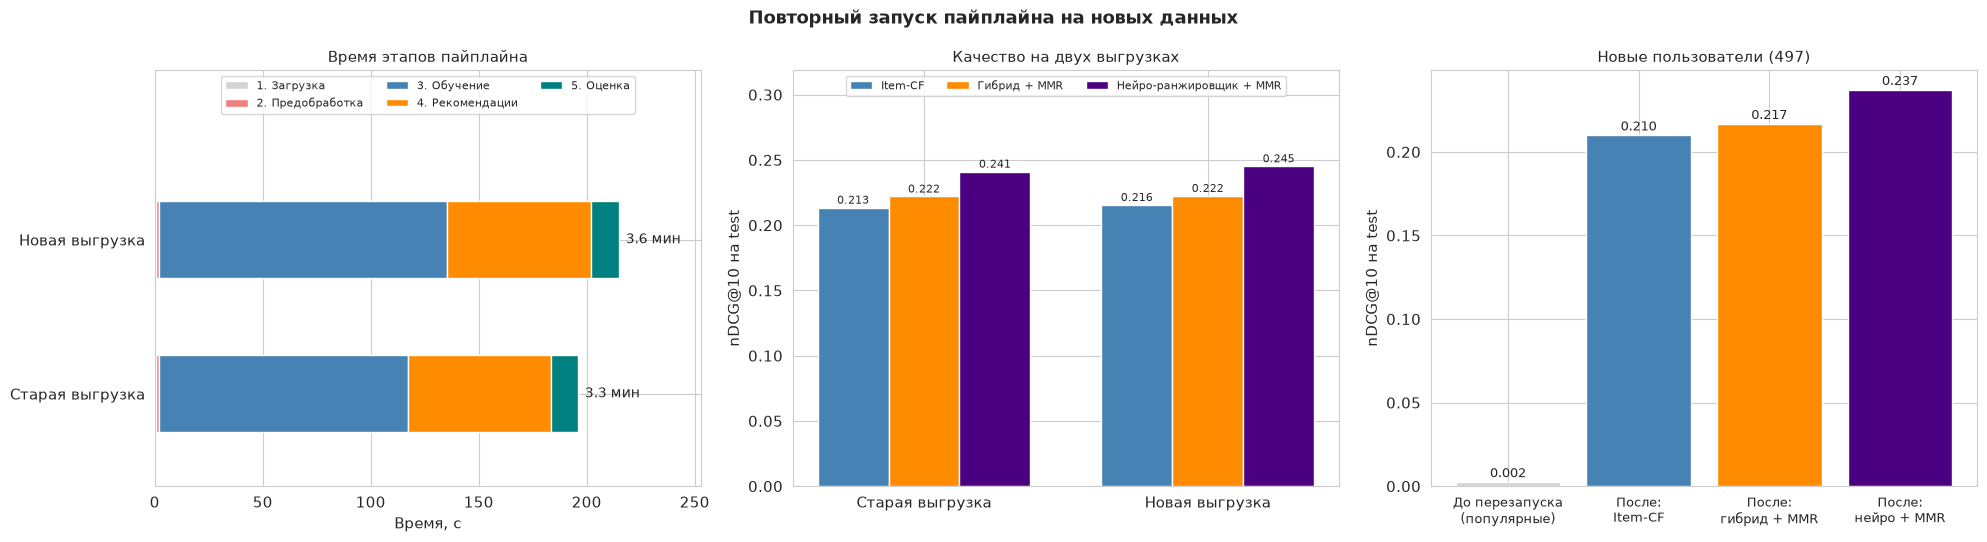

In [51]:
# Сравнение запусков, проверка воспроизводимости и эффект перезапуска для новых пользователей
pipeline_methods = list(run_new['metrics'].index)

# 1. На полной выгрузке разбиение и модели те же, что в разделах 2-5: сравниваю с ними на тех же пользователях test
test_row_of_user = pd.Series(np.arange(len(test_pool['user_ids'])), index=test_pool['user_ids'])
same_rows = test_row_of_user.loc[run_new['eval_user_ids']].values
print(f"Проверка на {len(same_rows)} пользователях test новой выгрузки, nDCG@10:")
print(f"  {'Модель':<26} {'пайплайн':>9} {'разделы 5-6':>12}")
for method_name in pipeline_methods:
    pipeline_value = run_new['per_user_metrics'][method_name]['ndcg'].mean()
    notebook_value = test_metrics[method_name]['ndcg'][same_rows].mean()
    print(f"  {method_name:<26} {pipeline_value:>9.4f} {notebook_value:>12.4f}")
print()

# 2. Новые пользователи в оценке новой выгрузки. До перезапуска у системы не было их оценок,
# поэтому они получали популярные книги. После перезапуска - персональные рекомендации
is_new_user = np.isin(run_new['eval_user_ids'], new_user_ids)
popular_before = top_n_books(run_old['models']['popularity_score'], np.array([], dtype=int), 10)
popular_ndcg = []
for user_id in run_new['eval_user_ids'][is_new_user]:
    popular_ndcg.append(ndcg_at_k(popular_before, run_new['test_relevant'][user_id], 10))
new_user_ndcg = {'До перезапуска (популярные книги)': np.mean(popular_ndcg)}
for method_name in pipeline_methods:
    new_user_ndcg[f"После: {method_name}"] = run_new['per_user_metrics'][method_name]['ndcg'][is_new_user].mean()
print(f"Новых пользователей среди оцениваемых: {is_new_user.sum()}")
for label, value in new_user_ndcg.items():
    print(f"  {label:<38} nDCG@10 = {value:.4f}")

# 3. График: время этапов, качество двух запусков и новые пользователи
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
stage_names = list(run_new['timings'].keys())
stage_colors = ['lightgray', 'lightcoral', 'steelblue', 'darkorange', 'teal']
run_labels = ['Старая выгрузка', 'Новая выгрузка']
run_results = [run_old, run_new]
for run_index in range(2):
    left = 0.0
    for stage_index, stage_name in enumerate(stage_names):
        seconds = run_results[run_index]['timings'][stage_name]
        label = None
        if run_index == 0:
            label = stage_name
        axes[0].barh(run_index, seconds, left=left, height=0.5, color=stage_colors[stage_index], edgecolor='white',
                     label=label)
        left += seconds
    axes[0].text(left + 3, run_index, f"{left / 60:.1f} мин", va='center', fontsize=10)
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(run_labels)
axes[0].set_xlabel('Время, с')
axes[0].set_xlim(0, axes[0].get_xlim()[1] * 1.12)
axes[0].set_ylim(-0.6, 2.1)
axes[0].set_title('Время этапов пайплайна', fontsize=11)
axes[0].legend(fontsize=8, loc='upper center', ncol=3)

method_colors = ['steelblue', 'darkorange', 'indigo']
bar_width = 0.25
for method_index, method_name in enumerate(pipeline_methods):
    values = [run_old['metrics'].loc[method_name, 'nDCG@10'], run_new['metrics'].loc[method_name, 'nDCG@10']]
    positions = np.arange(2) + (method_index - 1) * bar_width
    axes[1].bar(positions, values, width=bar_width, color=method_colors[method_index], edgecolor='white',
                label=method_name)
    for i in range(2):
        axes[1].text(positions[i], values[i] + 0.003, f"{values[i]:.3f}", ha='center', fontsize=8)
axes[1].set_xticks(np.arange(2))
axes[1].set_xticklabels(run_labels)
axes[1].set_ylabel('nDCG@10 на test')
axes[1].set_ylim(0, max(run_new['metrics']['nDCG@10'].max(), run_old['metrics']['nDCG@10'].max()) * 1.3)
axes[1].set_title('Качество на двух выгрузках', fontsize=11)
axes[1].legend(fontsize=8, loc='upper center', ncol=3)

new_labels = list(new_user_ndcg.keys())
new_values = list(new_user_ndcg.values())
axes[2].bar(np.arange(len(new_labels)), new_values, color=['lightgray'] + method_colors, edgecolor='white')
for i in range(len(new_values)):
    axes[2].text(i, new_values[i] + 0.003, f"{new_values[i]:.3f}", ha='center', fontsize=9)
short_labels = ['До перезапуска\n(популярные)', 'После:\nItem-CF', 'После:\nгибрид + MMR', 'После:\nнейро + MMR']
axes[2].set_xticks(np.arange(len(new_labels)))
axes[2].set_xticklabels(short_labels, fontsize=9)
axes[2].set_ylabel('nDCG@10 на test')
axes[2].set_title(f"Новые пользователи ({is_new_user.sum()})", fontsize=11)

plt.suptitle('Повторный запуск пайплайна на новых данных', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'pipeline_runs.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Пайплайн повторно запускается на новых данных и повторяет результаты ноутбука

- **Один и тот же вызов отработал на обеих выгрузках:** 3.3 минуты на старой и 3.6 минуты на новой. Почти всё время уходит на обучение и рекомендации, точнее на пулы кандидатов: для каждого пользователя скоры пяти моделей считаются по всем 10 000 книгам.
- **Пайплайн повторяет ноутбук:** на полной выгрузке Item-CF и гибрид + MMR дали на тех же 5 000 пользователях test ровно те же nDCG@10, что в разделах 5-6 (0.2155 и 0.2225). Значит, этапы собраны правильно. Ранжировщик в пайплайне учится на 6 400 пользователях вместо 12 000, поэтому он немного слабее: 0.2452 против 0.2467 у ранжировщика из раздела 6 на тех же пользователях.
- **Выводы не зависят от выгрузки:** на обеих порядок одинаковый, нейро-ранжировщик + MMR лучше гибрида + MMR, а тот лучше Item-CF. Ранжировщик выигрывает у Item-CF 12.9% на старой выгрузке и 13.8% на новой. Покрытие каталога у него на обеих ниже, чем у гибрида + MMR (около 82% против 85%), как и в разделе 6.
- **Зачем вообще перезапускать:** 497 новых пользователей среди оцениваемых до перезапуска были для системы холодными и получали одни и те же популярные книги, nDCG@10 = 0.002. После перезапуска их оценки попали в обучение, и они получают персональные рекомендации с nDCG@10 = 0.237. Это почти столько же, сколько в среднем по всем пользователям (0.245).
- Результаты второго запуска сохранены на диск, в папку `pipeline_output`: таблица рекомендаций, метрики и веса ранжировщика вместе со средними и разбросами признаков для стандартизации.

### 7.3 Рекомендации через пайплайн

Последний шаг сквозного процесса - выдача рекомендаций конкретному пользователю. Показываю его на новом пользователе: до перезапуска пайплайна система о нём ничего не знает, после - уже учитывает его оценки.

In [52]:
# Рекомендации через пайплайн для одного нового пользователя: до и после перезапуска
# Беру первого по номеру нового пользователя, у которого в новой выгрузке не меньше 20 оценок в train
# и хотя бы 3 понравившиеся книги в test
demo_new_user_id = None
for user_id in new_user_ids:
    n_history = run_new['user_features']['user_n_ratings'].values[user_id - 1]
    if n_history >= 20 and user_id in run_new['test_relevant'].index:
        if len(run_new['test_relevant'][user_id]) >= 3:
            demo_new_user_id = int(user_id)
            break

history_row = run_new['models']['user_item'][demo_new_user_id - 1]
history_order = np.argsort(-history_row.data, kind='stable')[:5]
print(f"Пользователь {demo_new_user_id}. Оценок в train: в старой выгрузке 0, в новой {history_row.nnz}")
print("Лучше всего оценил:")
for position, rating in zip(history_row.indices[history_order], history_row.data[history_order]):
    print(f"  {int(rating)}  {book_info.loc[position + 1, 'title'][:70]}")
print()

demo_liked = run_new['test_relevant'][demo_new_user_id]
list_before = pipeline_recommend(run_old, demo_new_user_id)
list_after = pipeline_recommend(run_new, demo_new_user_id)
demo_comparison = pd.DataFrame({
    'до перезапуска': list_before['title'].str[:42].values,
    'понравилась (до)': list_before['book_id'].isin(demo_liked).values,
    'после перезапуска': list_after['title'].str[:42].values,
    'источник': list_after['источник'].values,
    'понравилась (после)': list_after['book_id'].isin(demo_liked).values,
})
print(f"Понравившихся книг в test: {len(demo_liked)}. Попаданий: до перезапуска {list_before['book_id'].isin(demo_liked).sum()}, "
      f"после {list_after['book_id'].isin(demo_liked).sum()}")
display(demo_comparison)

Пользователь 119. Оценок в train: в старой выгрузке 0, в новой 43
Лучше всего оценил:
  5  My Sister's Grave (Tracy Crosswhite #1)
  5  Into the Darkest Corner
  5  The Kind Worth Killing
  5  Sister
  5  You (You, #1)

Понравившихся книг в test: 11. Попаданий: до перезапуска 0, после 1


,до перезапуска,понравилась (до),после перезапуска,источник,понравилась (после)
0,ESV Study Bible,False,"Splendor (Luxe, #4)",Item-CF,True
1,"Harry Potter Boxed Set, Books 1-5 (Harry P",False,Don't You Cry,"Item-CF, Content-based",False
2,The Revenge of the Baby-Sat,False,"Hidden Bodies (You, #2)",Content-based,False
3,The Indispensable Calvin and Hobbes,False,Who Do You Love,"Item-CF, PureSVD",False
4,Attack of the Deranged Mutant Killer Monst,False,Afterwards,Content-based,False
5,There's Treasure Everywhere: A Calvin and,False,Those Girls,Content-based,False
6,The Days Are Just Packed: A Calvin and Hob,False,Bittersweet,Item-CF,False
7,A Court of Mist and Fury (A Court of Thorn,False,These Things Hidden,Item-CF,False
8,"Harry Potter Collection (Harry Potter, #1-",False,Ladies' Night,Item-CF,False
9,The Authoritative Calvin and Hobbes: A Cal,False,What She Knew,"Item-CF, Content-based, PureSVD",False


#### После перезапуска рекомендации нового пользователя становятся персональными

- Пользователь 119 читает психологические триллеры и детективы. В старой выгрузке его нет, поэтому пайплайн выдал ему список нового пользователя: книги с самым высоким средним рейтингом (ESV Study Bible, Harry Potter, Calvin and Hobbes). Ни одна из 11 понравившихся ему книг test в этот список не попала.
- После перезапуска список собран по его истории. Почти все книги - психологические триллеры и детективы, как и то, что он читает. Hidden Bodies - вторая книга серии You, первую он оценил на 5. Попадание одно: Splendor, четвёртая книга серии Luxe, вторую и третью книги которой он оценил на 5 и 4.
- В этом и смысл сквозного пайплайна: когда появляются новые данные, один вызов `run_pipeline` переобучает всю систему, а `pipeline_recommend` сразу выдаёт рекомендации по обновлённым моделям. Ограничение одно: каталог книг должен остаться тем же, иначе нужно запустить ноутбук целиком. Новые id пользователей ограничением не являются, это проверено в разделе 7.4.

### 7.4 Новые пользователи с новыми id

В разделе 7.2 новые пользователи моделировались так: их не было в старой выгрузке, а в новой они появлялись со своими прежними номерами. В реальном сервисе новый пользователь получает новый id, больше всех прежних. Пайплайн строит матрицы по номерам пользователей (строка матрицы = `user_id - 1`) и берёт число строк из самих данных, поэтому новые номера просто добавляют строки. Проверяю это: новым пользователям из раздела 7.2 даю номера после последнего старого и передаю такую выгрузку в `run_pipeline` таблицей. Чтобы запуск шёл быстрее, для ранжировщика беру 3 000 пользователей validation (из них 600 отложены), а качество оцениваю на 2 000 пользователях test.

In [53]:
# Запуск 3: новые пользователи приходят с новыми id, которых нет в данных ноутбука.
# В базе данных новый пользователь обычно получает следующий свободный номер. Так и моделирую:
# новые пользователи из раздела 7.2 получают номера после последнего старого (53 424)
new_id_of_user = pd.Series(np.arange(n_users + 1, n_users + 1 + len(new_user_ids)), index=new_user_ids)
ratings_new_ids = ratings.copy()
is_new_user_rating = ratings_new_ids['user_id'].isin(new_user_ids)
ratings_new_ids.loc[is_new_user_rating, 'user_id'] = new_id_of_user.loc[
    ratings_new_ids.loc[is_new_user_rating, 'user_id']].values
print(f"Наибольший id пользователя: в ноутбуке {n_users}, в этой выгрузке {ratings_new_ids['user_id'].max()}")
print()

# Чтобы запуск шёл быстрее, беру меньше пользователей для обучения ранжировщика и для оценки
small_config = PIPELINE_CONFIG.copy()
small_config['ranker_users'] = 3000
small_config['eval_users'] = 2000
print("Запуск 3. Новые пользователи с новыми id")
run_new_ids = run_pipeline(DATA_DIR, small_config, ratings_df=ratings_new_ids)
display(run_new_ids['metrics'].round(4))

# Пользователь из раздела 7.3 под новым id получает персональные рекомендации
demo_new_id = int(new_id_of_user.loc[demo_new_user_id])
list_new_id = pipeline_recommend(run_new_ids, demo_new_id)
print(f"Пользователь {demo_new_user_id} под новым id {demo_new_id}: "
      f"попаданий в его понравившиеся книги test {list_new_id['book_id'].isin(demo_liked).sum()} из 10")
display(list_new_id.head(5))

# Пользователь, которого нет в данных запуска, получает популярные книги, а не ошибку
unknown_user_id = int(ratings_new_ids['user_id'].max()) + 1
list_unknown = pipeline_recommend(run_new_ids, unknown_user_id)
print(f"Неизвестный пользователь {unknown_user_id}: источник '{list_unknown['источник'].iloc[0]}', "
      f"первая книга - {list_unknown['title'].iloc[0]}")


Наибольший id пользователя: в ноутбуке 53424, в этой выгрузке 58766

Запуск 3. Новые пользователи с новыми id


[1/5] Загрузка: 979478 оценок, 53424 пользователей (наибольший id 58766), 10000 книг, каталог совпадает с ноутбуком (1 с)


[2/5] Предобработка: train_fit 626865, valid 156717, test 195896 оценок. Пользователей для оценки: valid 30935, test 34288 (1 с)


[3/5] Обучение: 5 базовых моделей на train_fit и train_full, ранжировщик на 2400 пользователях (отложено 600), лучшая эпоха 10, nDCG@10 отложенных 0.1680 (66 с)


[4/5] Рекомендации: top-10 для 2000 пользователей test (32 с)


[5/5] Оценка (5 с)
Весь пайплайн: 1.8 мин


,Precision@10,Recall@10,nDCG@10,ILD,"покрытие каталога, %"
Модель,,,,,
Item-CF,0.0854,0.2399,0.2138,0.7378,65.85
Гибрид + MMR,0.0889,0.2509,0.2246,0.7769,68.45
Нейро-ранжировщик + MMR,0.0945,0.2701,0.2353,0.7899,67.18


Пользователь 119 под новым id 53435: попаданий в его понравившиеся книги test 1 из 10


,book_id,title,источник
0,8206,"Splendor (Luxe, #4)",Item-CF
1,5726,Don't You Cry,"Item-CF, Content-based"
2,7698,Ladies' Night,Item-CF
3,3401,Who Do You Love,"Item-CF, PureSVD"
4,8803,Afterwards,Content-based


Неизвестный пользователь 58767: источник 'Popularity (новый пользователь)', первая книга - ESV Study Bible


#### Пайплайн принимает пользователей с новыми id

- Выгрузка, где 5 342 новых пользователя получили номера с 53 425 по 58 766, прошла через тот же `run_pipeline` без ошибок: матрицы стали на 5 342 строки больше. Пайплайн проверяет только каталог книг, а номера пользователей ограничены лишь памятью: строк в матрицах столько, каков наибольший id.
- Качество на 2 000 пользователях test того же порядка, что в разделе 7.2: нейро-ранжировщик + MMR 0.2353, гибрид + MMR 0.2246, Item-CF 0.2138. Ранжировщик здесь слабее, потому что учится всего на 2 400 пользователях, а покрытие каталога ниже потому, что в оценке меньше пользователей. Сравнивать эти числа с разделом 7.2 напрямую нельзя, запуск нужен как проверка работоспособности.
- Пользователь 119 под новым id 53 435 получает персональные рекомендации, и в них снова есть попадание Splendor. Пользователь с id, которого нет в данных запуска, получает популярные книги, а не ошибку.

## 8. Выводы

Свожу результаты всех разделов: общая таблица подходов, их сильные и слабые стороны, рекомендации по выбору модели и что было сделано. Все метрики посчитаны на том же test, что в ДЗ (34 288 пользователей), а все настройки подбирались только на validation.

### 8.1 Сводное сравнение всех подходов

Все подходы на test (точность - 34 288 пользователей, разнообразие и покрытие - 5000):


,P@10,R@10,nDCG@10,"к Item-CF, %",nDCG@10 (1-4),nDCG@10 (5-19),nDCG@10 (20+),ILD,доля одной серии,"покрытие, %"
Модель,,,,,,,,,,
Popularity,0.0006,0.0017,0.0012,-99.5,0.0011,0.0012,0.0012,0.7127,0.1994,0.2
SVD,0.0006,0.0017,0.0011,-99.5,0.0008,0.0009,0.0015,0.8157,0.0253,3.5
PureSVD,0.0258,0.0397,0.0389,-81.9,0.0030,0.0174,0.0911,0.6084,0.4824,24.0
Content-based,0.0559,0.1691,0.1413,-34.4,0.1268,0.1393,0.1539,0.6263,0.2827,75.7
Item-CF,0.0817,0.2502,0.2154,0.0,0.1929,0.2175,0.2285,0.7370,0.3086,83.1
Item-CF + MMR,0.0834,0.2544,0.2188,1.6,0.1934,0.2215,0.2333,0.7822,0.2193,85.0
Гибрид (веса на глаз),0.0804,0.2454,0.2119,-1.6,0.1906,0.2128,0.2258,0.7117,0.3162,83.2
Гибрид (подобранные веса),0.0826,0.2524,0.2177,1.1,0.1936,0.2184,0.2340,0.7133,0.3161,83.1
Гибрид + MMR,0.0856,0.2602,0.2236,3.8,0.1940,0.2248,0.2432,0.7776,0.1933,85.3


Новые пользователи без истории (376): Popularity nDCG@10 = 0.0059


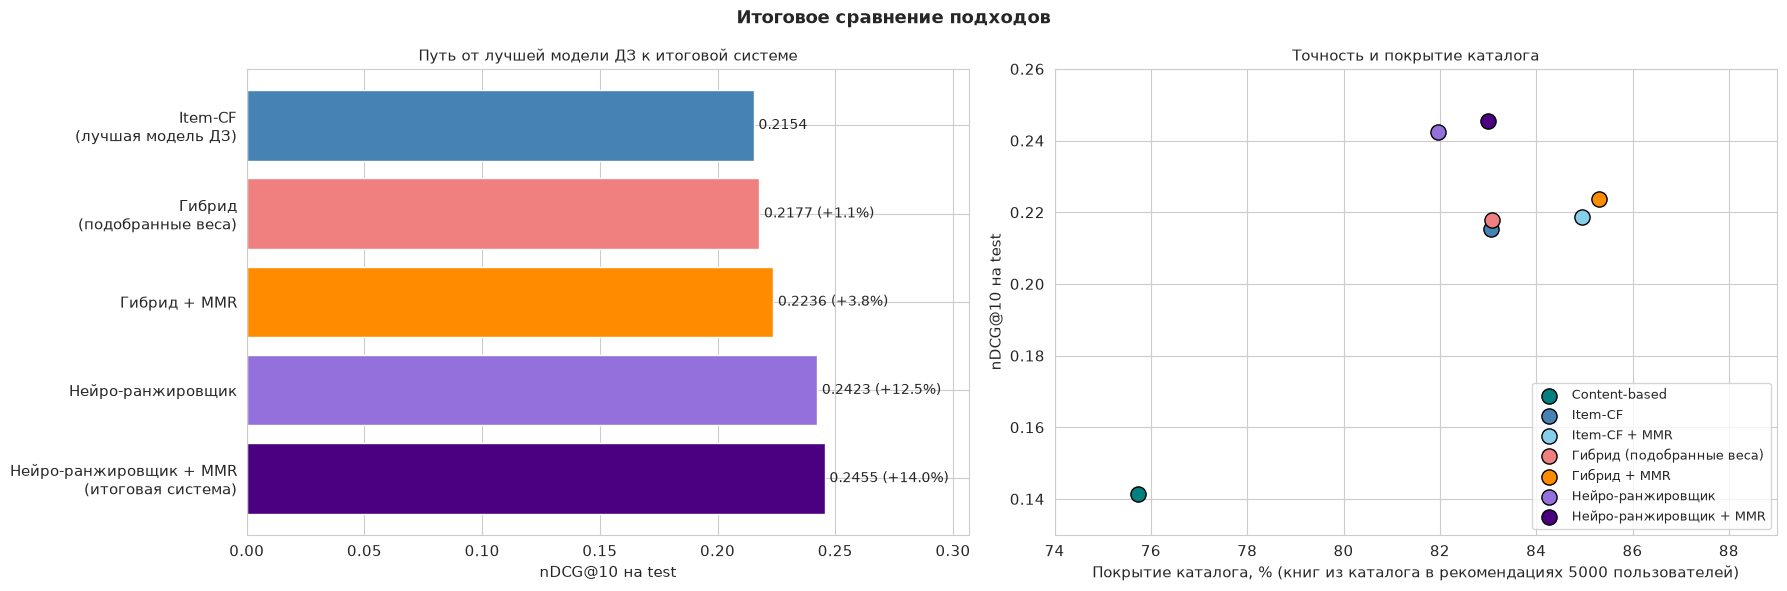

In [54]:
# Сводная таблица всех подходов на test: точность, точность по сегментам, разнообразие и покрытие каталога
summary_methods = ['Popularity', 'SVD', 'PureSVD', 'Content-based', 'Item-CF', 'Item-CF + MMR',
                   'Гибрид (веса на глаз)', 'Гибрид (подобранные веса)', 'Гибрид + MMR',
                   'Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']
segment_short_names = ['1-4', '5-19', '20+']
item_cf_ndcg = hybrid_comparison.loc['Item-CF', 'nDCG@10']

summary_rows = []
for method_name in summary_methods:
    # Нейро-ранжировщик есть только в таблице раздела 6, остальные методы - в таблице раздела 5
    if method_name in final_comparison.index:
        source_table = final_comparison
    else:
        source_table = hybrid_comparison
    row = {'Модель': method_name}
    row['P@10'] = source_table.loc[method_name, 'Precision@10']
    row['R@10'] = source_table.loc[method_name, 'Recall@10']
    row['nDCG@10'] = source_table.loc[method_name, 'nDCG@10']
    row['к Item-CF, %'] = (row['nDCG@10'] - item_cf_ndcg) / item_cf_ndcg * 100
    for segment_index in range(len(segment_short_names)):
        segment_mask = test_pool_segments == USER_SEGMENT_NAMES[segment_index + 1]
        row[f'nDCG@10 ({segment_short_names[segment_index]})'] = test_metrics[method_name]['ndcg'][segment_mask].mean()
    row['ILD'] = source_table.loc[method_name, 'ILD']
    row['доля одной серии'] = source_table.loc[method_name, 'доля одной серии']
    row['покрытие, %'] = source_table.loc[method_name, 'покрытие каталога, %']
    summary_rows.append(row)
summary_table = pd.DataFrame(summary_rows).set_index('Модель')

rounding = {}
for column in summary_table.columns:
    rounding[column] = 4
rounding['к Item-CF, %'] = 1
rounding['покрытие, %'] = 1
print("Все подходы на test (точность - 34 288 пользователей, разнообразие и покрытие - 5000):")
display(summary_table.round(rounding))
print(f"Новые пользователи без истории ({len(cold_user_ids)}): Popularity nDCG@10 = {np.mean(cold_ndcg):.4f}")

# График: путь от лучшей модели ДЗ к итоговой системе и компромисс точности и покрытия каталога
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
path_methods = ['Item-CF', 'Гибрид (подобранные веса)', 'Гибрид + MMR', 'Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']
path_labels = ['Item-CF\n(лучшая модель ДЗ)', 'Гибрид\n(подобранные веса)', 'Гибрид + MMR', 'Нейро-ранжировщик',
               'Нейро-ранжировщик + MMR\n(итоговая система)']
path_colors = ['steelblue', 'lightcoral', 'darkorange', 'mediumpurple', 'indigo']
path_positions = np.arange(len(path_methods))[::-1]
path_values = summary_table.loc[path_methods, 'nDCG@10'].values
axes[0].barh(path_positions, path_values, color=path_colors, edgecolor='white')
for i in range(len(path_methods)):
    gain = summary_table.loc[path_methods[i], 'к Item-CF, %']
    label = f"{path_values[i]:.4f}"
    if i > 0:
        label = f"{path_values[i]:.4f} ({gain:+.1f}%)"
    axes[0].text(path_values[i] + 0.002, path_positions[i], label, va='center', fontsize=10)
axes[0].set_yticks(path_positions)
axes[0].set_yticklabels(path_labels)
axes[0].set_xlim(0, path_values.max() * 1.25)
axes[0].set_xlabel('nDCG@10 на test')
axes[0].set_title('Путь от лучшей модели ДЗ к итоговой системе', fontsize=11)

tradeoff_methods = ['Content-based', 'Item-CF', 'Item-CF + MMR', 'Гибрид (подобранные веса)', 'Гибрид + MMR',
                    'Нейро-ранжировщик', 'Нейро-ранжировщик + MMR']
tradeoff_colors = ['teal', 'steelblue', 'skyblue', 'lightcoral', 'darkorange', 'mediumpurple', 'indigo']
# Точки близко друг к другу, поэтому подписываю их легендой, а не текстом рядом с точкой
for i, method_name in enumerate(tradeoff_methods):
    x = summary_table.loc[method_name, 'покрытие, %']
    y = summary_table.loc[method_name, 'nDCG@10']
    axes[1].scatter(x, y, s=120, color=tradeoff_colors[i], edgecolor='black', zorder=3, label=method_name)
axes[1].legend(fontsize=9, loc='lower right')
axes[1].set_xlim(74, 89)
axes[1].set_ylim(0.13, 0.26)
axes[1].set_xlabel('Покрытие каталога, % (книг из каталога в рекомендациях 5000 пользователей)')
axes[1].set_ylabel('nDCG@10 на test')
axes[1].set_title('Точность и покрытие каталога', fontsize=11)

plt.suptitle('Итоговое сравнение подходов', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'summary_all_methods.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Как читать итоговое сравнение

- **Подходы делятся на три уровня.** Popularity и SVD в одиночку на уровне случайного выбора (nDCG@10 около 0.001). PureSVD и Content-based - слабые персональные модели (0.039 и 0.141). Item-CF и всё, что построено на её основе, - от 0.212 до 0.246. Главный сигнал в данных - "что читают одни и те же люди", и без Item-CF хорошей системы не получается.
- **Путь от ДЗ к итоговой системе:** MMR на одной Item-CF даёт +1.6% к Item-CF, подбор весов гибрида +1.1%, гибрид с MMR +3.8%, ранжировщик на признаках +12.5%, ранжировщик с MMR +14.0%. Самый большой шаг - замена взвешенного усреднения обучаемым ранжировщиком. Около 60% выигрыша ранжировщика над гибридом дают признаки, около 40% - нелинейность сети (раздел 6.5).
- **Метрики согласованы:** Precision@10, Recall@10 и nDCG@10 упорядочивают подходы одинаково, поэтому выводы не зависят от выбора метрики. Итоговая система в среднем угадывает почти одну книгу из десяти (Precision@10 = 0.096) и находит 29% понравившихся книг test (Recall@10 = 0.287). Это оценка снизу: в test только 20% оценок пользователя, и книга, которую он не читал, считается промахом, даже если могла бы понравиться.
- **Разнообразие и точность здесь не конкурируют.** Высокое ILD у SVD и Popularity не достоинство: это почти одинаковые для всех списки "общепризнанных" книг. Среди точных подходов разнообразнее всего списки с MMR (ILD 0.791 у итоговой системы, 0.782 у Item-CF + MMR и 0.778 у гибрида + MMR), а доля томов одной серии падает с 0.31 у Item-CF до 0.19-0.23. ILD считается по той же TF-IDF-схожести, которую штрафует MMR, поэтому надёжнее смотреть на долю одной серии и покрытие каталога.
- **Покрытие каталога** (правый график) у всех точных подходов в узком диапазоне 82-85%. Итоговая система покрывает 83.0% каталога, как Item-CF, а гибрид + MMR и Item-CF + MMR - чуть больше (85.3% и 85.0%). Заметного компромисса между точностью и покрытием здесь нет.
- **Сегменты:** у всех персональных подходов качество растёт с длиной истории. Взвешенный гибрид почти не помогает пользователям с 1-4 оценками (0.194 против 0.193 у Item-CF), а ранжировщик даёт им +9.3% (0.211).

### 8.2 Сильные и слабые стороны методов

| Подход | Сильные стороны | Слабые стороны |
|---|---|---|
| **Popularity** | Работает без истории, единственный вариант для нового пользователя. Простая и быстрая | Один список для всех: nDCG@10 = 0.001 на test и 0.006 у новых пользователей, покрытие 0.2% каталога. У книг этой версии датасета почти одинаковое число оценок (до 100), поэтому популярность по нашим оценкам почти ничего не говорит. Вес 0.05 в гибриде на test ничего не меняет |
| **Content-based (TF-IDF)** | Нужны только описание книги и история самого пользователя. Находит книги тех же жанров, авторов и серий. 4.1% понравившихся книг test в пул приносит только она, поэтому в гибриде у неё вес 0.3 | В 1.5 раза слабее Item-CF (0.141). Списки однотипнее, чем у Item-CF (ILD 0.626 против 0.737). Зависит от качества тегов |
| **Item-CF** | Лучшая одиночная модель (0.215), главный сигнал данных. Понятное объяснение: "потому что вы читали X". Основа пула кандидатов и самые важные признаки ранжировщика. С MMR даёт 0.219 при одном параметре | Без истории не работает, при 1-4 оценках слабее (0.193). Много томов одной серии: 31% книг списка. Сдвиг к популярным книгам |
| **SVD (surprise)** | Прогноз оценки помогает отличить книги, которые понравятся, от прочитанных без удовольствия (AUC 0.63 внутри пользователя, раздел 3.4). В гибриде полезна с весом 0.2 | В одиночку top-N на уровне случайного (0.001): высоко оценивает книги, которые пользователь вряд ли станет читать. Высокий общий AUC (0.76) во многом даёт смещение пользователя `b_u`: внутри пользователя прогноз SVD уступает прогнозу Item-CF (0.63 против 0.65) |
| **PureSVD** | Учится на факте "прочитал", поэтому ищет то, что человек прочитает. У активных пользователей заметно лучше (0.091). Обучается за секунду | При короткой истории почти бесполезна (0.003). В гибриде вес 0. Почти половина списка - тома одной серии (0.48), покрытие 24% |
| **Взвешенный гибрид** | Простой и прозрачный: веса можно объяснить. С подобранными весами лучше Item-CF (+1.1%), с MMR лучше Item-CF + MMR на 2.2% | Веса "на глаз" хуже Item-CF (-1.6%), без подбора на validation гибрид вредит. Одни веса для всех пар (пользователь, книга). Пользователям с 1-4 оценками почти ничего не даёт |
| **MMR** | Почти бесплатно повышает и разнообразие, и точность: +1.6% к одной Item-CF, +2.7% к гибриду, доля томов одной серии у гибрида 0.316 -> 0.193. Один параметр | Lambda приходится подбирать под каждую модель (0.6 для гибрида, 0.7 для Item-CF и ранжировщика). При слишком сильном штрафе точность падает: при lambda = 0.4 nDCG@10 гибрида на validation 0.152 против 0.167 |
| **Нейро-ранжировщик** | Лучший по точности: +14.0% к Item-CF, +12.2% к Item-CF + MMR и +9.8% к гибриду + MMR. Выигрыш во всех сегментах, в том числе при короткой истории. На тех же признаках лучше логистической регрессии на 4.1%. Покрытие каталога на уровне Item-CF. Маленький (3 841 параметр), учится около минуты на CPU | Без признаков раздела 3 хуже взвешенного гибрида (0.209 против 0.218). Признаки нужно проверять на утечки: число оценок книги в train пришлось исключить (раздел 6.1). Не найдёт книгу, которой нет в пуле. Нужны validation для обучения, регулярное переобучение, и решение сложнее объяснить |
| **Общий пул кандидатов** | Находит 46% понравившихся книг test против 39% у top-50 одной Item-CF. Позволяет ранжировать любую комбинацию моделей быстро и векторно | Задаёт потолок качества: 54% понравившихся книг в пул не попадают, и никакой ранжировщик их не вернёт |

### 8.3 Рекомендации по выбору моделей

**По типу пользователя:**

| Пользователь | Что использовать | Почему |
|---|---|---|
| Новый (0 оценок) | Popularity | Других сигналов нет. Качество низкое (0.006), поэтому важно быстрее получить первые оценки. Например, спросить любимые жанры при регистрации (в проекте не проверялось) |
| Короткая история (1-4 оценки) | Нейро-ранжировщик + MMR. Если сеть недоступна - Item-CF (MMR здесь почти ничего не даёт, но и не вредит) | Ранжировщик даёт +9.3% к Item-CF, а гибрид + MMR только +0.5% и здесь не оправдывает своей сложности |
| Средняя история (5-19) | Нейро-ранжировщик + MMR. Простые альтернативы - гибрид + MMR или Item-CF + MMR | +12.5%, +3.3% и +1.8% к Item-CF |
| Активный (20+) | Нейро-ранжировщик + MMR | Самый большой выигрыш: +18.6% к Item-CF |

Это уточняет вывод раздела 5.4: тогда без ранжировщика пользователям с 1-4 оценками хватало одной Item-CF. С ранжировщиком персональная модель выигрывает и у них.

**По цели и ограничениям:**
- **Нужна максимальная точность** - нейро-ранжировщик + MMR (0.2455). Его цена - отдельная обучающая выборка, регулярное переобучение и более сложное объяснение рекомендаций.
- **Нужны простота, объяснимость и широта каталога** - гибрид + MMR (0.2236, покрытие 85.3%) или ещё проще Item-CF + MMR (0.2188, покрытие 85.0%). Сеть не нужна, веса и штраф за похожие книги понятны.
- **Минимальный вариант** - Item-CF + MMR. Одна модель и один параметр дают 89% качества итоговой системы (0.2188 из 0.2455), и с неё стоит начинать.
- **SVD не использовать для top-N в одиночку,** только как признак "понравится ли". PureSVD полезна как источник кандидатов, но не для ранжирования.
- **MMR включать всегда,** а lambda подбирать на validation для конкретной модели.
- **Сначала признаки, потом усложнение модели.** На тех же признаках логистическая регрессия даёт +6.9% к взвешенному гибриду, а MLP - ещё +4.1% к ней. Признаки дают больше, но и нейросеть себя оправдывает.
- **Проверять признаки на утечки.** Признак, который зависит от того, как разбиты данные (число оценок книги в train при потолке в 100 оценок), завышает качество на test. Такой признак исключён в разделе 6.1, а заметить его помог AUC ниже 0.5 в разделе 3.4.
- **Регулярно перезапускать пайплайн:** до перезапуска новые пользователи получают популярные книги (0.002), после - персональные рекомендации (0.237).

**Ограничения и что можно улучшить:**
- **Потолок задаёт пул кандидатов:** в нём только 46% понравившихся книг test. Следующий шаг - лучшая генерация кандидатов, например больше кандидатов от Item-CF или отдельная модель для отбора.
- **Покрытие каталога** у всех точных подходов около 83-85%. Поднять его можно меньшим lambda в MMR или отдельным штрафом за книги, которые рекомендуются слишком часто.
- **Холодный старт** решён только популярными книгами. Можно попробовать популярные книги по выбранным жанрам.
- **Разбиение случайное, а не по времени:** в датасете нет дат оценок. Test проверяет, насколько хорошо система угадывает скрытые оценки, а не предсказывает будущее чтение, и в реальном сервисе качество может быть ниже.
- У ранжировщика выбиралась только функция потерь. Размер сети, шаг обучения и число кандидатов не перебирались. Отложенные пользователи validation использовались сразу для ранней остановки, выбора функции потерь и lambda, поэтому оценка на них оптимистична, а выводы сделаны по test.
- Доверительные интервалы учитывают разброс по пользователям, но не случайность обучения сети (зерно фиксировано).
- Пайплайн работает внутри ноутбука (раздел 7.1). Для отдельного сервиса его функции нужно вынести в модуль.

### 8.4 Что было сделано

**Базовая часть:**
1. **Расширенные признаки (этап 1).** 22 признака: пользователя (активность, средний рейтинг, разброс, доля высоких оценок), книги (популярность в выборке и на Goodreads, средний рейтинг, разнообразие оценок, год, серия) и взаимодействия (схожесть с историей по Item-CF и по содержанию, совпадение жанров по 15 тематическим категориям из 177 тегов, серия и автор из истории, скоры моделей). Сегмент пользователя и основная категория книги используются для стратегий и анализа, а не как отдельные признаки. Полезность проверена через ROC AUC внутри пользователя, вклад в качество - сравнением сетей с признаками и без (+15.9%). Число оценок книги в train протекало информацией о test из-за потолка в 100 оценок и в ранжировщик не идёт.
2. **Гибридная система (этап 2).** Общий пул кандидатов от пяти моделей ДЗ без прочитанных книг, взвешенное усреднение z-оценок, разные стратегии для новых и остальных пользователей, популярные книги для новых пользователей, как вес в сумме (на наших данных эффекта не дал) и как добивка списка (страховка), баланс разнообразия и релевантности через MMR.
3. **Оценка и оптимизация (этап 3).** Перебор 858 комбинаций весов на validation, проверка отдельных весов для сегментов кросс-валидацией, подбор lambda. Сравнение на test с отдельными моделями и с Item-CF + MMR (чтобы отделить вклад MMR) с 95% доверительными интервалами, анализ по сегментам пользователей.

**Продвинутая часть:**
4. **Нейросетевой ранжировщик:** MLP на PyTorch, две функции потерь, ранняя остановка, проверка признаков на утечку, интеграция в гибрид вместо взвешенного усреднения, сравнение с классическими методами (взвешенный гибрид и логистическая регрессия на тех же признаках), важность признаков.
5. **Сквозной пайплайн:** функция `run_pipeline` от загрузки данных до оценки качества и сохранения результатов, повторный запуск на новых данных, пользователи с новыми id и выдача рекомендаций через `pipeline_recommend`.

**Итог: лучшая модель ДЗ против итоговой системы на том же test:**

| Метрика | Item-CF (ДЗ) | Нейро-ранжировщик + MMR | Изменение |
|---|---|---|---|
| Precision@10 | 0.0817 | 0.0956 | +17.0% |
| Recall@10 | 0.2502 | 0.2872 | +14.8% |
| nDCG@10 | 0.2154 | 0.2455 | +14.0% |
| ILD (разнообразие) | 0.7370 | 0.7910 | выше, лучше |
| Доля томов одной серии | 0.3086 | 0.2255 | ниже, лучше |
| Покрытие каталога | 83.1% | 83.0% | почти то же |

Итоговая система точнее лучшей модели ДЗ: на 17% по Precision@10, на 15% по Recall@10 и на 14% по nDCG@10. Её списки разнообразнее, покрытие каталога то же, и выигрыш есть в каждом сегменте пользователей с историей. Цена - более сложная система, которую нужно регулярно переобучать. Для этого и нужен сквозной пайплайн.